# Nowcast Lab — Kaggle notebook

Transparent nowcasts and indices from free public and alternative data, with publication-aware timing, baselines first, walk-forward tests and automated look-ahead checks.

| Section | What |
|---|---|
| 1–6 | **Crude Pressure Index** and one-week WTI view (EIA spot prices + Fed dollar rates), backtest vs random walk, look-ahead check |
| 7 | **Alternative data for crude**: tanker traffic, EIA weekly, positioning, retail margins, rig counts, JODI balances, news (experimental) |
| 8 | **Macro**: US **inflation** (CPI) nowcast, **labour** nowcasts (payrolls, unemployment) + Labour Pulse, **market conditions** index |
| 9 | **Combined view**: crude + every alternative-data signal + macro backdrop on one timeline, a scoreboard and a correlation map (`combined_dashboard.html`) |
| 10 | Interactive crude dashboard (`dashboard.html`); macro dashboard is `macro_dashboard.html` |

**Setup:** Settings → Internet **On**. Optional attachments: your JODI dataset, hand-downloaded FRED CSVs (named `<SERIES>.csv`), `bakerhughes_oil_rigs.csv`. For reliable FRED access add a free FRED API key as a Kaggle Secret named `FRED_API_KEY` (Add-ons → Secrets); without it the notebook uses FRED's keyless CSV, which can be slow.

**If you re-import this notebook, use Run → Restart session and run all** (old code can stay cached in memory otherwise).

The first cells write the package to disk (one cell per module), so the code you read is exactly the code that runs.

**Every chart is followed by a written reading** (what it shows, today's value, how the nowcast did against its baseline, and caveats). The text is generated from the numbers of your own run, so it changes with the data.

In [1]:
import os, sys
from pathlib import Path

WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()
os.chdir(WORK)
(WORK / "nowcastlab").mkdir(exist_ok=True)
(WORK / "tests").mkdir(exist_ok=True)
(WORK / "data" / "events").mkdir(parents=True, exist_ok=True)
(WORK / "data" / "raw" / "macro").mkdir(parents=True, exist_ok=True)
os.environ["NOWCAST_RAW_DIR"] = str(WORK / "data" / "raw")
os.environ["NOWCAST_OUT_DIR"] = str(WORK / "outputs")
if str(WORK) not in sys.path:
    sys.path.insert(0, str(WORK))
print("working dir:", WORK)

working dir: /kaggle/working


## 1. Package source

**`nowcastlab/__init__.py`** — Package marker.

In [2]:
%%writefile nowcastlab/__init__.py
"""Nowcast Lab: transparent nowcasts and indices from free data."""

Writing nowcastlab/__init__.py


**`nowcastlab/config.py`** — All methodology choices: sources and their release rules, components, signs, weights, windows.

In [3]:
%%writefile nowcastlab/config.py
"""All tunable choices in one place, so methodology changes are reviewable diffs."""
from dataclasses import dataclass, field

# ---------------------------------------------------------------------------
# Sources (public, no API key). Each source declares WHEN its value for date d
# becomes known. That rule is what the point-in-time join uses.
# ---------------------------------------------------------------------------
GITHUB_DATASETS = "https://raw.githubusercontent.com/datasets"
SOURCES = {
    # EIA spot prices (RWTC, RBRTE), mirrored by datasets/oil-prices on GitHub.
    # Treated as known at the close of date d (exchange settlement is same-day;
    # see README "Assumptions" for why this is an approximation for EIA files).
    "wti":   {"url": f"{GITHUB_DATASETS}/oil-prices/main/data/wti-daily.csv",  "file": "wti_daily.csv",   "release": "same_day"},
    "brent": {"url": f"{GITHUB_DATASETS}/oil-prices/main/data/brent-daily.csv", "file": "brent_daily.csv", "release": "same_day"},
    # Fed H.10 noon buying rates. Published weekly on Monday afternoon for the
    # previous week, i.e. AFTER WTI settles -> usable from the Tuesday close.
    "fx":    {"url": f"{GITHUB_DATASETS}/exchange-rates/main/data/daily.csv",   "file": "fx_h10_daily.csv", "release": "h10_weekly"},
}

# Equal-weight USD basket: foreign currency units per USD (all series in the
# file are quoted that way; higher = stronger dollar).
USD_BASKET = ["Euro", "Japan", "United Kingdom", "Canada", "Switzerland",
              "Australia", "China", "Mexico"]

START = "2000-01-01"          # sample start
MAX_STALE_DAYS = 5            # forward-fill limit when calendars differ (calendar days)


@dataclass(frozen=True)
class Component:
    name: str
    label: str
    sign: int          # +1 => high value is bullish for WTI, -1 => bearish
    weight: float      # fixed a-priori weight in the index
    rationale: str


# The index is deliberately simple: 4 signed, rolling-standardised components,
# equal weights fixed BEFORE looking at backtest results.
COMPONENTS = [
    Component("trend_63d", "Trend (3-month return)", +1, 0.25,
              "Time-series momentum is the most persistent documented effect in "
              "commodity futures (Moskowitz, Ooi & Pedersen 2012)."),
    Component("brent_premium", "Brent premium over WTI", +1, 0.25,
              "An unusually wide Brent-WTI spread means US crude is cheap versus "
              "the seaborne benchmark; arbitrage (exports) tends to close it."),
    Component("usd_20d", "US dollar (1-month change)", -1, 0.25,
              "Oil is priced in USD; a stronger dollar raises the local-currency "
              "cost for non-US buyers and is associated with weaker prices."),
    Component("vol_20d", "Realised volatility (1-month)", -1, 0.25,
              "High-volatility regimes coincide with demand shocks and forced "
              "de-risking; drawdowns cluster there."),
]


@dataclass(frozen=True)
class ModelConfig:
    horizon: int = 5                  # trading days ahead (1 week)
    zscore_window: int = 756          # ~3y trailing window for standardisation
    zscore_min_periods: int = 252
    z_clip: float = 3.0
    percentile_window: int = 756      # index shown as 0-100 vs trailing 3y
    oos_start: str = "2008-01-01"     # first out-of-sample prediction date
    refit: str = "MS"                 # refit at each month start (calendar-deterministic)
    min_train_obs: int = 750
    ridge_alpha: float = 10.0
    interval_q: tuple = (0.10, 0.90)  # empirical 80% prediction interval


CFG = ModelConfig()

Writing nowcastlab/config.py


**`nowcastlab/data.py`** — Fetch → quality checks → point-in-time panel (as-of join on publication date).

In [4]:
%%writefile nowcastlab/data.py
"""Data layer: fetch -> quality checks -> point-in-time daily panel.

Every raw series becomes (obs_date, available_date, value). The panel is built
on the WTI trading calendar and, for each date t, takes the latest value whose
available_date <= t. Nothing downstream ever sees a value before it would have
been published.
"""
from __future__ import annotations

import io
import json
import os
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd

from .config import MAX_STALE_DAYS, SOURCES, START, USD_BASKET

RAW_DIR = Path(os.environ.get("NOWCAST_RAW_DIR",
                              Path(__file__).resolve().parent.parent / "data" / "raw"))


def _find_attached(raw_dir: Path) -> Path | None:
    """Kaggle: use CSVs from an attached dataset under /kaggle/input if present."""
    root = Path("/kaggle/input")
    if not root.exists():
        return None
    for hit in root.rglob(SOURCES["wti"]["file"]):
        if all((hit.parent / s["file"]).exists() for s in SOURCES.values()):
            return hit.parent
    return None

# Per-source staleness limit (calendar days between obs_date and t).
# H.10 is weekly-published, so its freshest usable value can be ~10 days old.
STALE_LIMIT = {"same_day": MAX_STALE_DAYS, "h10_weekly": 14,
               "portwatch_daily": 21, "eia_weekly": 21, "cftc_weekly": 14,
               "retail_weekly": 14, "bh_weekly": 14, "jodi_monthly": 130,
               "cpi_monthly": 130, "jobs_monthly": 130, "claims_weekly": 14, "claims_cont_weekly": 21,
               "fred_daily": 7, "nfci_weekly": 14}
PORTWATCH_LAG_DAYS = 10   # conservative: PortWatch updates weekly; see altdata.py


# --------------------------------------------------------------------- fetch
def fetch_all(raw_dir: Path = RAW_DIR) -> None:
    """Download public CSVs into data/raw (FX trimmed to the basket)."""
    raw_dir.mkdir(parents=True, exist_ok=True)
    for name, src in SOURCES.items():
        with urllib.request.urlopen(src["url"], timeout=60) as r:
            text = r.read().decode()
        if name == "fx":
            df = pd.read_csv(io.StringIO(text), parse_dates=["Date"])
            df = df[df["Country"].isin(USD_BASKET) & (df["Date"] >= "1995-01-01")]
            text = df.to_csv(index=False)
        (raw_dir / src["file"]).write_text(text)


# ---------------------------------------------------------------- load raw
def _load_price(name: str, raw_dir: Path) -> pd.DataFrame:
    df = pd.read_csv(raw_dir / SOURCES[name]["file"])
    df.columns = ["obs_date", "value"]
    df["obs_date"] = pd.to_datetime(df["obs_date"])
    return df.dropna().sort_values("obs_date").reset_index(drop=True)


def _load_fx_basket(raw_dir: Path) -> pd.DataFrame:
    """Equal-weight USD basket as a log index (higher = stronger USD)."""
    fx = pd.read_csv(raw_dir / SOURCES["fx"]["file"], parse_dates=["Date"])
    fx = fx[fx["Country"].isin(USD_BASKET)]
    wide = fx.pivot_table(index="Date", columns="Country", values="Exchange rate")
    wide = wide.where(wide > 0).ffill(limit=3)
    dlog = np.log(wide).diff()
    basket = dlog.mean(axis=1, skipna=True).fillna(0.0).cumsum()
    out = basket.rename("value").reset_index().rename(columns={"Date": "obs_date"})
    out["n_ccy"] = wide.notna().sum(axis=1).values
    return out


def load_raw(raw_dir: Path = RAW_DIR) -> dict[str, pd.DataFrame]:
    """Local cache if present; otherwise a fresh download (so scheduled Kaggle
    runs always get the latest data); otherwise an attached Kaggle dataset."""
    if not (raw_dir / SOURCES["wti"]["file"]).exists():
        try:
            fetch_all(raw_dir)
        except OSError as e:
            for s in SOURCES.values():          # no half-downloaded cache
                (raw_dir / s["file"]).unlink(missing_ok=True)
            attached = _find_attached(raw_dir)
            if attached is None:
                raise RuntimeError(
                    "No data found. On Kaggle either turn Internet on (Settings > "
                    "Internet) or attach the nowcast-lab-data dataset.") from e
            print("Internet unavailable - using attached dataset (static snapshot).")
            raw_dir = attached
    raw = {k: _load_price(k, raw_dir) for k in ("wti", "brent")}
    raw["fx"] = _load_fx_basket(raw_dir)
    return raw


# ---------------------------------------------------------- release timing
def available_date(obs_date: pd.Series, rule: str) -> pd.Series:
    """Date from whose close the observation may be used."""
    if rule == "same_day":
        return obs_date
    if rule == "h10_weekly":
        # Released Monday ~4:15pm ET for the prior Mon-Fri week. WTI settles
        # 2:30pm ET, so the first close that can use it is Tuesday.
        days_to_next_monday = 7 - obs_date.dt.weekday
        return obs_date + pd.to_timedelta(days_to_next_monday + 1, unit="D")
    if rule == "eia_weekly":
        # Weekly Petroleum Status Report: week ends Friday, released the following
        # Wednesday 10:30 ET (holiday weeks slip a day) -> first safe close is Thursday.
        return obs_date + pd.Timedelta(days=6)
    if rule == "cpi_monthly":
        # BLS CPI for month M comes out around the 10th-15th of M+1; use month end + 17 days.
        return (obs_date + pd.offsets.MonthEnd(0)) + pd.Timedelta(days=17)
    if rule == "jobs_monthly":
        # Employment Situation: first Friday of M+1 (day 1-7); use month end + 8 days.
        return (obs_date + pd.offsets.MonthEnd(0)) + pd.Timedelta(days=8)
    if rule == "claims_weekly":
        # Initial claims, week ending Saturday, released the following Thursday 8:30 ET.
        return obs_date + pd.Timedelta(days=5)
    if rule == "claims_cont_weekly":
        # Continuing claims lag initial claims by one more week.
        return obs_date + pd.Timedelta(days=12)
    if rule == "fred_daily":
        # Daily market series on FRED: usable the next day (conservative).
        return obs_date + pd.Timedelta(days=1)
    if rule == "nfci_weekly":
        # Chicago Fed NFCI: week ending Friday, released the following Wednesday.
        return obs_date + pd.Timedelta(days=5)
    if rule == "cftc_weekly":
        # Positions as of Tuesday, published Friday 3:30pm ET (after the WTI settle) -> Monday close.
        return obs_date + pd.Timedelta(days=6)
    if rule == "retail_weekly":
        # EIA retail gasoline/diesel: Monday price, published Monday afternoon/Tuesday -> Tuesday close.
        return obs_date + pd.Timedelta(days=1)
    if rule == "bh_weekly":
        # Baker Hughes: Friday 1pm ET release; use the following Monday (conservative).
        return obs_date + pd.Timedelta(days=3)
    if rule == "jodi_monthly":
        # JODI month M is published roughly 4-8 weeks after month end and is revised;
        # use month end + 45 days.
        return (obs_date + pd.offsets.MonthEnd(0)) + pd.Timedelta(days=45)
    if rule == "portwatch_daily":
        return obs_date + pd.Timedelta(days=PORTWATCH_LAG_DAYS)
    raise ValueError(rule)


# ----------------------------------------------------------- quality checks
def quality_report(raw: dict[str, pd.DataFrame], as_of: pd.Timestamp) -> pd.DataFrame:
    rows = []
    for name, df in raw.items():
        s = df.set_index("obs_date")["value"]
        is_level = name != "fx"
        r = np.log(s.where(s > 0)).diff() if is_level else s.diff()
        big = r.abs() > (0.25 if is_level else 0.03)
        flags = []
        if s.index.duplicated().any():
            flags.append("duplicate dates")
        if is_level and (s <= 0).any():
            flags.append(f"{int((s <= 0).sum())} non-positive price(s) "
                         f"e.g. {s[s <= 0].index[0].date()} -> excluded from log returns")
        if big.any():
            flags.append(f"{int(big.sum())} daily move(s) beyond threshold, largest "
                         f"{r.abs().idxmax().date()} ({r.abs().max():+.1%})")
        age = (as_of - s.index.max()).days
        if age > STALE_LIMIT[SOURCES[name]["release"]] + 3:
            flags.append(f"latest observation is {age} days old")
        if name == "fx" and (df["n_ccy"].tail(250) < len(USD_BASKET)).any():
            flags.append("some basket currencies missing on recent days (basket uses available ones)")
        rows.append({
            "source": name,
            "release_rule": SOURCES[name]["release"],
            "first_obs": s.index.min().date(),
            "last_obs": s.index.max().date(),
            "n_obs": len(s),
            "missing_values": int(s.isna().sum()),
            "flags": "; ".join(flags) or "ok",
        })
    return pd.DataFrame(rows)


# ------------------------------------------------------ point-in-time panel
def _pit_join(calendar: pd.DatetimeIndex, df: pd.DataFrame, rule: str, col: str) -> pd.DataFrame:
    d = df[["obs_date", "value"]].copy()
    d["available_date"] = available_date(d["obs_date"], rule)
    # Several observations share one release date (a whole H.10 week); sort by
    # obs_date too so as-of picks the LATEST published observation, deterministically.
    d = d.sort_values(["available_date", "obs_date"], kind="stable")
    left = pd.DataFrame({"date": calendar})
    j = pd.merge_asof(left, d, left_on="date", right_on="available_date", direction="backward")
    stale = (j["date"] - j["obs_date"]).dt.days > STALE_LIMIT[rule]
    j.loc[stale, "value"] = np.nan
    return j.set_index("date")[["value", "obs_date"]].rename(
        columns={"value": col, "obs_date": f"{col}_obs_date"})


def build_panel(raw: dict[str, pd.DataFrame], as_of: str | pd.Timestamp | None = None) -> pd.DataFrame:
    """Daily panel on the WTI calendar, using only data available at each date.

    as_of truncates by AVAILABILITY (what we would have known that day), which
    is what the look-ahead test relies on.
    """
    wti = raw["wti"]
    cal = pd.DatetimeIndex(wti.loc[wti["obs_date"] >= START, "obs_date"])
    if as_of is not None:
        as_of = pd.Timestamp(as_of)
        cal = cal[cal <= as_of]
        raw = {k: v[available_date(v["obs_date"], SOURCES[k]["release"]) <= as_of]
               for k, v in raw.items()}
    parts = [_pit_join(cal, raw[k], SOURCES[k]["release"], k) for k in ("wti", "brent", "fx")]
    panel = pd.concat(parts, axis=1)
    panel.index.name = "date"
    return panel


def save_quality_report(qc: pd.DataFrame, path: Path) -> None:
    path.write_text(json.dumps(qc.astype(str).to_dict(orient="records"), indent=2))

Writing nowcastlab/data.py


**`nowcastlab/features.py`** — Components, trailing z-scores, fixed-weight index, forward-return label.

In [5]:
%%writefile nowcastlab/features.py
"""Transformations: raw panel -> component signals -> Crude Pressure Index.

Every operation is backward-looking (rolling windows ending at t, no centring,
no full-sample statistics), so a value at t is identical whether the sample
ends at t or ten years later. tests/test_lookahead.py checks exactly that.
"""
from __future__ import annotations

import numpy as np
import pandas as pd

from .config import CFG, COMPONENTS, ModelConfig


def log_price(s: pd.Series) -> pd.Series:
    return np.log(s.where(s > 0))  # non-positive prices (WTI 2020-04-20) -> NaN


def raw_components(panel: pd.DataFrame) -> pd.DataFrame:
    lw = log_price(panel["wti"])
    lb = log_price(panel["brent"])
    r1 = lw.diff()
    out = pd.DataFrame(index=panel.index)
    out["trend_63d"] = lw - lw.shift(63)
    out["brent_premium"] = lb - lw                      # log Brent/WTI
    out["usd_20d"] = panel["fx"] - panel["fx"].shift(20)
    out["vol_20d"] = r1.rolling(20, min_periods=15).std() * np.sqrt(252)
    return out


def rolling_z(x: pd.DataFrame, cfg: ModelConfig = CFG) -> pd.DataFrame:
    mu = x.rolling(cfg.zscore_window, min_periods=cfg.zscore_min_periods).mean()
    sd = x.rolling(cfg.zscore_window, min_periods=cfg.zscore_min_periods).std()
    return ((x - mu) / sd).clip(-cfg.z_clip, cfg.z_clip)


def build_index(panel: pd.DataFrame, cfg: ModelConfig = CFG) -> pd.DataFrame:
    """Signed z-scores, fixed-weight index, and its trailing percentile (0-100)."""
    z = rolling_z(raw_components(panel), cfg)
    out = pd.DataFrame(index=panel.index)
    for c in COMPONENTS:
        out[f"z_{c.name}"] = c.sign * z[c.name]                 # signed: + = bullish
        out[f"contrib_{c.name}"] = c.weight * out[f"z_{c.name}"]
    contrib = out[[f"contrib_{c.name}" for c in COMPONENTS]]
    out["index"] = contrib.sum(axis=1, min_count=len(COMPONENTS))
    out["index_pct"] = out["index"].rolling(cfg.percentile_window, min_periods=252).rank(pct=True) * 100
    return out


def forward_return(panel: pd.DataFrame, h: int) -> pd.Series:
    """Label: log return of WTI from close t to close t+h (trading days).

    This is the ONLY place future data is touched. It is never used as a
    feature, and training rows are embargoed so a label is only used once
    t+h has actually happened (see model.py).
    """
    lw = log_price(panel["wti"])
    return (lw.shift(-h) - lw).rename(f"fwd_ret_{h}d")

Writing nowcastlab/features.py


**`nowcastlab/model.py`** — Walk-forward models with monthly refits and label embargo.

In [6]:
%%writefile nowcastlab/model.py
"""Walk-forward models that turn the index/components into a 1-week WTI view.

Protocol (identical for every model so the comparison is fair):
  * refit on the first trading day of every month from CFG.oos_start;
  * train on ALL earlier rows whose label is already realised, i.e. rows
    t with t + horizon <= refit date (embargo of `horizon` trading days);
  * predict every day until the next refit with the frozen fit.
Because refit dates are fixed calendar points, a prediction for day t never
depends on data after t -> verified in tests/test_lookahead.py.
"""
from __future__ import annotations

import numpy as np
import pandas as pd

from .config import CFG, COMPONENTS, ModelConfig

Z_COLS = [f"z_{c.name}" for c in COMPONENTS]

# name -> (feature columns, kind). Baselines first.
MODELS = {
    "random_walk":       ([], "zero"),          # no change: the bar to beat
    "historical_drift":  ([], "mean"),          # expanding mean return
    "trend_only":        (["z_trend_63d"], "ols"),
    "index_fixed_weights": (["index"], "ols"),  # the transparent product signal
    "ridge_learned_weights": (Z_COLS, "ridge"), # lets data choose the weights
}


def _fit_predict(Xtr, ytr, Xte, kind, alpha):
    if kind == "zero":
        return np.zeros(len(Xte)), np.zeros(len(ytr)), {}
    if kind == "mean":
        m = float(ytr.mean())
        return np.full(len(Xte), m), np.full(len(ytr), m), {"intercept": m}
    A = np.column_stack([np.ones(len(Xtr)), Xtr])
    pen = np.eye(A.shape[1]) * (alpha if kind == "ridge" else 0.0)
    pen[0, 0] = 0.0                                   # never shrink the intercept
    beta = np.linalg.solve(A.T @ A + pen, A.T @ ytr)
    fitted = A @ beta
    pred = np.column_stack([np.ones(len(Xte)), Xte]) @ beta
    return pred, fitted, {"intercept": beta[0], **{f"b_{i}": b for i, b in enumerate(beta[1:])}}


def walk_forward(feats: pd.DataFrame, y: pd.Series, cfg: ModelConfig = CFG, models=None):
    """Returns (predictions long frame, coefficient log). `models` restricts which entries of MODELS run."""
    chosen = {k: v for k, v in MODELS.items() if models is None or k in models}
    df = feats.join(y.rename("y"))
    dates = df.index
    pos = pd.Series(np.arange(len(dates)), index=dates)
    oos = dates[dates >= cfg.oos_start]
    if len(oos) == 0:
        return pd.DataFrame(), pd.DataFrame()
    month_starts = pd.Series(oos, index=oos).groupby(oos.to_period("M")).first().values
    refits = list(pd.DatetimeIndex(month_starts)) + [dates[-1] + pd.Timedelta(days=1)]

    preds, coefs = [], []
    for start, end in zip(refits[:-1], refits[1:]):
        last_train_pos = pos[start] - cfg.horizon          # embargo
        train = df.iloc[: last_train_pos + 1]
        test = df.loc[(dates >= start) & (dates < end)]
        for name, (cols, kind) in chosen.items():
            tr = train.dropna(subset=cols + ["y"])
            if len(tr) < cfg.min_train_obs:
                continue
            te = test.dropna(subset=cols) if cols else test
            if te.empty:
                continue
            p, fitted, beta = _fit_predict(tr[cols].values, tr["y"].values,
                                           te[cols].values, kind, cfg.ridge_alpha)
            resid = tr["y"].values - fitted
            lo, hi = np.quantile(resid, cfg.interval_q)
            preds.append(pd.DataFrame({"date": te.index, "model": name, "pred": p,
                                       "lo": p + lo, "hi": p + hi, "refit_date": start}))
            if cols:
                named = {"intercept": beta["intercept"]}
                named.update({c: beta[f"b_{i}"] for i, c in enumerate(cols)})
                coefs.append({"refit_date": start, "model": name, "n_train": len(tr), **named})
    return pd.concat(preds, ignore_index=True), pd.DataFrame(coefs)

Writing nowcastlab/model.py


**`nowcastlab/evaluate.py`** — Out-of-sample scoring vs random walk (OOS R², Diebold–Mariano, hit rate, IC).

In [7]:
%%writefile nowcastlab/evaluate.py
"""Out-of-sample scoring against the random-walk baseline."""
from __future__ import annotations

import numpy as np
import pandas as pd
from scipy import stats


def _hac_tstat(d: np.ndarray, lags: int) -> float:
    """Newey-West t-stat of mean(d); lags account for overlapping h-day labels."""
    n = len(d)
    u = d - d.mean()
    s = u @ u / n
    for k in range(1, lags + 1):
        s += 2 * (1 - k / (lags + 1)) * (u[k:] @ u[:-k]) / n
    return float(d.mean() / np.sqrt(s / n)) if s > 0 else np.nan


def score(preds: pd.DataFrame, y: pd.Series, price: pd.Series, horizon: int) -> pd.DataFrame:
    df = preds.merge(y.rename("y"), left_on="date", right_index=True).dropna(subset=["y"])
    p0 = price.reindex(df["date"]).values
    p1 = price.shift(-horizon).reindex(df["date"]).values
    df["p_now"], df["p_fut"] = p0, p1
    rows = []
    for name, g in df.groupby("model", sort=False):
        yv, pv = g["y"].values, g["pred"].values
        sse, sse0 = ((yv - pv) ** 2).sum(), (yv ** 2).sum()
        nonover = g.iloc[::horizon]                      # non-overlapping sample
        ic = stats.spearmanr(nonover["pred"], nonover["y"]).statistic if pv.std() > 0 else np.nan
        hits = np.sign(pv) == np.sign(yv)
        dm = _hac_tstat(yv ** 2 - (yv - pv) ** 2, lags=horizon - 1) if pv.std() > 0 else np.nan
        mae_usd = np.nanmean(np.abs(g["p_now"] * np.exp(pv) - g["p_fut"]))
        cover = np.mean((yv >= g["lo"]) & (yv <= g["hi"]))
        rows.append({
            "model": name,
            "n_days": len(g),
            "oos_r2_vs_rw_%": 100 * (1 - sse / sse0),
            "dm_tstat_vs_rw": dm,
            "hit_rate_%": 100 * hits.mean() if pv.std() > 0 else np.nan,
            "ic_spearman": ic,
            "price_mae_usd": mae_usd,
            "interval_80_coverage_%": 100 * cover,
        })
    return pd.DataFrame(rows)


def score_by_year(preds: pd.DataFrame, y: pd.Series, horizon: int, model: str) -> pd.DataFrame:
    g = preds[preds["model"] == model].merge(y.rename("y"), left_on="date", right_index=True).dropna()
    g["year"] = g["date"].dt.year
    out = []
    for yr, h in g.groupby("year"):
        no = h.iloc[::horizon]
        out.append({"year": yr,
                    "ic_spearman": stats.spearmanr(no["pred"], no["y"]).statistic,
                    "hit_rate_%": 100 * (np.sign(h["pred"]) == np.sign(h["y"])).mean(),
                    "oos_r2_vs_rw_%": 100 * (1 - ((h["y"] - h["pred"]) ** 2).sum() / (h["y"] ** 2).sum())})
    return pd.DataFrame(out)

Writing nowcastlab/evaluate.py


**`nowcastlab/checks.py`** — Look-ahead check: recompute as of past dates and compare.

In [8]:
%%writefile nowcastlab/checks.py
"""Look-ahead guard: recompute everything as if it were an earlier day.

If any value for a date <= T changes when the data is cut at T (by
publication date, not observation date), something used the future.
"""
from __future__ import annotations

from typing import Callable

import numpy as np
import pandas as pd

from .config import CFG, ModelConfig
from .data import build_panel
from .features import build_index, forward_return
from .model import walk_forward


def _compare(full: pd.DataFrame, cut: pd.DataFrame, T) -> int:
    a = full.loc[:T, cut.columns]
    b = cut.loc[:T]
    same = np.isclose(a.values, b.values, rtol=0, atol=1e-12, equal_nan=True)
    return int((~same).sum())


def point_in_time_check(raw: dict, as_of_dates: list[str],
                        index_fn: Callable = build_index,
                        with_model: bool = False,
                        cfg: ModelConfig = CFG) -> pd.DataFrame:
    full_panel = build_panel(raw)
    full = index_fn(full_panel)
    if with_model:
        full_pred, _ = walk_forward(full, forward_return(full_panel, cfg.horizon), cfg)
    rows = []
    for T in as_of_dates:
        T = pd.Timestamp(T)
        panel = build_panel(raw, as_of=T)
        cut = index_fn(panel)
        row = {"as_of": T.date(), "feature_mismatches": _compare(full, cut, T)}
        if with_model:
            cut_pred, _ = walk_forward(cut, forward_return(panel, cfg.horizon), cfg)
            k = ["date", "model"]
            m = full_pred[full_pred["date"] <= T].merge(cut_pred, on=k, how="outer", suffixes=("", "_cut"))
            row["prediction_mismatches"] = int((~np.isclose(m["pred"], m["pred_cut"], atol=1e-12)).sum())
        rows.append(row)
    return pd.DataFrame(rows)

Writing nowcastlab/checks.py


**`nowcastlab/report.py`** — CSVs, JSON payload, charts.

In [9]:
%%writefile nowcastlab/report.py
"""Outputs for the product team: CSVs, a JSON payload, and three charts."""
from __future__ import annotations

import json
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from .config import CFG, COMPONENTS

INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
S1, S2, S3 = "#2a78d6", "#eb6834", "#1baf7a"     # categorical slots 1-3
BULL, BEAR = "#2a78d6", "#eb6834"                 # diverging poles

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": AXIS,
    "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

MODEL_LABELS = {"index_fixed_weights": "Index (fixed weights)",
                "ridge_learned_weights": "Ridge (learned weights)",
                "trend_only": "Trend only"}


def chart_history(panel, feats, path: Path, years: int = 5):
    start = panel.index[-1] - pd.DateOffset(years=years)
    p, f = panel.loc[start:], feats.loc[start:]
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True,
                                 gridspec_kw={"height_ratios": [1, 1], "hspace": 0.25})
    a1.plot(p.index, p["wti"], color=S1, lw=2)
    a1.set_title("WTI spot, USD/bbl", color=INK)
    a2.axhspan(0, 20, color=BEAR, alpha=0.08, lw=0)
    a2.axhspan(80, 100, color=BULL, alpha=0.08, lw=0)
    a2.plot(f.index, f["index_pct"], color=INK2, lw=1.5)
    a2.set_ylim(0, 100)
    a2.set_title("Crude Pressure Index, percentile vs trailing 3 years (0 bearish – 100 bullish)", color=INK)
    last = f["index_pct"].dropna()
    a2.annotate(f"{last.iloc[-1]:.0f}", (last.index[-1], last.iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", color=INK, fontweight="bold")
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.close(fig)


def chart_contributions(latest: pd.Series, path: Path):
    labels = [c.label for c in COMPONENTS]
    vals = np.array([latest[f"contrib_{c.name}"] for c in COMPONENTS])
    order = np.argsort(vals)
    fig, ax = plt.subplots(figsize=(8, 3.2))
    y = np.arange(len(vals))
    ax.barh(y, vals[order], color=[BULL if v > 0 else BEAR for v in vals[order]], height=0.55, zorder=3)
    ax.axvline(0, color=AXIS, lw=1)
    ax.set_yticks(y, [labels[i] for i in order], color=INK2)
    for yi, v in zip(y, vals[order]):
        ax.text(v + (0.02 if v >= 0 else -0.02), yi, f"{v:+.2f}", va="center",
                ha="left" if v >= 0 else "right", color=INK)
    lim = max(0.8, np.abs(vals).max() + 0.2)
    ax.set_xlim(-lim, lim)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Contribution to index (weight × signed z-score); right = bullish, left = bearish")
    ax.set_title(f"What drives today's reading — {latest.name.date()}  (index {latest['index']:+.2f})", color=INK)
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.close(fig)


def chart_skill(preds, y, path: Path):
    df = preds.merge(y.rename("y"), left_on="date", right_index=True).dropna(subset=["y"])
    fig, ax = plt.subplots(figsize=(10, 4))
    for (m, lab), col in zip(MODEL_LABELS.items(), (S1, S2, S3)):
        g = df[df["model"] == m].set_index("date")
        gain = (g["y"] ** 2 - (g["y"] - g["pred"]) ** 2).cumsum()
        ax.plot(gain.index, gain, color=col, lw=2, label=lab)
    ax.axhline(0, color=AXIS, lw=1)
    ax.set_title("Out-of-sample: cumulative squared-error saving vs random walk (up = model better)", color=INK)
    ax.set_ylabel("Σ (err² RW − err² model)")
    ax.legend(frameon=False, loc="upper left")
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.close(fig)


def latest_payload(panel, feats, preds, coefs, qc, metrics) -> dict:
    t = feats["index"].dropna().index[-1]
    row = feats.loc[t]
    p = preds[(preds["model"] == "index_fixed_weights") & (preds["date"] == t)].iloc[0]
    m = metrics.set_index("model").loc["index_fixed_weights"]
    beta = coefs[coefs["model"] == "index_fixed_weights"].iloc[-1]
    price = float(panel.loc[t, "wti"])
    contribs = sorted(
        [{"component": c.name, "label": c.label, "signed_z": round(float(row[f"z_{c.name}"]), 2),
          "weight": c.weight, "contribution": round(float(row[f"contrib_{c.name}"]), 3),
          "direction": "bullish" if row[f"contrib_{c.name}"] > 0 else "bearish"} for c in COMPONENTS],
        key=lambda d: -abs(d["contribution"]))
    return {
        "product": "nowcastlab.crude_pressure_index",
        "version": "0.1.0",
        "as_of_close": str(t.date()),
        "data_vintage": {s: str(panel.loc[t, f"{s}_obs_date"].date()) for s in ("wti", "brent", "fx")},
        "index": {"value": round(float(row["index"]), 3),
                  "percentile_3y": round(float(row["index_pct"]), 1),
                  "reading": ("bullish" if row["index_pct"] >= 80 else "bearish" if row["index_pct"] <= 20 else "neutral")},
        "drivers": contribs,
        "one_week_view": {
            "horizon_trading_days": CFG.horizon,
            "wti_last": price,
            "expected_return_pct": round(100 * (np.exp(p["pred"]) - 1), 2),
            "expected_price": round(price * float(np.exp(p["pred"])), 2),
            "interval_80_price": [round(price * float(np.exp(p["lo"])), 2), round(price * float(np.exp(p["hi"])), 2)],
            "mapping": f"expected 5d log return = {beta['intercept']:.5f} + {beta['index']:.5f} × index (refit {beta['refit_date'].date()}, n={int(beta['n_train'])})",
        },
        "track_record_oos_since": CFG.oos_start,
        "track_record": {"oos_r2_vs_random_walk_pct": round(float(m["oos_r2_vs_rw_%"]), 2),
                         "dm_tstat": round(float(m["dm_tstat_vs_rw"]), 2),
                         "hit_rate_pct": round(float(m["hit_rate_%"]), 1),
                         "ic_spearman": round(float(m["ic_spearman"]), 3)},
        "data_quality": {r["source"]: r["flags"] for r in qc.to_dict(orient="records")},
        "caveat": "Context signal, not a trading recommendation. The one-week view is not "
                  "statistically distinguishable from a random walk (|DM t| < 2).",
    }


def write_all(out: Path, panel, feats, y, preds, coefs, qc, metrics, by_year, pit, alt=None):
    out.mkdir(parents=True, exist_ok=True)
    daily = feats.join(panel[["wti", "brent"]])
    ix = preds[preds["model"] == "index_fixed_weights"].set_index("date")[["pred", "lo", "hi"]]
    daily = daily.join(ix.add_prefix("view_"))
    daily.round(5).to_csv(out / "crude_pressure_index_daily.csv")
    preds.to_csv(out / "oos_predictions_all_models.csv", index=False)
    coefs.to_csv(out / "model_coefficients_by_refit.csv", index=False)
    metrics.round(3).to_csv(out / "backtest_metrics.csv", index=False)
    by_year.round(3).to_csv(out / "backtest_by_year_index.csv", index=False)
    qc.to_csv(out / "data_quality_report.csv", index=False)
    pit.to_csv(out / "lookahead_check.csv", index=False)
    payload = latest_payload(panel, feats, preds, coefs, qc, metrics)
    (out / "latest_signal.json").write_text(json.dumps(payload, indent=2))
    chart_history(panel, feats, out / "chart_index_history.png")
    chart_contributions(feats.dropna(subset=["index"]).iloc[-1], out / "chart_latest_drivers.png")
    chart_skill(preds, y, out / "chart_oos_skill.png")
    try:
        from .dashboard import load_events, save_dashboard
        save_dashboard(out / "dashboard.html", panel, feats, preds, y, payload, metrics, pit, qc,
                       events=load_events(), alt=alt)
    except ImportError:
        print("plotly not installed - skipping dashboard.html")
    return payload

Writing nowcastlab/report.py


**`nowcastlab/dashboard.py`** — Interactive Plotly dashboard (inline + standalone `dashboard.html`).

In [10]:
%%writefile nowcastlab/dashboard.py
"""Interactive dashboard (Plotly) for the notebook and a standalone HTML file.

In a Kaggle notebook: show_dashboard(...) renders it inline (hover, zoom,
range buttons) and save_dashboard(...) writes outputs/dashboard.html.
With a scheduled Kaggle run, both refresh automatically.
"""
from __future__ import annotations

import html
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from .config import CFG, COMPONENTS

INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
S1, S2, S3, S4 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"   # categorical, fixed order
BULL, BEAR = "#2a78d6", "#eb6834"
GOOD, CRIT = "#006300", "#d03b3b"
FONT = dict(family="Inter, Segoe UI, Helvetica, Arial, sans-serif", size=12, color=INK2)
MODEL_LABELS = {"index_fixed_weights": "Index (fixed weights)",
                "ridge_learned_weights": "Ridge (learned weights)",
                "trend_only": "Trend only"}


def _layout(fig, title, height):
    fig.update_layout(
        title=dict(text=f"<b>{title}</b>", x=0, xanchor="left", font=dict(size=15, color=INK)),
        height=height, paper_bgcolor=SURFACE, plot_bgcolor=SURFACE, font=FONT,
        margin=dict(l=60, r=30, t=70, b=40), hovermode="x unified",
        legend=dict(orientation="h", yanchor="bottom", y=1.02, x=0, bgcolor="rgba(0,0,0,0)"),
        hoverlabel=dict(bgcolor="white", font=dict(color=INK)))
    fig.update_xaxes(gridcolor=GRID, linecolor=AXIS, zeroline=False, tickfont=dict(color=MUTED))
    fig.update_yaxes(gridcolor=GRID, linecolor=AXIS, zeroline=False, tickfont=dict(color=MUTED))
    return fig


def load_events(path: Path | None = None) -> pd.DataFrame:
    """Event annotations (date, event_title, category). Context only - never a model input."""
    path = path or Path(__file__).resolve().parent.parent / "data" / "events" / "timeline_iran_war_2026.csv"
    if not Path(path).exists():
        return pd.DataFrame(columns=["date", "event_title", "category"])
    return pd.read_csv(path, parse_dates=["date"])


def fig_price_and_index(panel, feats, preds, events=None):
    view = preds[preds["model"] == "index_fixed_weights"].set_index("date")
    d = panel[["wti"]].join(feats[["index", "index_pct"]]).join(view[["pred", "lo", "hi"]])
    d = d.dropna(subset=["wti"])
    fig = make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.08,
                        row_heights=[0.55, 0.45],
                        subplot_titles=("WTI spot, USD/bbl", "Crude Pressure Index, percentile vs trailing 3 years"))
    fig.add_trace(go.Scatter(x=d.index, y=d["wti"], name="WTI", line=dict(color=S1, width=2),
                             hovertemplate="WTI $%{y:.2f}<extra></extra>"), row=1, col=1)
    # latest one-week view as a point + 80% band
    last = d.dropna(subset=["pred"]).iloc[-1]
    t1 = last.name + pd.tseries.offsets.BDay(CFG.horizon)
    px, lo, hi = (last["wti"] * np.exp(last[k]) for k in ("pred", "lo", "hi"))
    fig.add_trace(go.Scatter(x=[last.name, t1, t1, last.name], y=[last["wti"], hi, lo, last["wti"]],
                             mode="lines", fill="toself", fillcolor="rgba(42,120,214,0.15)", line=dict(width=0),
                             name="80% band (1 week)", hoverinfo="skip"), row=1, col=1)
    fig.add_trace(go.Scatter(x=[last.name, t1], y=[last["wti"], px], name="1-week view",
                             mode="lines+markers", line=dict(color=S1, width=2, dash="dot"),
                             marker=dict(size=8, line=dict(color=SURFACE, width=2)),
                             hovertemplate="View $%{y:.2f}<extra></extra>"), row=1, col=1)
    if events is not None and len(events):
        ev = events.copy()
        ev["wti"] = panel["wti"].reindex(panel.index.union(pd.DatetimeIndex(ev["date"].unique()))).ffill().reindex(ev["date"]).values
        ev = ev.dropna(subset=["wti"])
        fig.add_trace(go.Scatter(
            x=ev["date"], y=ev["wti"], mode="markers", name="Events (supplied timeline, unverified)",
            marker=dict(symbol="diamond", size=9, color=SURFACE, line=dict(color=INK, width=1.6)),
            customdata=np.stack([ev["event_title"], ev["category"]], axis=-1),
            hovertemplate="<b>%{customdata[0]}</b><br>%{customdata[1]}<extra></extra>"), row=1, col=1)
    fig.add_hrect(y0=80, y1=100, fillcolor=BULL, opacity=0.12, line_width=0, layer="below", row=2, col=1)
    fig.add_hrect(y0=0, y1=20, fillcolor=BEAR, opacity=0.12, line_width=0, layer="below", row=2, col=1)
    fig.add_trace(go.Scatter(x=d.index, y=d["index_pct"], name="Index percentile",
                             line=dict(color=INK2, width=1.5),
                             customdata=d["index"], hovertemplate="Index %{y:.0f}/100 (raw %{customdata:+.2f})<extra></extra>"),
                  row=2, col=1)
    fig.update_yaxes(range=[0, 100], row=2, col=1)
    start = d.index[-1] - pd.DateOffset(years=2)
    fig.update_xaxes(range=[start, t1 + pd.Timedelta(days=10)], row=2, col=1)
    win = d.loc[start:, "wti"]
    lo_y, hi_y = min(win.min(), lo), max(win.max(), hi)
    pad = 0.08 * (hi_y - lo_y)
    fig.update_yaxes(range=[lo_y - pad, hi_y + pad], row=1, col=1)  # double-click to autoscale
    fig.update_xaxes(rangeselector=dict(
        buttons=[dict(count=6, label="6M", step="month", stepmode="backward"),
                 dict(count=1, label="1Y", step="year", stepmode="backward"),
                 dict(count=3, label="3Y", step="year", stepmode="backward"),
                 dict(count=10, label="10Y", step="year", stepmode="backward"),
                 dict(step="all", label="All")],
        bgcolor="#f0efec", activecolor=AXIS, font=dict(color=INK2), x=1, xanchor="right", y=1.12), row=1, col=1)
    _layout(fig, "Price and index", 660)
    fig.update_layout(margin=dict(t=90, b=80), legend=dict(yanchor="top", y=-0.07))
    for a in fig.layout.annotations:
        a.update(font=dict(size=12, color=INK2), x=0, xanchor="left")
    return fig


def fig_drivers_over_time(feats, years=2):
    d = feats.dropna(subset=["index"]).iloc[-252 * years:]
    fig = go.Figure()
    for c, col in zip(COMPONENTS, (S1, S2, S3, S4)):
        fig.add_trace(go.Scatter(x=d.index, y=d[f"contrib_{c.name}"], name=c.label,
                                 line=dict(color=col, width=1.6),
                                 hovertemplate=f"{c.label}: %{{y:+.2f}}<extra></extra>"))
    fig.add_trace(go.Scatter(x=d.index, y=d["index"], name="Index (sum)",
                             line=dict(color=INK, width=2.4),
                             hovertemplate="Index: %{y:+.2f}<extra></extra>"))
    fig.add_hline(y=0, line=dict(color=AXIS, width=1))
    _layout(fig, "Drivers over time — contribution = weight × signed z-score (+ bullish)", 420)
    return fig


def fig_drivers_today(feats):
    row = feats.dropna(subset=["index"]).iloc[-1]
    items = sorted(((c.label, row[f"contrib_{c.name}"], row[f"z_{c.name}"]) for c in COMPONENTS),
                   key=lambda x: x[1])
    fig = go.Figure(go.Bar(
        x=[v for _, v, _ in items], y=[l for l, _, _ in items], orientation="h",
        marker=dict(color=[BULL if v > 0 else BEAR for _, v, _ in items]),
        text=[f"{v:+.2f}" for _, v, _ in items], textposition="outside",
        textfont=dict(color=INK), customdata=[z for *_, z in items],
        hovertemplate="%{y}<br>contribution %{x:+.3f}<br>signed z %{customdata:+.2f}<extra></extra>"))
    lim = max(0.8, max(abs(v) for _, v, _ in items) + 0.25)
    fig.update_xaxes(range=[-lim, lim])
    fig.add_vline(x=0, line=dict(color=AXIS, width=1))
    _layout(fig, f"What drives today's reading — {row.name.date()}", 320)
    fig.update_layout(hovermode="closest", showlegend=False)
    return fig


def fig_alt_today(alt_z, alt_feats):
    """Latest signed z of each alternative-data signal (+ = bullish) and how old the reading is."""
    from .altdata import ALT_COMPONENTS
    row = alt_z.dropna(how="all").iloc[-1]
    items = []
    for c in ALT_COMPONENTS:
        k = f"z_{c.name}"
        if k in row.index and pd.notna(row[k]):
            obs = alt_feats[f"{c.name}_obs_date"].reindex([row.name]).iloc[0]
            items.append((c.label, float(row[k]), obs.date() if pd.notna(obs) else "n/a"))
    items.sort(key=lambda x: x[1])
    fig = go.Figure(go.Bar(
        x=[v for _, v, _ in items], y=[l for l, _, _ in items], orientation="h",
        marker=dict(color=[BULL if v > 0 else BEAR for _, v, _ in items]),
        text=[f"{v:+.2f}" for _, v, _ in items], textposition="outside", textfont=dict(color=INK),
        customdata=[str(o) for *_, o in items],
        hovertemplate="%{y}<br>signed z %{x:+.2f}<br>latest observation %{customdata}<extra></extra>"))
    lim = max(1.0, max(abs(v) for _, v, _ in items) + 0.4) if items else 1.0
    fig.update_xaxes(range=[-lim, lim])
    fig.add_vline(x=0, line=dict(color=AXIS, width=1))
    _layout(fig, f"Alternative-data signals today ({row.name.date()}), z-score, + = bullish — "
                 f"experimental, not in the index", max(300, 110 + 32 * len(items)))
    fig.update_layout(hovermode="closest", showlegend=False, margin=dict(l=250, t=70))
    return fig


def fig_gdelt(g):
    """Live news indicator: last ~3 months only (GDELT's search API keeps nothing older), never backtested."""
    g = g.dropna()
    fig = make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.1,
                        subplot_titles=("Oil-related news volume, % of all coverage", "Average tone (negative = gloomier)"))
    fig.add_trace(go.Scatter(x=g["date"], y=g["volume_pct"], line=dict(color=S1, width=2),
                             hovertemplate="%{y:.3f}%<extra></extra>"), row=1, col=1)
    fig.add_trace(go.Scatter(x=g["date"], y=g["tone"], line=dict(color=S2, width=2),
                             hovertemplate="%{y:+.2f}<extra></extra>"), row=2, col=1)
    _layout(fig, "News flow (GDELT) — live indicator, last 3 months, not backtested", 420)
    fig.update_layout(showlegend=False)
    for a in fig.layout.annotations:
        a.update(font=dict(size=12, color=INK2), x=0, xanchor="left")
    return fig


def fig_skill(preds, y):
    df = preds.merge(y.rename("y"), left_on="date", right_index=True).dropna(subset=["y"])
    fig = go.Figure()
    for (m, lab), col in zip(MODEL_LABELS.items(), (S1, S2, S3)):
        g = df[df["model"] == m].set_index("date")
        gain = (g["y"] ** 2 - (g["y"] - g["pred"]) ** 2).cumsum()
        fig.add_trace(go.Scatter(x=gain.index, y=gain, name=lab, line=dict(color=col, width=2),
                                 hovertemplate=f"{lab}: %{{y:.3f}}<extra></extra>"))
    fig.add_hline(y=0, line=dict(color=AXIS, width=1))
    _layout(fig, "Out-of-sample track record — cumulative squared-error saving vs random walk (up = better)", 400)
    return fig


# --------------------------------------------------------------- KPI header
def _card(label, value, sub="", color=INK):
    return (f'<div class="pc-card"><div class="pc-label">{html.escape(label)}</div>'
            f'<div class="pc-value" style="color:{color}">{html.escape(value)}</div>'
            f'<div class="pc-sub">{html.escape(sub)}</div></div>')


def kpi_html(payload, metrics, pit, qc) -> str:
    ix, v, tr = payload["index"], payload["one_week_view"], payload["track_record"]
    reading = ix["reading"]
    rcol = BULL if reading == "bullish" else BEAR if reading == "bearish" else INK
    pit_ok = bool((pit["feature_mismatches"] == 0).all())
    qc_issues = int((qc["flags"] != "ok").sum())
    vint = payload["data_vintage"]
    cards = [
        _card("Crude Pressure Index", f"{ix['percentile_3y']:.0f} / 100",
              f"{reading} · raw {ix['value']:+.2f}", rcol),
        _card("WTI last close", f"${v['wti_last']:.2f}", f"as of {payload['as_of_close']}"),
        _card("1-week view", f"${v['expected_price']:.2f}",
              f"{v['expected_return_pct']:+.2f}% · 80% band ${v['interval_80_price'][0]:.1f}–{v['interval_80_price'][1]:.1f}"),
        _card("Track record vs random walk", f"{tr['oos_r2_vs_random_walk_pct']:+.2f}% R²",
              f"DM t {tr['dm_tstat']:.2f} · hit {tr['hit_rate_pct']:.1f}% · since {payload['track_record_oos_since'][:4]}"),
        _card("Look-ahead check", "✓ pass" if pit_ok else "✗ FAIL",
              f"{len(pit)} past dates rebuilt", GOOD if pit_ok else CRIT),
        _card("Data", f"{len(qc)} sources", f"WTI {vint['wti']} · FX {vint['fx']} · {qc_issues} with QC notes"),
    ]
    drivers = " · ".join(f"{d['label']} {d['contribution']:+.2f}" for d in payload["drivers"])
    return f"""
<style>
.pc-wrap{{font-family:Inter,Segoe UI,Helvetica,Arial,sans-serif;background:{SURFACE};color:{INK};padding:16px 4px 4px}}
.pc-wrap h2{{margin:0 0 2px;font-size:20px}} .pc-wrap .pc-meta{{color:{INK2};font-size:13px;margin-bottom:12px}}
.pc-grid{{display:grid;grid-template-columns:repeat(auto-fit,minmax(160px,1fr));gap:10px}}
.pc-card{{border:1px solid {GRID};border-radius:8px;padding:10px 12px;background:#fff}}
.pc-label{{font-size:12px;color:{INK2}}} .pc-value{{font-size:22px;font-weight:700;margin:2px 0}}
.pc-sub{{font-size:12px;color:{MUTED}}}
.pc-note{{color:{INK2};font-size:12px;margin-top:10px}}
</style>
<div class="pc-wrap">
  <h2>Crude Pressure Index</h2>
  <div class="pc-meta">Close {payload['as_of_close']} · drivers: {html.escape(drivers)}</div>
  <div class="pc-grid">{''.join(cards)}</div>
  <div class="pc-note">{html.escape(payload['caveat'])}</div>
</div>"""


def build_figures(panel, feats, preds, y, events=None, alt=None):
    figs = [fig_price_and_index(panel, feats, preds, events), fig_drivers_today(feats)]
    if alt is not None and not alt[0].dropna(how="all").empty:
        figs.append(fig_alt_today(alt[0], alt[1]))
    if alt is not None and len(alt) > 2 and alt[2] is not None and len(alt[2].dropna()):
        figs.append(fig_gdelt(alt[2]))
    return figs + [fig_drivers_over_time(feats), fig_skill(preds, y)]


def show_dashboard(panel, feats, preds, y, payload, metrics, pit, qc, events=None, alt=None):
    """Render inline in a notebook (Kaggle renders Plotly figures natively)."""
    from IPython.display import HTML, display
    display(HTML(kpi_html(payload, metrics, pit, qc)))
    for f in build_figures(panel, feats, preds, y, events, alt):
        f.show(config={"displaylogo": False})


def save_dashboard(path: Path, panel, feats, preds, y, payload, metrics, pit, qc, events=None, alt=None) -> Path:
    """One self-contained HTML file (Plotly JS embedded once, works offline)."""
    figs = build_figures(panel, feats, preds, y, events, alt)
    parts = [f.to_html(full_html=False, include_plotlyjs=(i == 0), config={"displaylogo": False})
             for i, f in enumerate(figs)]
    doc = (f'<!doctype html><html><head><meta charset="utf-8">'
           f'<meta name="viewport" content="width=device-width,initial-scale=1">'
           f'<title>Crude Pressure Index</title></head>'
           f'<body style="margin:0 auto;max-width:1100px;padding:0 16px;background:{SURFACE}">'
           f'{kpi_html(payload, metrics, pit, qc)}{"".join(parts)}</body></html>')
    path.write_text(doc, encoding="utf-8")
    return path

Writing nowcastlab/dashboard.py


**`nowcastlab/altdata.py`** — Alternative data: PortWatch tanker calls + EIA weekly series, release lags, signal tests.

In [11]:
%%writefile nowcastlab/altdata.py
"""Alternative data: logistics, fundamentals, positioning, demand, supply, balances, news.

Sources (all free, no API key):
  * IMF PortWatch daily chokepoint transit calls (ship tracking): tanker calls, Hormuz / Bab el-Mandeb.
  * EIA Weekly Petroleum Status Report via FRED's keyless CSV: crude stocks, refinery
    utilisation, product supplied; plus weekly retail gasoline / diesel prices.
  * CFTC Commitments of Traders (disaggregated): managed-money net length in WTI futures.
  * Baker Hughes US oil rig count (weekly). No stable keyless download was found, so this one reads
    an attached CSV (data/raw/alt/bakerhughes_oil_rigs.csv or any attached dataset) with columns date,oil_rigs.
  * JODI Oil World Database (monthly, country-reported): like-for-like crude production and stocks.
  * GDELT news volume and tone: LIVE INDICATOR ONLY (its search API keeps just 3 months, so it can't be backtested).

Timing rules (see data.available_date) are deliberately conservative; features
are computed on the observation calendar (backward windows only) and THEN joined
to the trading calendar by publication date, so nothing is used before release.
Signs are fixed here, before any testing, and are not tuned afterwards.
Needs Internet (Kaggle: Settings > Internet) the first time; cached in data/raw/alt.
"""
from __future__ import annotations

import datetime as dt
import io
import json
import time
import urllib.error
import urllib.parse
import urllib.request
import zipfile
from dataclasses import dataclass

import numpy as np
import pandas as pd
from scipy.stats import norm, spearmanr

from .config import CFG
from .data import RAW_DIR, STALE_LIMIT, _pit_join, available_date
from .evaluate import _hac_tstat, score
from .features import forward_return, rolling_z
from .model import walk_forward

ALT_DIR = RAW_DIR / "alt"
PORTWATCH_URL = ("https://services9.arcgis.com/weJ1QsnbMYJlCHdG/arcgis/rest/services/"
                 "Daily_Chokepoints_Data/FeatureServer/0/query")
PORTWATCH_WHERE = "portname LIKE '%Hormuz%' OR portname LIKE '%Mandeb%'"
FRED_URL = "https://fred.stlouisfed.org/graph/fredgraph.csv?id="
FRED_SERIES = {"crude_stocks": "WCESTUS1", "refinery_util": "WPULEUS3", "product_supplied": "WRPUPUS2",
               "gasoline_retail": "GASREGW", "diesel_retail": "GASDESW"}
CFTC_BASE = "https://www.cftc.gov/files/dea/history/"
COT_FILES = ["fut_disagg_txt_hist_2006_2016.zip"] + [f"fut_disagg_txt_{y}.zip" for y in range(2017, dt.date.today().year + 1)]
COT_WTI_CODE = "67651"        # NYMEX WTI (light sweet), leading zero stripped; name is checked too
COT_COLS = ["Market_and_Exchange_Names", "Report_Date_as_YYYY-MM-DD", "CFTC_Contract_Market_Code",
            "Open_Interest_All", "M_Money_Positions_Long_All", "M_Money_Positions_Short_All"]
JODI_BASE = "https://www.jodidata.org/_resources/files/downloads/oil-data/annual-csv/primary/"
JODI_FIRST_YEAR = 2010
GDELT_URL = "https://api.gdeltproject.org/api/v2/doc/doc"
GDELT_QUERY = "(oil OR crude) (Hormuz OR OPEC OR sanctions OR refinery OR pipeline OR tanker) sourcelang:english"
RIG_FILE = "bakerhughes_oil_rigs.csv"
UA = {"User-Agent": "Mozilla/5.0 (nowcast-lab research prototype)"}


@dataclass(frozen=True)
class AltComponent:
    name: str
    label: str
    sign: int          # +1 = higher raw value is bullish for crude (fixed BEFORE testing)
    rule: str          # release rule (see data.available_date)
    group: str
    rationale: str


ALT_COMPONENTS = [
    AltComponent("hormuz_tanker_flow", "Hormuz tanker calls (7d vs 90d)", -1, "portwatch_daily", "logistics",
                 "Fewer tankers through the world's main oil chokepoint = supply risk, bullish"),
    AltComponent("bab_el_mandeb_tanker_flow", "Bab el-Mandeb tanker calls (7d vs 90d)", -1, "portwatch_daily", "logistics",
                 "Red Sea disruption lengthens routes and tightens delivered supply"),
    AltComponent("crude_stocks_vs_seasonal", "US crude stocks vs 5-yr seasonal", -1, "eia_weekly", "eia_weekly",
                 "Stocks above the seasonal norm = surplus, bearish"),
    AltComponent("refinery_util_vs_seasonal", "Refinery utilisation vs 5-yr seasonal", +1, "eia_weekly", "eia_weekly",
                 "Refiners running harder than usual = stronger crude demand"),
    AltComponent("product_supplied_vs_seasonal", "Product supplied vs 5-yr seasonal", +1, "eia_weekly", "eia_weekly",
                 "Implied fuel demand above the seasonal norm = bullish"),
    AltComponent("cot_mm_net_pct_oi", "Managed-money net length, % of open interest", -1, "cftc_weekly", "positioning",
                 "Contrarian: crowded speculative length leaves fewer marginal buyers (could equally be momentum; sign fixed as contrarian)"),
    AltComponent("gasoline_margin_vs_seasonal", "Gasoline retail margin vs seasonal", +1, "retail_weekly", "retail_margins",
                 "Pump price x 42 minus WTI: fat margins pull refiners to buy more crude"),
    AltComponent("diesel_margin_vs_seasonal", "Diesel retail margin vs seasonal", +1, "retail_weekly", "retail_margins",
                 "Same logic for diesel"),
    AltComponent("rig_count_13w_change", "US oil rigs, 13-week change", -1, "bh_weekly", "rigs",
                 "More rigs = more future US supply (long lag, weak at short horizons)"),
    AltComponent("jodi_production_yoy", "Global crude output, like-for-like y/y (JODI)", -1, "jodi_monthly", "balances",
                 "Rising reported supply is bearish"),
    AltComponent("jodi_stocks_yoy", "Global crude stocks, like-for-like y/y (JODI)", -1, "jodi_monthly", "balances",
                 "Rising reported stocks is bearish"),
]


# --------------------------------------------------------------------- fetch
def _get(url: str, tries: int = 2, timeout: int = 25) -> bytes:
    """GET with retries for slow hosts (FRED often times out). Only timeouts, HTTP 5xx and 429 are
    retried; refused / unreachable connections and other 4xx fail immediately."""
    import socket
    last = None
    for i in range(tries):
        try:
            with urllib.request.urlopen(urllib.request.Request(url, headers=UA), timeout=timeout) as r:
                return r.read()
        except urllib.error.HTTPError as e:
            if not (e.code >= 500 or e.code == 429):
                raise
            last = e
        except urllib.error.URLError as e:
            if not isinstance(e.reason, (TimeoutError, socket.timeout)):
                raise
            last = e
        except (TimeoutError, socket.timeout) as e:
            last = e
        if i < tries - 1:
            time.sleep(3 * (i + 1))
    raise last


def parse_portwatch(pages: list[dict]) -> pd.DataFrame:
    rows = []
    for payload in pages:
        if "error" in payload:
            raise RuntimeError(f"PortWatch error: {payload['error']}")
        rows += [f["attributes"] for f in payload.get("features", [])]
    df = pd.DataFrame(rows)
    if df.empty:
        return pd.DataFrame(columns=["date", "portname", "n_tanker", "n_total", "capacity"])
    df["date"] = pd.to_datetime(df["date"], unit="ms").dt.normalize()   # epoch milliseconds
    keep = [c for c in ("date", "portname", "n_tanker", "n_total", "capacity") if c in df.columns]
    if not {"date", "portname", "n_tanker"} <= set(keep):
        raise ValueError(f"unexpected PortWatch fields: {sorted(df.columns)[:12]}")
    return df[keep].drop_duplicates(["date", "portname"])


def fetch_portwatch(budget: float = 60.0) -> pd.DataFrame:
    """Tries several query shapes (the first one that works wins). The full-table variant is slower
    (~70 pages) but only needs the most basic query features."""
    variants = [
        {"where": PORTWATCH_WHERE, "outFields": "*"},
        {"where": PORTWATCH_WHERE, "outFields": "*", "orderByFields": "ObjectId"},
        {"where": "1=1", "outFields": "*"},
    ]
    errors = []
    for v in variants:
        t0 = time.time()
        try:
            pages, offset = [], 0
            while True:                                 # the service returns <=1000 rows per call
                if time.time() - t0 > budget:
                    raise TimeoutError(f"query variant exceeded {budget:.0f}s")
                q = urllib.parse.urlencode({**v, "resultOffset": offset, "resultRecordCount": 1000, "f": "json"})
                page = json.loads(_get(f"{PORTWATCH_URL}?{q}"))
                if "error" in page:
                    raise RuntimeError(str(page["error"].get("message", page["error"])))
                n = len(page.get("features", []))
                pages.append(page)
                if n == 0 or (n < 1000 and not page.get("exceededTransferLimit")):
                    break
                offset += n
            df = parse_portwatch(pages)
            df = df[df["portname"].str.contains("Hormuz|Mandeb", case=False, na=False)]
            if len(df):
                return df
            errors.append("variant returned no Hormuz/Mandeb rows")
        except Exception as e:                          # noqa: BLE001 - try the next variant
            errors.append(f"{type(e).__name__}: {e}")
    raise RuntimeError("PortWatch: " + " | ".join(errors))


def parse_fred(text: str) -> pd.DataFrame:
    df = pd.read_csv(io.StringIO(text))
    df.columns = ["obs_date", "value"]               # header is DATE or observation_date
    df["obs_date"] = pd.to_datetime(df["obs_date"])
    df["value"] = pd.to_numeric(df["value"], errors="coerce")    # FRED uses "." for missing
    return df.dropna().sort_values("obs_date").reset_index(drop=True)


def parse_cot(raw: bytes) -> pd.DataFrame:
    """One CFTC disaggregated futures-only text file -> WTI managed-money net length, % of open interest."""
    df = pd.read_csv(io.BytesIO(raw), low_memory=False, usecols=lambda c: c.strip() in COT_COLS)
    df.columns = [c.strip() for c in df.columns]
    code = df["CFTC_Contract_Market_Code"].astype(str).str.strip().str.lstrip("0")
    d = df[(code == COT_WTI_CODE) & df["Market_and_Exchange_Names"].str.contains("CRUDE OIL", case=False, na=False)]
    oi = pd.to_numeric(d["Open_Interest_All"], errors="coerce")
    net = pd.to_numeric(d["M_Money_Positions_Long_All"], errors="coerce") - \
        pd.to_numeric(d["M_Money_Positions_Short_All"], errors="coerce")
    out = pd.DataFrame({"obs_date": pd.to_datetime(d["Report_Date_as_YYYY-MM-DD"]), "value": 100 * net / oi})
    return out.dropna().drop_duplicates("obs_date")


def fetch_cot() -> pd.DataFrame:
    import concurrent.futures as cf

    def one(name):
        z = zipfile.ZipFile(io.BytesIO(_get(CFTC_BASE + name, timeout=40)))
        return parse_cot(z.read(z.namelist()[0]))

    parts, errs = [], []
    with cf.ThreadPoolExecutor(max_workers=6) as ex:
        futs = {ex.submit(one, n): n for n in COT_FILES}
        for f in cf.as_completed(futs):
            try:
                parts.append(f.result())
            except Exception as e:                   # noqa: BLE001 - older/newer years may not exist
                errs.append(f"{futs[f]}: {type(e).__name__}")
    if not parts:
        raise RuntimeError("no CFTC file could be read: " + "; ".join(errs[:3]))
    return pd.concat(parts).drop_duplicates("obs_date").sort_values("obs_date").reset_index(drop=True)


def parse_jodi(text: str) -> pd.DataFrame:
    """JODI annual CSV -> crude production (KBD) and closing stocks (KBBL) by country and month."""
    df = pd.read_csv(io.StringIO(text), low_memory=False)
    df.columns = [c.strip().lower() for c in df.columns]
    need = {"ref_area", "time_period", "energy_product", "flow_breakdown", "unit_measure", "obs_value"}
    if not need <= set(df.columns):
        raise ValueError(f"unexpected JODI columns: {sorted(df.columns)[:10]}")
    d = df[df["energy_product"].astype(str).str.upper().eq("CRUDEOIL")].copy()
    d["flow"] = d["flow_breakdown"].astype(str).str.upper()
    keep = (d["flow"].eq("INDPROD") & d["unit_measure"].astype(str).str.upper().eq("KBD")) | \
           (d["flow"].eq("CLOSTLV") & d["unit_measure"].astype(str).str.upper().eq("KBBL"))
    d = d[keep]
    d["value"] = pd.to_numeric(d["obs_value"], errors="coerce")
    d["obs_date"] = pd.to_datetime(d["time_period"].astype(str) + "-01", errors="coerce")
    d = d[(d["value"] > 0) & d["obs_date"].notna()]
    return d[["ref_area", "obs_date", "flow", "value"]]


def fetch_jodi() -> pd.DataFrame:
    import concurrent.futures as cf
    this = dt.date.today().year

    def one(y):
        name = f"primaryyear{y}.csv" if y == this else f"{y}.csv"
        return parse_jodi(_get(JODI_BASE + name, timeout=40).decode("utf-8", "replace"))

    parts, errs = [], []
    with cf.ThreadPoolExecutor(max_workers=6) as ex:
        futs = {ex.submit(one, y): y for y in range(JODI_FIRST_YEAR, this + 1)}
        for f in cf.as_completed(futs):
            try:
                parts.append(f.result())
            except Exception as e:                   # noqa: BLE001
                errs.append(f"{futs[f]}: {type(e).__name__}: {e}")
    if not parts:
        raise RuntimeError("no JODI file could be read: " + "; ".join(errs[:2]))
    return pd.concat(parts).drop_duplicates(["ref_area", "obs_date", "flow"], keep="last").reset_index(drop=True)


def parse_gdelt(payloads: dict[str, dict]) -> pd.DataFrame:
    """GDELT DOC 2.0 timeline JSON (TimelineVol, TimelineTone) -> daily volume % and average tone."""
    cols = {}
    for mode, name in (("TimelineVol", "volume_pct"), ("TimelineTone", "tone")):
        data = payloads[mode]["timeline"][0]["data"]
        s = pd.Series({pd.to_datetime(d["date"], format="%Y%m%dT%H%M%SZ"): float(d["value"]) for d in data})
        cols[name] = s.sort_index().resample("D").mean()
    return pd.DataFrame(cols).rename_axis("date").reset_index()


def fetch_gdelt(timespan: str = "3months") -> pd.DataFrame:
    payloads = {}
    for mode in ("TimelineVol", "TimelineTone"):
        q = urllib.parse.urlencode({"query": GDELT_QUERY, "mode": mode, "format": "json", "timespan": timespan})
        payloads[mode] = json.loads(_get(f"{GDELT_URL}?{q}"))
        time.sleep(6)                                # GDELT: one request per 5 seconds
    return parse_gdelt(payloads)


def _fetch_one(name: str, alt_dir) -> str:
    try:
        if name == "portwatch":
            fetch_portwatch().to_csv(alt_dir / "portwatch_chokepoints.csv", index=False)
        elif name in FRED_SERIES:
            sid = FRED_SERIES[name]
            parse_fred(_get(FRED_URL + sid).decode()).to_csv(alt_dir / f"fred_{sid}.csv", index=False)
        elif name == "cot":
            fetch_cot().to_csv(alt_dir / "cftc_wti_managed_money.csv", index=False)
        elif name == "jodi":
            if read_attached_jodi(alt_dir) is not None:      # attached files are used; no web call needed
                return "attached"
            fetch_jodi().to_csv(alt_dir / "jodi_crude.csv", index=False)
        elif name == "gdelt":
            fetch_gdelt().to_csv(alt_dir / "gdelt_oil_news.csv", index=False)
        return "ok"
    except Exception as e:                           # noqa: BLE001 - report, don't crash the notebook
        msg = f"failed: {type(e).__name__}: {e}"
        if name in FRED_SERIES:
            sid = FRED_SERIES[name]
            msg += (f" | fallback: on fred.stlouisfed.org/series/{sid} choose Download > CSV and attach "
                    f"the file (named {sid}.csv) as a dataset")
        return msg


SOURCE_FILES = {"portwatch": "portwatch_chokepoints.csv", "cot": "cftc_wti_managed_money.csv",
                "jodi": "jodi_crude.csv", "gdelt": "gdelt_oil_news.csv",
                **{k: f"fred_{v}.csv" for k, v in FRED_SERIES.items()}}


def fetch_alt(alt_dir=ALT_DIR, only_missing: bool = False, include_gdelt: bool = False,
              budget: float = 150.0) -> dict[str, str]:
    """Download into data/raw/alt in parallel, with one wall-clock budget for everything.
    A source that has not finished when the budget runs out is skipped (and reported), so a slow
    host can never hang the notebook. Returns a status per source."""
    import concurrent.futures as cf
    alt_dir.mkdir(parents=True, exist_ok=True)
    status, todo = {}, []
    for name, fname in SOURCE_FILES.items():
        if name == "gdelt" and not include_gdelt:
            continue
        if only_missing and (alt_dir / fname).exists():
            status[name] = "cached"
        else:
            todo.append(name)
    ex = cf.ThreadPoolExecutor(max_workers=8)
    futs = {ex.submit(_fetch_one, n, alt_dir): n for n in todo}
    done, pending = cf.wait(futs, timeout=budget)
    for f in done:
        status[futs[f]] = f.result()
    for f in pending:
        status[futs[f]] = f"skipped: no answer within {budget:.0f}s (try again later, or attach the CSV)"
    ex.shutdown(wait=False, cancel_futures=True)
    status["baker_hughes"] = "attached file found" if find_rig_file(alt_dir) else \
        f"manual: attach a CSV named {RIG_FILE} (date,oil_rigs); no stable keyless download found"
    return status


def find_attached(names, alt_dir=ALT_DIR, search_kaggle: bool = True):
    """First file with any of `names` in data/raw/alt or (on Kaggle) any attached dataset."""
    from pathlib import Path
    for n in names:
        if (alt_dir / n).exists():
            return alt_dir / n
    root = Path("/kaggle/input")
    if search_kaggle and root.exists():
        for n in names:
            for hit in root.rglob(n):
                return hit
    return None


def find_rig_file(alt_dir=ALT_DIR):
    return find_attached([RIG_FILE], alt_dir)


def read_attached_jodi(alt_dir=ALT_DIR, search_kaggle: bool = True) -> pd.DataFrame | None:
    """Hand-downloaded JODI 'Extended Primary CSV' annual files (2025.csv, primaryyear2026.csv, ...),
    either in data/raw/alt or in any attached Kaggle dataset. Used when the web download isn't possible."""
    import re
    from pathlib import Path
    pat = re.compile(r"^(20\d\d|primaryyear20\d\d)\.csv$", re.I)
    roots = [alt_dir] + ([Path("/kaggle/input")] if search_kaggle and Path("/kaggle/input").exists() else [])
    parts = []
    for root in roots:
        for f in sorted(root.rglob("*.csv")):
            if pat.match(f.name):
                try:
                    parts.append(parse_jodi(f.read_text(encoding="utf-8", errors="replace")))
                except Exception:                    # noqa: BLE001 - not a JODI primary file
                    continue
    if not parts:
        return None
    return pd.concat(parts).drop_duplicates(["ref_area", "obs_date", "flow"], keep="last").reset_index(drop=True)


def load_alt(alt_dir=ALT_DIR, fetch: bool = True) -> dict[str, pd.DataFrame]:
    """Raw alt series as {name: DataFrame[obs_date, value, ...]}; empty dict if nothing is available."""
    if fetch:
        for k, v in fetch_alt(alt_dir, only_missing=True).items():
            if v not in ("ok", "cached"):
                print(f"  alt source {k}: {v}")
    out = {}
    pw = alt_dir / "portwatch_chokepoints.csv"
    if pw.exists():
        d = pd.read_csv(pw, parse_dates=["date"])
        for key, pat in (("hormuz_tankers", "Hormuz"), ("bab_el_mandeb_tankers", "Mandeb")):
            g = d[d["portname"].str.contains(pat, case=False, na=False)]
            if len(g):
                out[key] = g.rename(columns={"date": "obs_date", "n_tanker": "value"})[["obs_date", "value"]] \
                            .sort_values("obs_date").reset_index(drop=True)
    for name, sid in FRED_SERIES.items():
        f = alt_dir / f"fred_{sid}.csv"
        if f.exists():
            out[name] = pd.read_csv(f, parse_dates=["obs_date"])
        else:                                        # hand-downloaded FRED CSV attached as a dataset
            hit = find_attached([f"{sid}.csv", f"fred_{sid}.csv"], alt_dir)
            if hit is not None:
                out[name] = parse_fred(hit.read_text())
    f = alt_dir / "cftc_wti_managed_money.csv"
    if f.exists():
        out["cot_wti"] = pd.read_csv(f, parse_dates=["obs_date"])
    rig = find_rig_file(alt_dir)
    if rig is not None:
        r = pd.read_csv(rig)
        r = r.iloc[:, :2]
        r.columns = ["obs_date", "value"]
        r["obs_date"] = pd.to_datetime(r["obs_date"])
        out["bh_oil_rigs"] = r.dropna().sort_values("obs_date").reset_index(drop=True)
    f = alt_dir / "jodi_crude.csv"
    j = pd.read_csv(f, parse_dates=["obs_date"]) if f.exists() else read_attached_jodi(alt_dir)
    if j is not None:
        for key, flow in (("jodi_production", "INDPROD"), ("jodi_stocks", "CLOSTLV")):
            g = j[j["flow"] == flow]
            if len(g):
                out[key] = g.reset_index(drop=True)
    return out


def load_gdelt(alt_dir=ALT_DIR, fetch: bool = True) -> pd.DataFrame | None:
    """Live-only news indicator (last ~3 months). Not part of any backtest."""
    f = alt_dir / "gdelt_oil_news.csv"
    if fetch:
        alt_dir.mkdir(parents=True, exist_ok=True)
        import concurrent.futures as cf
        ex = cf.ThreadPoolExecutor(max_workers=1)
        fut = ex.submit(_fetch_one, "gdelt", alt_dir)
        try:
            status = fut.result(timeout=45)
        except cf.TimeoutError:
            status = "skipped: no answer within 45s"
        ex.shutdown(wait=False, cancel_futures=True)
        if status != "ok":
            print(f"  alt source gdelt: {status}")
    return pd.read_csv(f, parse_dates=["date"]) if f.exists() else None


# ------------------------------------------------------- features (obs calendar)
def _frame(s: pd.Series) -> pd.DataFrame:
    return s.dropna().rename("value").rename_axis("obs_date").reset_index()


def tanker_flow(df: pd.DataFrame, prices=None) -> pd.DataFrame:
    """log((7d mean + 1) / (90d mean + 1)) of daily tanker calls. Backward windows only."""
    s = df.set_index("obs_date")["value"].astype(float)
    s = s.reindex(pd.date_range(s.index.min(), s.index.max(), freq="D"))
    m7 = s.rolling(7, min_periods=5).mean()
    m90 = s.rolling(90, min_periods=60).mean()
    return _frame(np.log((m7 + 1) / (m90 + 1)))


def seasonal_deviation(df: pd.DataFrame, log: bool = True, years: int = 5, smooth: int = 4, prices=None) -> pd.DataFrame:
    """Value minus the mean of the same week in each of the previous `years` years
    (52-row steps on the weekly series; needs >=3 prior years), then a trailing 4-week mean."""
    s = df.set_index("obs_date")["value"].astype(float).sort_index()
    x = np.log(s.where(s > 0)) if log else s
    refs = pd.concat([x.shift(52 * k) for k in range(1, years + 1)], axis=1)
    ref = refs.mean(axis=1).where(refs.notna().sum(axis=1) >= 3)
    return _frame((x - ref).rolling(smooth, min_periods=smooth).mean())


def level(df: pd.DataFrame, prices=None) -> pd.DataFrame:
    return df[["obs_date", "value"]]


def retail_margin(df: pd.DataFrame, prices=None) -> pd.DataFrame:
    """Retail pump price x 42 gallons minus WTI ($/bbl) on the Monday price date, vs seasonal.
    WTI on that date is already public; non-positive WTI (2020-04-20) is excluded."""
    if prices is None:
        return pd.DataFrame(columns=["obs_date", "value"])
    w = prices.set_index("obs_date")["value"].astype(float)
    w = w.where(w > 0)
    s = df.set_index("obs_date")["value"].astype(float)
    wt = w.reindex(w.index.union(s.index)).ffill(limit=4).reindex(s.index)
    return seasonal_deviation(_frame(s * 42 - wt), log=False)


def rig_change(df: pd.DataFrame, prices=None) -> pd.DataFrame:
    s = df.set_index("obs_date")["value"].astype(float).sort_index()
    return _frame(np.log(s.where(s > 0)).diff(13))


def jodi_like_for_like(df: pd.DataFrame, prices=None, min_countries: int = 15) -> pd.DataFrame:
    """Global y/y growth using only countries reporting in BOTH months (reporting coverage
    changes would otherwise look like supply changes). Monthly, backward-looking."""
    wide = df.pivot_table(index="obs_date", columns="ref_area", values="value", aggfunc="last")
    wide = wide.reindex(pd.date_range(wide.index.min(), wide.index.max(), freq="MS"))
    prev = wide.shift(12)
    both = wide.notna() & prev.notna()
    now = wide.where(both).sum(axis=1)
    then = prev.where(both).sum(axis=1)
    g = np.log(now / then).where(both.sum(axis=1) >= min_countries)
    return _frame(g)


FEATURE_FN = {
    "hormuz_tanker_flow": ("hormuz_tankers", tanker_flow),
    "bab_el_mandeb_tanker_flow": ("bab_el_mandeb_tankers", tanker_flow),
    "crude_stocks_vs_seasonal": ("crude_stocks", lambda d, p=None: seasonal_deviation(d, log=True)),
    "refinery_util_vs_seasonal": ("refinery_util", lambda d, p=None: seasonal_deviation(d, log=False)),
    "product_supplied_vs_seasonal": ("product_supplied", lambda d, p=None: seasonal_deviation(d, log=True)),
    "cot_mm_net_pct_oi": ("cot_wti", level),
    "gasoline_margin_vs_seasonal": ("gasoline_retail", retail_margin),
    "diesel_margin_vs_seasonal": ("diesel_retail", retail_margin),
    "rig_count_13w_change": ("bh_oil_rigs", rig_change),
    "jodi_production_yoy": ("jodi_production", jodi_like_for_like),
    "jodi_stocks_yoy": ("jodi_stocks", jodi_like_for_like),
}


def build_alt_features(alt_raw: dict[str, pd.DataFrame], calendar: pd.DatetimeIndex,
                       as_of=None, prices: pd.DataFrame | None = None) -> pd.DataFrame:
    """Raw (unsigned) alt features on the trading calendar, publication-aware.
    as_of cuts by AVAILABILITY, exactly like data.build_panel. `prices` = raw WTI frame
    (only values on or before each retail price date are used)."""
    cal = calendar if as_of is None else calendar[calendar <= pd.Timestamp(as_of)]
    cols = []
    for c in ALT_COMPONENTS:
        src, fn = FEATURE_FN[c.name]
        if src not in alt_raw:
            continue
        raw = alt_raw[src]
        if as_of is not None:
            raw = raw[available_date(raw["obs_date"], c.rule) <= pd.Timestamp(as_of)]
        if raw.empty:
            continue
        feat = fn(raw, prices)
        if feat.empty:
            continue
        j = _pit_join(cal, feat, c.rule, c.name)
        cols.append(j[[c.name]].join(j[f"{c.name}_obs_date"]))
    return pd.concat(cols, axis=1) if cols else pd.DataFrame(index=cal)


def alt_signed_z(features: pd.DataFrame, cfg=CFG) -> pd.DataFrame:
    names = [c.name for c in ALT_COMPONENTS if c.name in features.columns]
    if not names:
        return pd.DataFrame(index=features.index)
    z = rolling_z(features[names], cfg)
    return pd.DataFrame({f"z_{c.name}": c.sign * z[c.name] for c in ALT_COMPONENTS if c.name in z.columns})


def quality(alt_raw: dict[str, pd.DataFrame], as_of: pd.Timestamp) -> pd.DataFrame:
    src_rule = {FEATURE_FN[c.name][0]: c.rule for c in ALT_COMPONENTS}
    rows = []
    for k, d in alt_raw.items():
        last = d["obs_date"].max()
        age = (as_of - last).days
        flags = []
        if age > STALE_LIMIT[src_rule[k]] + 7:
            flags.append(f"latest observation is {age} days old")
        if k not in ("jodi_production", "jodi_stocks") and d["obs_date"].duplicated().any():
            flags.append("duplicate dates")
        rows.append({"source": k, "release_rule": src_rule[k], "first_obs": d["obs_date"].min().date(),
                     "last_obs": last.date(), "n_obs": len(d), "flags": "; ".join(flags) or "ok"})
    return pd.DataFrame(rows)


# --------------------------------------------------------------------- testing
GROUP = {c.name: c.group for c in ALT_COMPONENTS}


def signal_tests(panel, base_feats, alt_z, horizons=(5, 20)) -> pd.DataFrame:
    """Per-signal Spearman IC on non-overlapping periods and HAC t-stat of sign(z)*return,
    next to the current index over the same window. p_bonferroni corrects for the number of
    signals x horizons examined."""
    rows = []
    for h in horizons:
        y = forward_return(panel, h)
        for col in alt_z.columns:
            d = pd.concat([alt_z[col], base_feats["index"], y], axis=1).dropna()
            if len(d) < 10 * h:
                continue
            nz = d.iloc[::h]
            t = _hac_tstat((np.sign(d[col]) * d.iloc[:, 2]).values, h - 1)
            rows.append({"horizon_days": h, "signal": col[2:], "group": GROUP.get(col[2:], ""), "n_periods": len(nz),
                         "from": d.index[0].date(), "to": d.index[-1].date(),
                         "IC": round(float(spearmanr(nz[col], nz.iloc[:, 2])[0]), 3), "HAC_t": round(t, 2),
                         "index_IC_same_window": round(float(spearmanr(nz["index"], nz.iloc[:, 2])[0]), 3)})
    out = pd.DataFrame(rows)
    if len(out):
        p = 2 * (1 - norm.cdf(out["HAC_t"].abs()))
        out["p_bonferroni"] = np.minimum(1.0, p * len(out)).round(3)
    return out


def incremental_test(panel, base_feats, alt_z, y, weight: float = 0.25) -> pd.DataFrame:
    """Does adding ONE pre-specified alt block (equal-weight mean of its signed z, weight 0.25
    like any other component) improve the one-week view out of sample? One row per signal
    group plus 'all'. Base and extended are scored on exactly the same dates vs the same random walk."""
    groups = {"all": list(alt_z.columns)}
    for c in alt_z.columns:
        groups.setdefault(GROUP.get(c[2:], "other"), []).append(c)
    out = []
    for gname, cols in groups.items():
        block = alt_z[cols].mean(axis=1, skipna=True).where(alt_z[cols].notna().any(axis=1))
        window = block.dropna().index.intersection(base_feats["index"].dropna().index)
        if len(window) < 1500:
            continue
        ext = base_feats.copy()
        ext["index"] = base_feats["index"] + weight * block
        row = {"block": gname, "n_signals": len(cols), "from": window[0].date()}
        for label, f in (("base", base_feats), ("ext", ext)):
            p, _ = walk_forward(f.loc[window], y.loc[window], models=["random_walk", "index_fixed_weights"])
            p = p[p["model"].isin(["random_walk", "index_fixed_weights"])]
            if p.empty:
                break
            m = score(p, y, panel["wti"], CFG.horizon).set_index("model").loc["index_fixed_weights"]
            row[f"{label}_oos_r2_%"] = round(float(m["oos_r2_vs_rw_%"]), 2)
            row[f"{label}_dm_t"] = round(float(m["dm_tstat_vs_rw"]), 2)
            row[f"{label}_hit_%"] = round(float(m["hit_rate_%"]), 1)
            row["oos_from"] = p["date"].min().date()
        if "ext_oos_r2_%" in row:
            row["delta_r2_pts"] = round(row["ext_oos_r2_%"] - row["base_oos_r2_%"], 2)
            out.append(row)
    return pd.DataFrame(out)

Writing nowcastlab/altdata.py


**`nowcastlab/macro.py`** — Inflation and labour nowcasts, Labour Pulse and market conditions index (release rules, baselines, walk-forward tests).

In [12]:
%%writefile nowcastlab/macro.py
"""Macro nowcasts and market-based indices from free data.

Same discipline as the crude index: every series has a release rule (nothing is used before it was
published), windows are trailing only, baselines come first, tests are walk-forward.

  * Inflation nowcast  - US CPI month-on-month (NSA), from month-to-date oil, Brent, dollar and
                         (when available) pump-price moves.
  * Labour nowcast     - payroll growth and unemployment-rate change, from weekly jobless claims.
  * Conditions index   - daily market stress index (volatility, credit spread, yield curve, dollar),
                         checked against the Chicago Fed NFCI and S&P 500 drawdowns.
  * Labour Pulse       - weekly index of labour-market momentum (claims, unemployment rate).

Data: FRED (keyless CSV; or a free API key stored as Kaggle secret / env FRED_API_KEY; or CSVs you
attach, named <SERIES>.csv) and the GitHub datasets/cpi-us mirror (no FRED needed for inflation).
"""
from __future__ import annotations

import concurrent.futures as cf
import io
import json
import os
import urllib.parse

import numpy as np
import pandas as pd
from scipy.stats import norm, spearmanr

from .altdata import ALT_DIR, _get, find_attached, parse_fred
from .config import CFG
from .data import RAW_DIR, _pit_join, available_date
from .evaluate import _hac_tstat
from .features import rolling_z

MACRO_DIR = RAW_DIR / "macro"
FRED_CSV = "https://fred.stlouisfed.org/graph/fredgraph.csv?id="
FRED_API = "https://api.stlouisfed.org/fred/series/observations"
CPI_URL = "https://raw.githubusercontent.com/datasets/cpi-us/main/data/cpiai.csv"

FRED_IDS = {"icsa": "ICSA", "ccsa": "CCSA", "payems": "PAYEMS", "unrate": "UNRATE", "gasoline": "GASREGW",
            "vix": "VIXCLS", "baa10y": "BAA10Y", "t10y2y": "T10Y2Y", "dollar": "DTWEXBGS",
            "sp500": "SP500", "nfci": "NFCI"}
RULES = {"cpi": "cpi_monthly", "payems": "jobs_monthly", "unrate": "jobs_monthly", "icsa": "claims_weekly",
         "ccsa": "claims_cont_weekly", "gasoline": "retail_weekly", "vix": "fred_daily", "baa10y": "fred_daily",
         "t10y2y": "fred_daily", "dollar": "fred_daily", "sp500": "fred_daily", "nfci": "nfci_weekly"}
COVID = (pd.Timestamp("2020-03-01"), pd.Timestamp("2021-06-01"))     # reported separately, never silently dropped


# ------------------------------------------------------------------ data access
def fred_key():
    k = os.environ.get("FRED_API_KEY")
    if k:
        return k
    try:                                                     # Kaggle: Add-ons > Secrets > FRED_API_KEY
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret("FRED_API_KEY")
    except Exception:                                        # noqa: BLE001 - no secret configured
        return None


def parse_fred_api(text: str) -> pd.DataFrame:
    obs = json.loads(text)["observations"]
    df = pd.DataFrame({"obs_date": pd.to_datetime([o["date"] for o in obs]),
                       "value": pd.to_numeric([o["value"] for o in obs], errors="coerce")})
    return df.dropna().sort_values("obs_date").reset_index(drop=True)


def parse_cpi(text: str) -> pd.DataFrame:
    df = pd.read_csv(io.StringIO(text))
    out = pd.DataFrame({"obs_date": pd.to_datetime(df.iloc[:, 0]), "value": pd.to_numeric(df.iloc[:, 1], errors="coerce")})
    return out.dropna().sort_values("obs_date").reset_index(drop=True)


def _fetch_fred(sid: str) -> pd.DataFrame:
    key = fred_key()
    try:
        if key:
            q = urllib.parse.urlencode({"series_id": sid, "api_key": key, "file_type": "json",
                                        "observation_start": "1990-01-01"})
            return parse_fred_api(_get(f"{FRED_API}?{q}", timeout=40).decode())
        return parse_fred(_get(f"{FRED_CSV}{sid}&cosd=1990-01-01", timeout=40).decode())
    except Exception as e:                                   # noqa: BLE001 - never leak the key in a message
        raise RuntimeError(str(e).replace(key, "***") if key else str(e)) from None


def load_macro(macro_dir=MACRO_DIR, fetch: bool = True, budget: float = 120.0, names=None):
    """Returns (series dict {name: DataFrame[obs_date, value]}, status dict). Cached in data/raw/macro;
    each missing series is downloaded in parallel under ONE wall-clock budget, so a slow host cannot hang."""
    macro_dir.mkdir(parents=True, exist_ok=True)
    wanted = {"cpi": "cpi_us"} | {k: v for k, v in FRED_IDS.items() if names is None or k in names}
    out, status, todo = {}, {}, []
    for name, sid in wanted.items():
        f = macro_dir / f"{sid}.csv"
        hit = f if f.exists() else find_attached([f"{sid}.csv", f"fred_{sid}.csv"], macro_dir)
        if hit is None and name == "gasoline":
            hit = find_attached([f"fred_{sid}.csv"], ALT_DIR)       # already pulled by the crude alt-data step
        if hit is not None:
            df = pd.read_csv(hit)
            df.columns = ["obs_date", "value"] + list(df.columns[2:])
            df["obs_date"] = pd.to_datetime(df["obs_date"])
            df["value"] = pd.to_numeric(df["value"], errors="coerce")
            out[name] = df.dropna(subset=["value"])[["obs_date", "value"]].sort_values("obs_date").reset_index(drop=True)
            status[name] = "cached" if hit == f else "attached"
        elif fetch:
            todo.append(name)
        else:
            status[name] = "missing"
    if todo:
        def one(name):
            sid = wanted[name]
            df = parse_cpi(_get(CPI_URL, timeout=40).decode()) if name == "cpi" else _fetch_fred(sid)
            df.to_csv(macro_dir / f"{sid}.csv", index=False)
            return df
        ex = cf.ThreadPoolExecutor(max_workers=8)
        futs = {ex.submit(one, n): n for n in todo}
        done, pending = cf.wait(futs, timeout=budget)
        for f in done:
            n = futs[f]
            try:
                out[n] = f.result()
                status[n] = "ok"
            except Exception as e:                           # noqa: BLE001
                hint = f" | fallback: fred.stlouisfed.org/series/{wanted[n]} > Download > CSV, attach as {wanted[n]}.csv" \
                    if n != "cpi" else ""
                status[n] = f"failed: {type(e).__name__}: {e}{hint}"
        for f in pending:
            status[futs[f]] = f"skipped: no answer within {budget:.0f}s"
        ex.shutdown(wait=False, cancel_futures=True)
    return out, status


# --------------------------------------------------------- month-to-date features
def vantage_dates(cal: pd.DatetimeIndex, months, mode: str = "end") -> pd.Series:
    """Date on which the nowcast for each month is made: last trading day of the month ('end')
    or of the first half ('mid', the 15th)."""
    out = {}
    for m in months:
        target = m + pd.offsets.MonthEnd(0) if mode == "end" else m + pd.Timedelta(days=14)
        d = cal[(cal >= m) & (cal <= target)]
        out[m] = d[-1] if len(d) else pd.NaT
    return pd.Series(out)


def mtd_change(obs: pd.DataFrame, rule: str, V: pd.Series, log: bool = True) -> pd.Series:
    """For each month m (vantage V[m]): mean of observations dated in m up to V[m] and published by V[m],
    minus the mean for the previous calendar month (log difference when log=True)."""
    d = obs.dropna(subset=["value"]).copy()
    d["avail"] = available_date(d["obs_date"], rule)
    od, av, val = d["obs_date"].values, d["avail"].values, d["value"].values.astype(float)
    res = {}
    for m, v in V.items():
        if pd.isna(v):
            continue
        pm = m - pd.offsets.MonthBegin(1)
        pub = av <= np.datetime64(v)
        cur = val[pub & (od >= np.datetime64(m)) & (od <= np.datetime64(v))]
        prev = val[pub & (od >= np.datetime64(pm)) & (od < np.datetime64(m))]
        if len(cur) == 0 or len(prev) == 0:
            continue
        if log:
            if cur.mean() <= 0 or prev.mean() <= 0:
                continue
            res[m] = float(np.log(cur.mean()) - np.log(prev.mean()))
        else:
            res[m] = float(cur.mean() - prev.mean())
    return pd.Series(res, dtype=float)


def monthly_change(s: pd.Series, kind: str) -> pd.Series:
    """Month-on-month change on a regular monthly grid: a missing month (e.g. the Oct-2025 CPI that was
    never published) makes the next change missing instead of a two-month change posing as one month."""
    s = s.reindex(pd.date_range(s.index.min(), s.index.max(), freq="MS"))
    return (100 * np.log(s).diff() if kind == "log" else s.diff()).dropna()


# ----------------------------------------------------------------- baselines
def baselines(y: pd.Series, avail: pd.Series, V: pd.Series, years: int = 5, trail: int = 12) -> pd.DataFrame:
    """Baselines known at each vantage: seasonal mean (same calendar month, prior years), the last
    PUBLISHED value, and the mean of the last 12 published values."""
    ya = pd.DataFrame({"y": y, "avail": avail}).dropna()
    rows = {}
    for M, v in V.items():
        if pd.isna(v):
            continue
        prior = y[(y.index.month == M.month) & (y.index < M) & (y.index >= M - pd.DateOffset(years=years))].dropna()
        pub = ya[ya["avail"] <= v].sort_index()["y"]
        rows[M] = {"seasonal": prior.mean() if len(prior) >= 3 else np.nan,
                   "last_published": pub.iloc[-1] if len(pub) else np.nan,
                   "trailing_12m": pub.iloc[-trail:].mean() if len(pub) >= trail else np.nan}
    return pd.DataFrame(rows).T


# ------------------------------------------------------------- monthly engine
def _fit(Xtr: np.ndarray, ytr: np.ndarray, alpha: float):
    mu, sd = Xtr.mean(0), Xtr.std(0)
    sd = np.where(sd == 0, 1.0, sd)
    A = np.column_stack([np.ones(len(Xtr)), (Xtr - mu) / sd])
    pen = np.eye(A.shape[1]) * alpha
    pen[0, 0] = 0.0                                          # never shrink the intercept
    return mu, sd, np.linalg.solve(A.T @ A + pen, A.T @ ytr)


def walk_forward_monthly(X: pd.DataFrame, y: pd.Series, avail: pd.Series, V: pd.Series, base: pd.DataFrame,
                         anchor: str, main_feature: str, start="2008-01-01", min_train: int = 96,
                         ridge_alpha: float = 10.0) -> pd.DataFrame:
    """For each month M: train only on months whose actual had been PUBLISHED by M's vantage date,
    model the gap to the anchor baseline, predict M. Rows for months with no actual yet are kept
    (that is the live nowcast)."""
    months = [m for m in X.index if m in base.index and pd.notna(V.get(m, pd.NaT))]
    idx = pd.DatetimeIndex(months)
    ok = (X.loc[idx].notna().all(axis=1).values & base.loc[idx, anchor].notna().values
          & y.reindex(idx).notna().values & avail.reindex(idx).notna().values)
    av = avail.reindex(idx).values
    rows = []
    for k, M in enumerate(idx):
        if M < pd.Timestamp(start) or X.loc[M].isna().any() or pd.isna(base.loc[M, anchor]):
            continue
        v = V[M]
        sel = ok & (idx < M) & (av <= np.datetime64(v))
        tr = list(idx[sel])
        if len(tr) < min_train:
            continue
        gap = (y.loc[tr] - base.loc[tr, anchor]).values
        row = {"month": M, "vantage": v, "actual": y.get(M, np.nan), "n_train": len(tr)}
        row.update({c: base.loc[M, c] for c in ("seasonal", "last_published", "trailing_12m")})
        for name, cols, alpha in (("ols_main", [main_feature], 0.0), ("ridge_all", list(X.columns), ridge_alpha)):
            mu, sd, beta = _fit(X.loc[tr, cols].values, gap, alpha)
            z = (X.loc[M, cols].values.astype(float) - mu) / sd
            row[name] = base.loc[M, anchor] + beta[0] + float(z @ beta[1:])
            if name == "ridge_all":
                for c, b, zz in zip(cols, beta[1:], z):
                    row[f"contrib_{c}"] = float(b * zz)
                row["intercept_gap"] = float(beta[0])
        rows.append(row)
    return pd.DataFrame(rows).set_index("month") if rows else pd.DataFrame()


def evaluate_monthly(preds: pd.DataFrame, anchor: str) -> pd.DataFrame:
    """RMSE / MAE vs the anchor baseline, Diebold-Mariano t (squared error, + = better than anchor),
    and the Covid window reported separately so it cannot hide in the average."""
    d = preds.dropna(subset=["actual"])
    cols = ["seasonal", "last_published", "trailing_12m", "ols_main", "ridge_all"]
    rows = []
    covid = (d.index >= COVID[0]) & (d.index <= COVID[1])
    for label, mask in (("all months", np.ones(len(d), bool)), ("excluding 2020-03..2021-06", ~covid)):
        s = d[mask]
        if len(s) < 24:
            continue
        ea = (s["actual"] - s[anchor]) ** 2
        for c in cols:
            e = s["actual"] - s[c]
            t = np.nan if c == anchor else _hac_tstat((ea - e ** 2).values, 0)
            rows.append({"sample": label, "model": c + (" (anchor)" if c == anchor else ""), "n": len(s),
                         "rmse": round(float(np.sqrt((e ** 2).mean())), 4), "mae": round(float(e.abs().mean()), 4),
                         "rmse_vs_anchor_%": round(100 * float(np.sqrt((e ** 2).mean()) / np.sqrt(ea.mean()) - 1), 1),
                         "dm_t_vs_anchor": round(float(t), 2) if t == t else np.nan,
                         "corr_surprise": round(float(np.corrcoef(s["actual"] - s[anchor], s[c] - s[anchor])[0, 1]), 3)
                         if c != anchor and s[c].std() > 0 else np.nan})
    return pd.DataFrame(rows)


# ------------------------------------------------------------------ families
def inflation_spec(raw: dict, macro: dict, mode: str = "end"):
    cpi = macro["cpi"].set_index("obs_date")["value"]
    y = monthly_change(cpi, "log").rename("cpi_mom")
    avail = pd.Series(available_date(pd.Series(y.index), "cpi_monthly").values, index=y.index)
    cal = pd.DatetimeIndex(raw["wti"]["obs_date"])
    months = pd.date_range("1996-01-01", cal.max().to_period("M").to_timestamp(), freq="MS")
    V = vantage_dates(cal, months, mode)
    wti = raw["wti"].assign(value=lambda d: d["value"].where(d["value"] > 0))
    X = pd.DataFrame({"oil_mom": mtd_change(wti, "same_day", V),
                      "brent_mom": mtd_change(raw["brent"], "same_day", V),
                      "usd_mom": mtd_change(raw["fx"], "h10_weekly", V, log=False)})
    main = "oil_mom"
    if "gasoline" in macro:
        X["gasoline_mom"] = mtd_change(macro["gasoline"], "retail_weekly", V)
        main = "gasoline_mom"
    X = X.dropna(how="all").dropna()
    return dict(name="inflation", X=X, y=y, avail=avail, V=V, anchor="seasonal", main=main,
                target="US CPI-U all items, month-on-month % (not seasonally adjusted)")


def labour_spec(macro: dict, target: str = "payems", mode: str = "end"):
    s = macro[target].set_index("obs_date")["value"]
    y = monthly_change(s, "log" if target == "payems" else "diff").rename(target)
    avail = pd.Series(available_date(pd.Series(y.index), "jobs_monthly").values, index=y.index)
    cal = pd.bdate_range("1990-01-01", pd.Timestamp(macro["icsa"]["obs_date"].max()) + pd.Timedelta(days=7))
    months = pd.date_range("1990-01-01", cal.max().to_period("M").to_timestamp(), freq="MS")
    V = vantage_dates(cal, months, mode)
    X = pd.DataFrame({"icsa_mom": mtd_change(macro["icsa"], "claims_weekly", V),
                      "ccsa_mom": mtd_change(macro["ccsa"], "claims_cont_weekly", V)}).dropna()
    nice = {"payems": "US nonfarm payrolls, month-on-month % (latest vintage, revised)",
            "unrate": "US unemployment rate, month-on-month change in percentage points"}
    return dict(name=f"labour_{target}", X=X, y=y, avail=avail, V=V, anchor="trailing_12m", main="icsa_mom",
                target=nice[target])


def run_monthly(spec: dict, start="2008-01-01", min_train=96):
    base = baselines(spec["y"], spec["avail"], spec["V"])
    preds = walk_forward_monthly(spec["X"], spec["y"], spec["avail"], spec["V"], base, spec["anchor"],
                                 spec["main"], start=start, min_train=min_train)
    metrics = evaluate_monthly(preds, spec["anchor"]) if len(preds) else pd.DataFrame()
    return preds, metrics


DRIVER_LABEL = {"oil_mom": "WTI crude, month-to-date change", "brent_mom": "Brent crude, month-to-date change",
                "usd_mom": "US dollar, month-to-date change", "gasoline_mom": "Pump gasoline, month-to-date change",
                "icsa_mom": "Initial jobless claims, month-to-date change",
                "ccsa_mom": "Continuing claims, month-to-date change"}


def monthly_payload(spec: dict, preds: pd.DataFrame, metrics: pd.DataFrame) -> dict | None:
    last_actual = preds.dropna(subset=["actual"]).index.max()
    live = preds[preds["actual"].isna() & (preds.index > last_actual)]
    if live.empty:
        return None
    r = live.iloc[-1]
    m = metrics[(metrics["sample"] == "excluding 2020-03..2021-06") & (metrics["model"] == "ridge_all")]
    m = m.iloc[0] if len(m) else None
    contribs = sorted(({"driver": DRIVER_LABEL.get(c[8:], c[8:]), "contribution": round(float(r[c]), 4)} for c in preds.columns
                       if c.startswith("contrib_") and pd.notna(r[c])), key=lambda d: -abs(d["contribution"]))
    return {"family": spec["name"], "target": spec["target"], "target_month": str(live.index[-1].date())[:7],
            "made_on": str(pd.Timestamp(r["vantage"]).date()),
            "nowcast": round(float(r["ridge_all"]), 3),
            "baselines": {k: round(float(r[k]), 3) for k in ("seasonal", "last_published", "trailing_12m") if pd.notna(r[k])},
            "anchor": spec["anchor"], "drivers_vs_anchor": contribs,
            "track_record_ex_covid": None if m is None else {
                "rmse_vs_anchor_%": float(m["rmse_vs_anchor_%"]), "dm_t": float(m["dm_t_vs_anchor"]), "n": int(m["n"])},
            "caveat": "Context nowcast. If |DM t| < 2 the model is not statistically better than its anchor baseline."}


# ------------------------------------------------------------ z-score indices
def zindex(feats: pd.DataFrame, signs: dict, cfg=CFG, min_count: int | None = None) -> pd.DataFrame:
    """Trailing z-scores, signed, equal weight (mean of the components available, at least min_count)."""
    z = rolling_z(feats[list(signs)], cfg)
    signed = pd.DataFrame({f"z_{c}": s * z[c] for c, s in signs.items()})
    n = signed.notna().sum(axis=1)
    mc = min_count or len(signs)
    out = signed.copy()
    for c in signs:
        out[f"contrib_{c}"] = (signed[f"z_{c}"] / n).where(n >= mc)
    out["index"] = signed.mean(axis=1).where(n >= mc)
    out["index_pct"] = out["index"].rolling(cfg.percentile_window, min_periods=252).rank(pct=True) * 100
    return out


def _obs_feature(df: pd.DataFrame, fn) -> pd.DataFrame:
    """Compute a backward-looking feature on the OBSERVATION calendar, return (obs_date, value)."""
    s = df.set_index("obs_date")["value"].astype(float)
    f = fn(s).dropna()
    return f.rename("value").rename_axis("obs_date").reset_index()


MARKET = {  # name: (series, transform on obs calendar, sign: + = stress)
    "vix_level": ("vix", lambda s: np.log(s.where(s > 0)), +1),
    "credit_spread": ("baa10y", lambda s: s, +1),
    "curve_inversion": ("t10y2y", lambda s: s, -1),
    "dollar_20d": ("dollar", lambda s: np.log(s.where(s > 0)).diff(20), +1),
}
MARKET_LABEL = {"vix_level": "Equity volatility (VIX)", "credit_spread": "Credit spread (Baa - 10y)",
                "curve_inversion": "Yield curve (10y - 2y; flat/inverted = stress)",
                "dollar_20d": "Broad dollar, 1-month change"}
PULSE = {  # labour pulse: + = stronger labour market
    "icsa_4w_yoy": ("icsa", "claims_weekly", lambda s: np.log(s.rolling(4).mean()) - np.log(s.rolling(4).mean().shift(52)), -1),
    "ccsa_4w_yoy": ("ccsa", "claims_cont_weekly", lambda s: np.log(s.rolling(4).mean()) - np.log(s.rolling(4).mean().shift(52)), -1),
    "unrate_3m_chg": ("unrate", "jobs_monthly", lambda s: s.diff(3), -1),
}
PULSE_LABEL = {"icsa_4w_yoy": "Initial claims vs a year ago", "ccsa_4w_yoy": "Continuing claims vs a year ago",
               "unrate_3m_chg": "Unemployment rate, 3-month change"}


def _daily_cal(macro: dict, names) -> pd.DatetimeIndex:
    end = max(macro[n]["obs_date"].max() for n in names if n in macro) + pd.Timedelta(days=2)
    return pd.bdate_range("2000-01-03", end)


def market_features(macro: dict, cal: pd.DatetimeIndex) -> pd.DataFrame:
    cols = []
    for name, (src, fn, _) in MARKET.items():
        if src in macro:
            j = _pit_join(cal, _obs_feature(macro[src], fn), "fred_daily", name)
            cols.append(j[[name]])
    return pd.concat(cols, axis=1) if cols else pd.DataFrame(index=cal)


def pulse_features(macro: dict, cal: pd.DatetimeIndex) -> pd.DataFrame:
    cols = []
    for name, (src, rule, fn, _) in PULSE.items():
        if src in macro:
            j = _pit_join(cal, _obs_feature(macro[src], fn), rule, name)
            cols.append(j[[name]])
    return pd.concat(cols, axis=1) if cols else pd.DataFrame(index=cal)


def conditions_index(macro: dict, cal=None):
    cal = cal if cal is not None else _daily_cal(macro, ["vix", "baa10y", "t10y2y", "dollar"])
    f = market_features(macro, cal)
    signs = {k: v[2] for k, v in MARKET.items() if k in f.columns}
    return zindex(f, signs, min_count=min(3, len(signs))), f


def labour_pulse(macro: dict, cal=None):
    cal = cal if cal is not None else _daily_cal(macro, ["icsa", "ccsa", "unrate"])
    f = pulse_features(macro, cal)
    signs = {k: v[3] for k, v in PULSE.items() if k in f.columns}
    return zindex(f, signs, min_count=min(2, len(signs))), f


def evaluate_conditions(idx: pd.DataFrame, macro: dict, horizon: int = 21) -> dict:
    """(1) Does the transparent index track the published NFCI? (2) Does it lead S&P 500 returns /
    drawdowns, beside VIX-only and NFCI benchmarks? All on the index's own point-in-time values."""
    out = {}
    z = idx["index"]
    if "nfci" in macro:
        n = macro["nfci"].set_index("obs_date")["value"]
        j = pd.concat([z.reindex(n.index, method="ffill"), n], axis=1).dropna()
        j.columns = ["index", "nfci"]
        out["nfci_check"] = pd.DataFrame([{
            "n_weeks": len(j), "from": j.index[0].date(), "to": j.index[-1].date(),
            "corr_level": round(float(j.corr().iloc[0, 1]), 3),
            "corr_4w_change": round(float(j.diff(4).corr().iloc[0, 1]), 3)}])
    if "sp500" in macro:
        s = macro["sp500"].set_index("obs_date")["value"].where(lambda x: x > 0).dropna()
        ret = np.log(s).shift(-horizon) - np.log(s)
        fwd_min = pd.concat([s.shift(-k) for k in range(1, horizon + 1)], axis=1).min(axis=1) / s - 1
        sigs = {"conditions_index": z, "vix_only": idx.get("z_vix_level")}
        if "nfci" in macro:
            nf = macro["nfci"].assign(obs_date=lambda d: d["obs_date"] + pd.Timedelta(days=5)).set_index("obs_date")["value"]
            sigs["nfci_published"] = nf.reindex(s.index, method="ffill")
        rows = []
        for name, sig in sigs.items():
            if sig is None:
                continue
            d = pd.concat([sig.reindex(s.index, method="ffill"), ret, fwd_min], axis=1).dropna()
            d.columns = ["sig", "ret", "dd"]
            if len(d) < 10 * horizon:
                continue
            nz = d.iloc[::horizon]
            t = _hac_tstat((-np.sign(d["sig"] - d["sig"].expanding().median().shift(1)) * d["ret"]).dropna().values, horizon - 1)
            q = pd.qcut(d["sig"], 5, labels=False, duplicates="drop")
            rows.append({"signal": name, "n_periods": len(nz), "from": d.index[0].date(), "to": d.index[-1].date(),
                         "IC_vs_fwd_return": round(float(spearmanr(nz["sig"], nz["ret"])[0]), 3),
                         "HAC_t": round(t, 2),
                         "fwd_ret_top_quintile_%": round(100 * float(d.loc[q == q.max(), "ret"].mean()), 2),
                         "fwd_ret_bottom_quintile_%": round(100 * float(d.loc[q == 0, "ret"].mean()), 2),
                         "P(drop>5%)_top_quintile_%": round(100 * float((d.loc[q == q.max(), "dd"] < -0.05).mean()), 1),
                         "P(drop>5%)_bottom_quintile_%": round(100 * float((d.loc[q == 0, "dd"] < -0.05).mean()), 1)})
        if rows:
            out["sp500_test"] = pd.DataFrame(rows)
            p = 2 * (1 - norm.cdf(out["sp500_test"]["HAC_t"].abs()))
            out["sp500_test"]["p_value"] = p.round(3)
    return out


def evaluate_pulse(pulse: pd.DataFrame, macro: dict) -> pd.DataFrame:
    """Does the weekly Labour Pulse (known at month end) line up with the month's payroll growth and
    unemployment change? Contemporaneous validation, not a forecast."""
    rows = []
    for tgt, kind in (("payems", "log"), ("unrate", "diff")):
        if tgt not in macro:
            continue
        y = monthly_change(macro[tgt].set_index("obs_date")["value"], kind)
        v = vantage_dates(pulse.index, y.index, "end")
        x = pulse["index"].reindex(v.dropna().values)
        x.index = v.dropna().index
        j = pd.concat([x, y], axis=1).dropna()
        j.columns = ["pulse", "actual"]
        if len(j) > 24:
            rows.append({"target": tgt, "n_months": len(j), "from": j.index[0].date(),
                         "corr": round(float(j.corr().iloc[0, 1]), 3),
                         "spearman": round(float(spearmanr(j["pulse"], j["actual"])[0]), 3)})
    return pd.DataFrame(rows)


def index_payload(name: str, idx: pd.DataFrame, labels: dict, hi_word: str, lo_word: str) -> dict:
    t = idx["index"].dropna().index[-1]
    r = idx.loc[t]
    drivers = sorted(({"driver": labels.get(c[8:], c[8:]), "signed_z": round(float(r[f"z_{c[8:]}"]), 2),
                       "contribution": round(float(r[c]), 3)} for c in idx.columns
                      if c.startswith("contrib_") and pd.notna(r[c])), key=lambda d: -abs(d["contribution"]))
    pct = float(r["index_pct"]) if pd.notna(r["index_pct"]) else None
    return {"index": name, "as_of": str(t.date()), "value": round(float(r["index"]), 3),
            "percentile_3y": None if pct is None else round(pct, 1),
            "reading": None if pct is None else (hi_word if pct >= 80 else lo_word if pct <= 20 else "neutral"),
            "drivers": drivers}


def run_all(raw: dict, fetch: bool = True, out=None, verbose: bool = True, macro: dict | None = None) -> dict:
    """Load data, run all four families, optionally write CSV/JSON. Families whose data are missing are skipped."""
    status = {k: "given" for k in macro} if macro is not None else None
    if macro is None:
        macro, status = load_macro(fetch=fetch)
    res = {"macro": macro, "status": status}
    if verbose:
        print("data status:", {k: (v if v in ("ok", "cached", "attached") else v[:90]) for k, v in status.items()})
    if "cpi" in macro:
        spec = inflation_spec(raw, macro, "end")
        preds, metrics = run_monthly(spec)
        res["inflation"] = dict(spec=spec, preds=preds, metrics=metrics, payload=monthly_payload(spec, preds, metrics))
        spec_mid = inflation_spec(raw, macro, "mid")
        pm, mm = run_monthly(spec_mid)
        res["inflation_mid"] = dict(spec=spec_mid, preds=pm, metrics=mm, payload=monthly_payload(spec_mid, pm, mm))
    if {"icsa", "ccsa"} <= macro.keys():
        for tgt in ("payems", "unrate"):
            if tgt in macro:
                spec = labour_spec(macro, tgt)
                preds, metrics = run_monthly(spec)
                res[f"labour_{tgt}"] = dict(spec=spec, preds=preds, metrics=metrics, payload=monthly_payload(spec, preds, metrics))
        if {"icsa", "ccsa", "unrate"} <= macro.keys():
            idx, f = labour_pulse(macro)
            res["pulse"] = dict(index=idx, features=f, validation=evaluate_pulse(idx, macro),
                                payload=index_payload("labour_pulse", idx, PULSE_LABEL, "strong", "weak"))
    if {"vix", "baa10y", "t10y2y"} <= macro.keys():
        idx, f = conditions_index(macro)
        res["conditions"] = dict(index=idx, features=f, tests=evaluate_conditions(idx, macro),
                                 payload=index_payload("market_conditions", idx, MARKET_LABEL, "stress", "calm"))
    if out is not None:
        out.mkdir(parents=True, exist_ok=True)
        for k, v in res.items():
            if k in ("macro", "status"):
                continue
            if "preds" in v and len(v["preds"]):
                v["preds"].to_csv(out / f"macro_{k}_predictions.csv")
                v["metrics"].to_csv(out / f"macro_{k}_metrics.csv", index=False)
            if "index" in v:
                v["index"].round(4).to_csv(out / f"macro_{k}_index.csv")
            for tname, tdf in (v.get("tests") or {}).items():
                tdf.to_csv(out / f"macro_{k}_{tname}.csv", index=False)
            if isinstance(v.get("validation"), pd.DataFrame):
                v["validation"].to_csv(out / f"macro_{k}_validation.csv", index=False)
            if v.get("payload"):
                (out / f"latest_{k}.json").write_text(json.dumps(v["payload"], indent=2))
        pd.Series(status).to_csv(out / "macro_data_status.csv", header=["status"])
    return res

Writing nowcastlab/macro.py


**`nowcastlab/macro_report.py`** — Charts and KPI dashboard for the macro families, with the written reading under each chart.

In [13]:
%%writefile nowcastlab/macro_report.py
"""Plotly charts for the macro families (same look as the crude dashboard)."""
from __future__ import annotations

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from .dashboard import AXIS, BEAR, BULL, INK, INK2, MUTED, S1, S2, S3, SURFACE, _layout


def fig_monthly(entry: dict, title: str, unit: str, years: int = 12) -> go.Figure:
    p = entry["preds"]
    anchor = entry["spec"]["anchor"]
    d = p[p.index >= p.index.max() - pd.DateOffset(years=years)]
    fig = go.Figure()
    act = d.dropna(subset=["actual"])
    fig.add_trace(go.Scatter(x=act.index, y=act["actual"], name="Actual", line=dict(color=INK, width=2),
                             hovertemplate="Actual %{y:.2f}" + unit + "<extra></extra>"))
    fig.add_trace(go.Scatter(x=d.index, y=d[anchor], name=f"Baseline ({anchor.replace('_', ' ')})",
                             line=dict(color=MUTED, width=1.5, dash="dot"),
                             hovertemplate="Baseline %{y:.2f}" + unit + "<extra></extra>"))
    fig.add_trace(go.Scatter(x=d.index, y=d["ridge_all"], name="Nowcast", line=dict(color=S1, width=2),
                             hovertemplate="Nowcast %{y:.2f}" + unit + "<extra></extra>"))
    live = d[d["actual"].isna() & (d.index > act.index.max())]
    if len(live):
        fig.add_trace(go.Scatter(x=live.index, y=live["ridge_all"], name="Live nowcast", mode="markers",
                                 marker=dict(size=11, symbol="diamond", color=S2, line=dict(color=SURFACE, width=2)),
                                 hovertemplate="Live nowcast %{y:.2f}" + unit + "<extra></extra>"))
    fig.add_hline(y=0, line=dict(color=AXIS, width=1))
    return _layout(fig, title, 420)


def fig_index(idx: pd.DataFrame, title: str, hi_color: str, lo_color: str, years: int = 10,
              overlay: pd.Series | None = None, overlay_name: str = "") -> go.Figure:
    d = idx.dropna(subset=["index_pct"])
    d = d[d.index >= d.index.max() - pd.DateOffset(years=years)]
    fig = go.Figure()
    fig.add_hrect(y0=80, y1=100, fillcolor=hi_color, opacity=0.12, line_width=0, layer="below")
    fig.add_hrect(y0=0, y1=20, fillcolor=lo_color, opacity=0.12, line_width=0, layer="below")
    fig.add_trace(go.Scatter(x=d.index, y=d["index_pct"], name="Index percentile (vs trailing 3y)",
                             line=dict(color=INK2, width=1.6), customdata=d["index"],
                             hovertemplate="%{y:.0f}/100 (raw %{customdata:+.2f})<extra></extra>"))
    fig.update_yaxes(range=[0, 100])
    return _layout(fig, title, 380)


def fig_drivers(payload: dict, title: str, pos_color: str = BULL, neg_color: str = BEAR) -> go.Figure:
    items = sorted(payload.get("drivers") or payload["drivers_vs_anchor"], key=lambda d: d["contribution"])
    fig = go.Figure(go.Bar(
        x=[d["contribution"] for d in items], y=[d["driver"] for d in items], orientation="h",
        marker=dict(color=[pos_color if d["contribution"] > 0 else neg_color for d in items]),
        text=[f"{d['contribution']:+.2f}" for d in items], textposition="outside", textfont=dict(color=INK),
        hovertemplate="%{y}<br>%{x:+.3f}<extra></extra>"))
    lim = max(0.4, max(abs(d["contribution"]) for d in items) + 0.15)
    fig.update_xaxes(range=[-lim, lim])
    fig.add_vline(x=0, line=dict(color=AXIS, width=1))
    _layout(fig, title, 120 + 55 * len(items))
    return fig.update_layout(hovermode="closest", showlegend=False, margin=dict(l=260, t=70))


def fig_conditions(res: dict, years: int = 10) -> go.Figure:
    idx = res["conditions"]["index"]
    macro = res["macro"]
    d = idx.dropna(subset=["index"])
    d = d[d.index >= d.index.max() - pd.DateOffset(years=years)]
    rows = 2 if "sp500" in macro else 1
    fig = make_subplots(rows=rows, cols=1, shared_xaxes=True, vertical_spacing=0.1,
                        subplot_titles=("Conditions index (z-score, + = stress) vs Chicago Fed NFCI", "S&P 500 (log scale)")[:rows])
    fig.add_trace(go.Scatter(x=d.index, y=d["index"], name="Transparent index", line=dict(color=S2, width=2),
                             hovertemplate="Index %{y:+.2f}<extra></extra>"), row=1, col=1)
    if "nfci" in macro:
        n = macro["nfci"].set_index("obs_date")["value"]
        n = n[n.index >= d.index.min()]
        fig.add_trace(go.Scatter(x=n.index, y=n.values, name="NFCI (published)", line=dict(color=S1, width=1.6),
                                 hovertemplate="NFCI %{y:+.2f}<extra></extra>"), row=1, col=1)
    if rows == 2:
        s = macro["sp500"].set_index("obs_date")["value"]
        s = s[s.index >= d.index.min()]
        fig.add_trace(go.Scatter(x=s.index, y=s.values, name="S&P 500", line=dict(color=INK, width=1.6),
                                 hovertemplate="%{y:,.0f}<extra></extra>"), row=2, col=1)
        fig.update_yaxes(type="log", row=2, col=1)
    fig.add_hline(y=0, line=dict(color=AXIS, width=1), row=1, col=1)
    _layout(fig, "Market conditions index", 560 if rows == 2 else 380)
    for a in fig.layout.annotations:
        a.update(font=dict(size=12, color=INK2), x=0, xanchor="left")
    return fig


def figures(res: dict) -> list[tuple[str, go.Figure]]:
    out = []
    if "inflation" in res and len(res["inflation"]["preds"]):
        out.append(("inflation", fig_monthly(res["inflation"], "US CPI month-on-month: nowcast vs actual (made at month end)", "%")))
        if res["inflation"]["payload"]:
            out.append(("inflation_drivers", fig_drivers(res["inflation"]["payload"], "What moves this month's CPI nowcast vs the seasonal baseline (% points)", S2, S1)))
    for k, t, u in (("labour_payems", "US payroll growth, month-on-month: nowcast vs actual", "%"),
                    ("labour_unrate", "US unemployment rate change: nowcast vs actual", " pp")):
        if k in res and len(res[k]["preds"]):
            out.append((k, fig_monthly(res[k], t, u)))
    if "pulse" in res:
        out.append(("pulse", fig_index(res["pulse"]["index"], "Labour Pulse: percentile vs trailing 3 years (high = strong labour market)", BULL, BEAR)))
        out.append(("pulse_drivers", fig_drivers(res["pulse"]["payload"], "Labour Pulse drivers today (+ = stronger labour market)")))
    if "conditions" in res:
        out.append(("conditions", fig_conditions(res)))
        out.append(("conditions_drivers", fig_drivers(res["conditions"]["payload"], "Market stress drivers today (+ = more stress)", BEAR, BULL)))
    return out


def _card(label, value, sub="", color=INK):
    import html as h
    return (f'<div class="mc"><div class="ml">{h.escape(label)}</div><div class="mv" style="color:{color}">{h.escape(value)}</div>'
            f'<div class="ms">{h.escape(sub)}</div></div>')


def kpi_cards(res: dict) -> str:
    cards = []
    for k, lab, unit in (("inflation", "CPI m/m nowcast", "%"), ("labour_payems", "Payroll growth nowcast", "%"),
                         ("labour_unrate", "Unemployment-rate change nowcast", " pp")):
        p = (res.get(k) or {}).get("payload")
        if p:
            tr = p["track_record_ex_covid"]
            sub = f"{p['target_month']} · baseline {p['baselines'].get(p['anchor'], float('nan')):+.2f}"
            if tr:
                sub += f" · DM t {tr['dm_t']:.1f}"
            cards.append(_card(lab, f"{p['nowcast']:+.2f}{unit}", sub))
    for k, lab, hi, lo in (("pulse", "Labour Pulse", "strong", "weak"), ("conditions", "Market conditions", "stress", "calm")):
        p = (res.get(k) or {}).get("payload")
        if p:
            color = BULL if p["reading"] == hi and k == "pulse" else BEAR if p["reading"] in (lo, hi) else INK
            cards.append(_card(lab, f"{p['percentile_3y']:.0f} / 100", f"{p['reading']} · {p['as_of']}", color))
    return (f'<style>.mw{{font-family:Inter,Segoe UI,Helvetica,Arial,sans-serif;background:{SURFACE};color:{INK};padding:16px 4px}}'
            f'.mg{{display:grid;grid-template-columns:repeat(auto-fit,minmax(170px,1fr));gap:10px}}'
            f'.mc{{border:1px solid #e1e0d9;border-radius:8px;padding:10px 12px;background:#fff}}'
            f'.ml{{font-size:12px;color:{INK2}}}.mv{{font-size:22px;font-weight:700;margin:2px 0}}.ms{{font-size:12px;color:{MUTED}}}</style>'
            f'<div class="mw"><h2 style="margin:0 0 10px;font-size:20px">Macro nowcasts and market indices</h2>'
            f'<div class="mg">{"".join(cards)}</div>'
            f'<div style="color:{INK2};font-size:12px;margin-top:10px">Context signals, not recommendations. '
            f'A nowcast is only better than its baseline if its Diebold-Mariano t exceeds 2.</div></div>')


def save_macro_dashboard(res: dict, path) -> str:
    from .commentary import DASHBOARD_GUIDE, macro as macro_text, to_html
    figs = figures(res)
    text = macro_text(res)
    note = f'font-size:14px;line-height:1.5;color:{INK2};margin:0 0 22px;padding:10px 14px;background:#fff;border:1px solid #e1e0d9;border-radius:8px'
    parts = []
    for i, (name, f) in enumerate(figs):
        parts.append(f.to_html(full_html=False, include_plotlyjs=(i == 0), config={"displaylogo": False}))
        if text.get(name):
            parts.append(f'<div style="{note}">{to_html(text[name])}</div>')
    parts.append(f'<div style="{note}">{to_html(DASHBOARD_GUIDE)}</div>')
    doc = (f'<!doctype html><html><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">'
           f'<title>Macro nowcasts</title></head><body style="margin:0 auto;max-width:1100px;padding:0 16px;background:{SURFACE}">'
           f'{kpi_cards(res)}{"".join(parts)}</body></html>')
    path.write_text(doc, encoding="utf-8")
    return str(path)

Writing nowcastlab/macro_report.py


**`nowcastlab/commentary.py`** — Written analysis of every chart, generated from the numbers of the current run (so it never goes stale).

In [14]:
%%writefile nowcastlab/commentary.py
"""Written reading of every chart, generated from the numbers of the current run.

Nothing here is canned verdicts: each sentence is built from the run's own metrics, so the text stays
true when the data change. Sentences about significance use the same rule as the tests (|t| < 2 = not
significant). Functions return Markdown strings; `show` renders them in a notebook.
"""
from __future__ import annotations

import html as _html
import re

import numpy as np
import pandas as pd


# ---------------------------------------------------------------- helpers
def show(md: str):
    from IPython.display import Markdown, display
    if md:
        display(Markdown(md))


def to_html(md: str) -> str:
    """Tiny Markdown -> HTML for the standalone dashboards (bold, italics, bullets, paragraphs)."""
    out, in_list = [], False
    for line in md.strip().splitlines():
        s = _html.escape(line.strip())
        s = re.sub(r"\*\*(.+?)\*\*", r"<b>\1</b>", s)
        s = re.sub(r"`(.+?)`", r"<code>\1</code>", s)
        if s.startswith("- "):
            if not in_list:
                out.append("<ul>")
                in_list = True
            out.append(f"<li>{s[2:]}</li>")
            continue
        if in_list:
            out.append("</ul>")
            in_list = False
        if s:
            out.append(f"<p>{s}</p>")
    if in_list:
        out.append("</ul>")
    return "".join(out)


def _sig(t) -> str:
    if t is None or not np.isfinite(t):
        return "no test available"
    if t >= 2:
        return f"significantly better (t = {t:.1f})"
    if t <= -2:
        return f"significantly worse (t = {t:.1f})"
    return f"not distinguishable from the baseline (t = {t:.1f}, inside ±2)"


def _strength(c) -> str:
    a = abs(c)
    return "weak" if a < 0.2 else "moderate" if a < 0.4 else "strong"


def _pct_reading(pct, hi, lo) -> str:
    if pct is None:
        return "nowhere yet (too little history for a percentile)"
    if pct >= 80:
        return f"in the top band (≥ 80), the **{hi}** zone"
    if pct <= 20:
        return f"in the bottom band (≤ 20), the **{lo}** zone"
    return "in the middle of its range, which we label **neutral**"


# ---------------------------------------------------------------- crude index (section 6)
def crude(payload: dict, feats: pd.DataFrame, metrics: pd.DataFrame, by_year: pd.DataFrame) -> dict[str, str]:
    out = {}
    ix, v = payload["index"], payload["one_week_view"]
    top = payload["drivers"][:2]
    d = lambda c: f"{c['label']} ({c['signed_z']:+.1f} σ, {c['direction']})"
    out["drivers"] = (
        f"**Reading the drivers chart.** Each bar is one component's contribution to today's index "
        f"({ix['value']:+.2f}); green pushes toward higher prices, red toward lower. The largest pushes are "
        f"{d(top[0])}" + (f" and {d(top[1])}" if len(top) > 1 else "") + f". The index sits at the **{ix['percentile_3y']:.0f}th percentile** of "
        f"its trailing three years, so it sits {_pct_reading(ix['percentile_3y'], 'bullish', 'bearish')}.\n\n"
        f"The one-week view this implies is **{v['expected_return_pct']:+.2f}%** (WTI {v['wti_last']:.2f} → about {v['expected_price']:.2f}, "
        f"80% range {v['interval_80_price'][0]:.2f}–{v['interval_80_price'][1]:.2f}). "
        f"{payload['caveat']}")

    f = feats["index"].dropna()
    p = feats["index_pct"].dropna()
    last5 = p[p.index >= p.index.max() - pd.DateOffset(years=5)]
    hi, lo = (last5 >= 80).mean() * 100, (last5 <= 20).mean() * 100
    chg = f.iloc[-1] - f.iloc[-21] if len(f) > 21 else np.nan
    peak, trough = f[f.index >= f.index.max() - pd.DateOffset(years=5)].idxmax(), f[f.index >= f.index.max() - pd.DateOffset(years=5)].idxmin()
    out["history"] = (
        f"**Reading the history chart.** Over the last five years the index was in the bullish zone on {hi:.0f}% of days and in the bearish "
        f"zone on {lo:.0f}%. Its highest reading was on {peak.date()} and its lowest on {trough.date()}. "
        f"Over the last 21 trading days it moved {chg:+.2f}, so pressure is currently "
        f"{'building' if chg > 0.25 else 'easing' if chg < -0.25 else 'roughly flat'}. "
        f"A level only means something relative to its own trailing history, which is why the zones use percentiles, not fixed thresholds. "
        f"The index describes pressure on prices; it is not a price forecast on its own.")

    m = metrics.set_index("model")
    r = m.loc["index_fixed_weights"] if "index_fixed_weights" in m.index else None
    if r is not None:
        yrs = by_year.dropna(subset=["oos_r2_vs_rw_%"])
        pos = int((yrs["oos_r2_vs_rw_%"] > 0).sum())
        best = yrs.loc[yrs["oos_r2_vs_rw_%"].idxmax()] if len(yrs) else None
        worst = yrs.loc[yrs["oos_r2_vs_rw_%"].idxmin()] if len(yrs) else None
        out["skill"] = (
            f"**Reading the skill chart.** The line adds up the squared-error saving of the index model over a random walk; "
            f"a rising line means the model beat \"no change\", a falling line means it lost. Over the full out-of-sample period "
            f"the one-week out-of-sample R² is **{r['oos_r2_vs_rw_%']:.2f}%** with a hit rate of {r['hit_rate_%']:.1f}% and rank correlation "
            f"{r['ic_spearman']:.3f}; against the random walk it is {_sig(r['dm_tstat_vs_rw'])}. "
            + (f"It beat the random walk in {pos} of {len(yrs)} calendar years (best {int(best['year'])}: {best['oos_r2_vs_rw_%']:+.1f}%, "
               f"worst {int(worst['year'])}: {worst['oos_r2_vs_rw_%']:+.1f}%). " if best is not None else "")
            + ("A line that gains in a few bursts and is flat elsewhere means the result depends on a few episodes, not on steady skill."))
    return out


# ---------------------------------------------------------------- alternative data (section 7)
def altdata(res: dict | None) -> str:
    if not res:
        return "_No alternative data loaded in this run, so there is nothing to analyse. Turn Internet on or attach the files._"
    parts = ["**What the alternative-data tables say.**"]
    q = res.get("quality")
    if q is not None and len(q):
        cols = {c.lower(): c for c in q.columns}
        parts.append(f"- **Coverage:** {len(q)} source{'s' if len(q) != 1 else ''} loaded; see the quality table for any with flags (stale, gaps, few observations).")
    t = res.get("tests")
    if t is not None and len(t):
        n = len(t)
        raw_sig = t[t["HAC_t"].abs() >= 2]
        adj = t[t["p_bonferroni"] < 0.05]
        parts.append(
            f"- **Signal tests:** {n} signal × horizon combinations were tested. {len(raw_sig)} {'has' if len(raw_sig) == 1 else 'have'} |t| ≥ 2 on their own, "
            f"but with this many tests about {max(1, round(0.05 * n))} would pass by chance. "
            + (f"After Bonferroni adjustment {len(adj)} remain: " + ", ".join(f"{r.signal} ({int(r.horizon_days)}d, t = {r.HAC_t:+.1f})" for r in adj.itertuples()) + "."
               if len(adj) else "After Bonferroni adjustment **none** remain, so no single signal is proven to carry information."))
        best = t.reindex(t["HAC_t"].abs().sort_values(ascending=False).index).head(3)
        parts.append("- **Strongest unadjusted:** " + "; ".join(
            f"{r.signal} at {int(r.horizon_days)}d (IC {r.IC:+.2f}, t {r.HAC_t:+.1f}, adj. p {r.p_bonferroni:.2f})" for r in best.itertuples()) + ".")
    inc = res.get("incremental")
    if inc is not None and len(inc):
        better = inc[(inc["delta_r2_pts"] > 0) & (inc["ext_dm_t"] > 2)]
        row = inc[inc["block"] == "all"]
        line = "- **Does adding them help the one-week view?** "
        if len(row):
            r = row.iloc[0]
            line += f"All signals together change out-of-sample R² by **{r['delta_r2_pts']:+.2f} points** (from {r['base_oos_r2_%']:.2f}% to {r['ext_oos_r2_%']:.2f}%). "
        line += (f"Blocks that improve R² *and* reach t > 2: {', '.join(better['block'])}." if len(better)
                 else "No block both improves R² and reaches t > 2, so none is adopted into the index.")
        parts.append(line)
    g = res.get("gdelt")
    if g is not None and len(g.dropna()):
        last = g.dropna().iloc[-1]
        parts.append(f"- **News (live only, never backtested):** latest oil-news volume is {last['volume_pct']:.3f}% of coverage with tone {last['tone']:+.2f}. "
                     f"Treat it as context; it has no track record here.")
    parts.append("\nRule of thumb: a signal is only worth adopting if it survives the multiple-testing adjustment **and** improves the incremental test. Everything else stays on the watch-list.")
    return "\n".join(parts)


# ---------------------------------------------------------------- macro (section 8)
def _monthly(entry: dict, mid: dict | None, what: str, unit: str, extra: str = "") -> str:
    p, preds, met = entry["payload"], entry["preds"], entry["metrics"]
    a = entry["spec"]["anchor"].replace("_", " ")
    w = preds.dropna(subset=["actual"])
    w = w[w.index >= w.index.max() - pd.DateOffset(years=12)]
    err = (w["actual"] - w["ridge_all"])
    big = err.abs().sort_values(ascending=False).head(2)
    m = met[(met["sample"] == "excluding 2020-03..2021-06") & (met["model"] == "ridge_all")]
    s = (f"**Reading the {what} chart.** Black is what was published, the dotted line is the baseline ({a}), blue is the nowcast made "
         f"using only data available at the time. ")
    if len(m):
        m = m.iloc[0]
        s += (f"Excluding Covid, the nowcast's error is **{m['rmse_vs_anchor_%']:+.0f}%** versus the baseline over {int(m['n'])} months "
              f"(negative = smaller error), and statistically it is {_sig(m['dm_t_vs_anchor'])}. ")
        if mid is not None and len(mid["metrics"]):
            mm = mid["metrics"]
            mm = mm[(mm["sample"] == "excluding 2020-03..2021-06") & (mm["model"] == "ridge_all")]
            if len(mm):
                s += f"Made at mid-month, with less information, the figure is {mm.iloc[0]['rmse_vs_anchor_%']:+.0f}% (t = {mm.iloc[0]['dm_t_vs_anchor']:.1f}). "
    s += ("The largest misses in the plotted window were " +
          " and ".join(f"{d.strftime('%b %Y')}{' [Covid window]' if pd.Timestamp('2020-03-01') <= d <= pd.Timestamp('2021-06-30') else ''} (actual {w.loc[d, 'actual']:+.2f}{unit}, nowcast {w.loc[d, 'ridge_all']:+.2f}{unit})" for d in big.index) + ". ")
    if extra:
        s += extra
    if p:
        gap = p["nowcast"] - p["baselines"].get(p["anchor"], np.nan)
        s += (f"\n\n**Today:** the nowcast for {p['target_month']} is **{p['nowcast']:+.2f}{unit}** against a baseline of "
              f"{p['baselines'].get(p['anchor'], float('nan')):+.2f}{unit}, a gap of {gap:+.2f}. "
              + ("That gap is small relative to the typical miss, so treat it as a tilt, not a call." if abs(gap) < float(err.abs().mean()) else
                 "That gap is larger than the model's typical miss, so the inputs are pointing somewhere different from seasonal norms."))
    return s


def _drivers(payload: dict | None, what: str, pos: str, neg: str) -> str:
    if not payload:
        return ""
    items = payload.get("drivers") or payload.get("drivers_vs_anchor") or []
    if not items:
        return ""
    top = sorted(items, key=lambda d: -abs(d["contribution"]))
    d0 = top[0]
    s = (f"**Reading the drivers chart.** Bars show how much each input moves {what} away from its starting point; "
         f"{pos} bars push it up, {neg} bars pull it down. The biggest single input is **{d0['driver']}** ({d0['contribution']:+.2f})")
    if len(top) > 1:
        s += f", then {top[1]['driver']} ({top[1]['contribution']:+.2f})"
    tot = sum(d["contribution"] for d in items)
    s += f". Together the inputs add up to {tot:+.2f}."
    return s


def macro(res: dict) -> dict[str, str]:
    out = {}
    if "inflation" in res and len(res["inflation"]["preds"]):
        preds = res["inflation"]["preds"].dropna(subset=["actual"])
        yrs = preds[(preds.index >= "2021-03-01") & (preds.index <= "2023-06-30")]
        extra = ""
        if len(yrs) > 6:
            b = float((yrs["actual"] - yrs["ridge_all"]).mean())
            extra = (f"During the 2021–23 inflation surge the nowcast was on average {abs(b):.2f} points {'too low' if b > 0 else 'too high'} per month: "
                     f"the model only captures how energy prices pass through to CPI, so inflation driven by rents and core goods is outside what it can see. ")
        out["inflation"] = _monthly(res["inflation"], res.get("inflation_mid"), "CPI", "%", extra)
        out["inflation_drivers"] = _drivers(res["inflation"]["payload"], "this month's CPI nowcast", "green", "red")
    for k, name, unit, note in (
            ("labour_payems", "payroll growth", "%", "Payroll values are the latest revised figures, which flatters the test slightly. "),
            ("labour_unrate", "unemployment-rate change", " pp", "Unemployment values are the latest revised figures. ")):
        if k in res and len(res[k]["preds"]):
            out[k] = _monthly(res[k], None, name, unit, note)
    if "pulse" in res:
        p = res["pulse"]["payload"]
        val = res["pulse"]["validation"]
        s = (f"**Reading the Labour Pulse chart.** The line is today's labour-market strength measured against the previous three years "
             f"(0 = weakest, 100 = strongest). On {p['as_of']} it stands at **{p['percentile_3y']:.0f}**, so it sits {_pct_reading(p['percentile_3y'], 'strong', 'weak')}. ")
        if len(val):
            bits = []
            for r in val.itertuples():
                good = (r.corr > 0) if r.target == "payems" else (r.corr < 0)
                bits.append(f"{'payroll growth' if r.target == 'payems' else 'the change in unemployment'} (correlation {r.corr:+.2f}, {_strength(r.corr)}"
                            f"{'' if good or abs(r.corr) < 0.1 else ', wrong sign, which is a warning'}"
                            f"{', i.e. no usable relationship' if abs(r.corr) < 0.1 else ''})")
            s += "Checked against the month's actual outcome, it lines up with " + " and ".join(bits) + ". "
        s += "This is a coincident gauge built from jobless claims, not a forecast; a rapid rise in claims lowers it within weeks."
        out["pulse"] = s
        out["pulse_drivers"] = _drivers(p, "the Labour Pulse", "green (stronger labour market)", "red (weaker)")
    if "conditions" in res:
        c = res["conditions"]
        p, t = c["payload"], c["tests"]
        s = (f"**Reading the market conditions chart.** Top panel: the transparent stress index (higher = more stress) next to the Chicago Fed's NFCI. "
             f"On {p['as_of']} the index is at the **{p['percentile_3y']:.0f}th percentile** of three years, so it sits {_pct_reading(p['percentile_3y'], 'stress', 'calm')}. ")
        if "nfci_check" in t:
            n = t["nfci_check"].iloc[0]
            s += (f"Against the published NFCI over {int(n['n_weeks'])} weeks the correlation is **{n['corr_level']:.2f}** in levels and "
                  f"{n['corr_4w_change']:.2f} in 4-week changes: " +
                  ("the two agree closely, which supports using the simpler, fully transparent index. " if n["corr_level"] > 0.7 else
                   "only a loose agreement, so the two are measuring somewhat different things. " if n["corr_level"] > 0.3 else
                   "essentially unrelated, which is a red flag for how the index is built or for the data behind it. "))
        if "sp500_test" in t and len(t["sp500_test"]):
            r = t["sp500_test"].set_index("signal")
            if "conditions_index" in r.index:
                x = r.loc["conditions_index"]
                s += (f"Bottom panel and test: in the most stressed fifth of days the S&P 500 returned {x['fwd_ret_top_quintile_%']:+.2f}% over the next month "
                      f"versus {x['fwd_ret_bottom_quintile_%']:+.2f}% in the calmest fifth, and the chance of a drop over 5% was "
                      f"{x['P(drop>5%)_top_quintile_%']:.0f}% versus {x['P(drop>5%)_bottom_quintile_%']:.0f}% (HAC t = {x['HAC_t']:+.1f}, p = {x['p_value']:.2f}). ")
                if "vix_only" in r.index:
                    v = r.loc["vix_only"]
                    s += (f"VIX alone gives t = {v['HAC_t']:+.1f}, so the combined index is "
                          + ("not clearly better than VIX by itself." if abs(x["HAC_t"]) <= abs(v["HAC_t"]) + 0.5 else "somewhat stronger than VIX by itself.") + " ")
                dd_ok = x["P(drop>5%)_top_quintile_%"] > x["P(drop>5%)_bottom_quintile_%"]
                s += ("Drawdown odds rise with stress as expected, " if dd_ok else "Drawdown odds do **not** rise with stress here, the opposite of what the index is meant to show, ")
                s += ("and the return link is statistically significant, but it is one sample, so treat it as context." if abs(x["HAC_t"]) >= 2 else
                      "and the link to returns is not significant, so use the index as risk context, not as a directional signal.")
        out["conditions"] = s
        out["conditions_drivers"] = _drivers(p, "the stress index", "red (more stress)", "green (calmer)")
    return out


DASHBOARD_GUIDE = """**How to read the dashboards.**

- **Hover** any line for the exact value on that date; **drag** to zoom, **double-click** to reset, use the range buttons for 1m / 6m / 1y / all.
- **Index percentile (0–100)** compares today with the trailing three years only. Above 80 is the top band, below 20 the bottom band; it is a ranking, not a forecast.
- **Diamonds** mark live nowcasts for a month that has not been published yet. Nothing after the last actual is scored.
- **Baselines come first.** A nowcast earns attention only if its Diebold–Mariano t is above 2 against the baseline; below that, treat it as context.
- **Data lag.** Every series appears only from its publication date, so the latest points on weekly and monthly charts are older than the daily ones.
- Everything is context for analysts, not a recommendation to trade."""


# ---------------------------------------------------------------- combined view
def combined(s: dict) -> dict[str, str]:
    """Reading of the combined timeline, scoreboard and correlation map (input: combined.summary)."""
    rows = {r["key"]: r for r in s["rows"]}
    out = {}
    word = {1: "bullish", -1: "bearish", 0: "neutral"}
    lean = s.get("lean", {})
    t = ("**Reading the combined timeline.** All panels share one date axis, so you can look straight down from a price move to see what "
         "else was happening. Top to bottom: price (with context events), the Crude Pressure Index, the alternative-data signals (each row one "
         "signal, blue = bullish for crude, orange = bearish), their combined average against the index, then the macro backdrop (market stress, labour, inflation). ")
    c = rows["crude"]
    t += f"Today the crude index is at the **{c['pct']:.0f}th percentile** ({c['reading']}). "
    if "alt" in rows:
        a = rows["alt"]
        t += (f"The alternative-data composite, built from {s.get('alt_n_signals', '?')} signals, is at the **{a['pct']:.0f}th percentile** ({a['reading']}). ")
        if s["alt_groups"]:
            g = sorted(s["alt_groups"].items(), key=lambda kv: kv[1])
            lo, hi = g[0], g[-1]
            t += (f"By group, the most bullish is **{hi[0].replace('_', ' ')}** ({hi[1]:+.1f} σ) and the most bearish **{lo[0].replace('_', ' ')}** ({lo[1]:+.1f} σ). "
                  if len(g) > 1 else f"Only one group has data: {hi[0].replace('_', ' ')} ({hi[1]:+.1f} σ). ")
        gap = s["alt_z_now"] - s["crude_z_now"]
        t += ("The two lines in the alt-composite panel are close, so the alternative data corroborates what price already says. " if abs(gap) < 0.5 else
              f"The alt-data composite sits {abs(gap):.1f} σ {'above' if gap > 0 else 'below'} the price-based index: "
              f"{'physical and positioning data lean more bullish than price' if gap > 0 else 'physical and positioning data lean more bearish than price'}, "
              "which is a divergence worth watching, not a trade signal.")
    else:
        t += "No alternative data is loaded in this run, so those panels are omitted. "
    bk = [f"market stress is **{rows['stress']['reading']}** ({rows['stress']['pct']:.0f})" if "stress" in rows else None,
          f"the labour market reads **{rows['pulse']['reading']}** ({rows['pulse']['pct']:.0f})" if "pulse" in rows else None,
          f"the CPI nowcast ({rows['cpi']['value']:+.2f}% for {rows['cpi']['month']}) is **{rows['cpi']['reading']}** versus the last ten years ({rows['cpi']['pct']:.0f}th percentile)" if "cpi" in rows else None]
    bk = [b for b in bk if b]
    if bk:
        t += "\n\nBackdrop: " + "; ".join(bk) + ". These sit beside the crude view as context; they are not inputs to it."
    out["timeline"] = t

    sc = "**Reading the scoreboard.** Each bar is the family's current reading as a percentile of its own last three years (the shaded edges are the top and bottom 20% bands). "
    if "alt" in rows:
        lc, la = lean.get("crude", 0), lean.get("alt", 0)
        if lc == la != 0:
            sc += f"The two crude-facing families **agree**: both are {word[lc]}. Agreement between independent sources raises confidence somewhat, but both are context signals and the one-week view has no proven edge over a random walk. "
        elif lc * la == -1:
            sc += f"The two crude-facing families **disagree**: price-based is {word[lc]} while alternative data is {word[la]}. Mixed evidence argues for caution, and the alternative data has not yet been adopted into the index. "
        else:
            sc += f"Price-based is {word[lc]} and alternative data is {word[la]}: at least one is inside the normal range, so there is no strong joint message. "
    others = [r for r in s["rows"] if r["key"] not in ("crude", "alt")]
    ext = [r for r in others if r["pct"] >= 80 or r["pct"] <= 20]
    if ext:
        sc += "Unusual readings in the backdrop: " + ", ".join(f"{r['label']} ({r['pct']:.0f}, {r['reading']})" for r in ext) + ". "
    elif others:
        sc += "The macro backdrop is inside its normal range on every family shown. "
    out["scoreboard"] = sc

    if "corr" in s:
        c_ = s["corr"]
        pairs = [(c_.index[i], c_.columns[j], float(c_.iloc[i, j])) for i in range(len(c_)) for j in range(i + 1, len(c_))]
        pairs.sort(key=lambda p: -abs(p[2]))
        top = pairs[0]
        cr = "**Reading the correlation map.** Each cell is the correlation between weekly *changes* of two measures over the period shown (1 = move together, −1 = move opposite, near 0 = unrelated). "
        cr += f"The strongest link is **{top[0]} and {top[1]}** at {top[2]:+.2f}. "
        weak = [p for p in pairs if abs(p[2]) < 0.1]
        if weak:
            cr += f"{len(weak)} of {len(pairs)} pairs are close to zero, which is a reminder that these families mostly carry different information; that is the reason to look at them together. "
        cr += "This is descriptive and contemporaneous: it shows what moved together, not what leads. Correlations also shift between calm and stressed markets."
        out["correlations"] = cr
    return out

Writing nowcastlab/commentary.py


**`nowcastlab/combined.py`** — One combined view: crude price, the Crude Pressure Index, every alternative-data signal and the macro backdrop (stress, labour, inflation) on a shared timeline, plus a "where everything stands" scoreboard and a correlation map.

In [15]:
%%writefile nowcastlab/combined.py
"""One combined, multi-panel view: crude price + Crude Pressure Index + every alternative-data signal +
the macro backdrop (market stress, labour, inflation), on a shared time axis, plus a "where everything
stands today" scoreboard and a cross-family correlation map.

Everything here is a *view* of numbers already produced by the other modules. Nothing is refit, and
alternative data stays outside the published index (it is shown next to it, not mixed into it).
Missing families are skipped, so the figure works with whatever data a run has.
"""
from __future__ import annotations

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from .dashboard import AXIS, BEAR, BULL, GRID, INK, INK2, MUTED, S1, S2, S3, S4, SURFACE, _layout

DIVERGING = [[0, BEAR], [0.5, "#f4f3ee"], [1, BULL]]       # orange = bearish for crude, blue = bullish


def _weekly(s: pd.DataFrame | pd.Series):
    return s.resample("W-FRI").last()


def _last_pct(s: pd.Series, window: int = 756) -> float | None:
    s = s.dropna().iloc[-window:]
    if len(s) < 120:
        return None
    return float((s <= s.iloc[-1]).mean() * 100)


def _reading(pct, hi, lo):
    if pct is None:
        return "n/a"
    return hi if pct >= 80 else lo if pct <= 20 else "neutral"


def alt_composite(alt_z: pd.DataFrame | None, min_signals: int = 2) -> pd.Series | None:
    """Equal-weight mean of the available signed z-scores (+ = bullish for crude)."""
    if alt_z is None or alt_z.dropna(how="all").empty:
        return None
    comp = alt_z.mean(axis=1, skipna=True).where(alt_z.notna().sum(axis=1) >= min_signals)
    return comp.dropna() if comp.notna().any() else None


def _macro_series(macro_res: dict | None) -> dict[str, pd.Series]:
    out = {}
    if not macro_res:
        return out
    if "conditions" in macro_res:
        i = macro_res["conditions"]["index"]
        out["stress"] = i["index"].dropna()
        out["stress_pct"] = i["index_pct"].dropna()
    if "pulse" in macro_res:
        out["pulse_pct"] = macro_res["pulse"]["index"]["index_pct"].dropna()
    return out


def summary(panel, feats, alt_z=None, macro_res=None, years: int = 3) -> dict:
    """The numbers behind the combined figures (also used by commentary.combined)."""
    s = {"as_of": str(feats["index"].dropna().index[-1].date()), "rows": [], "years": years}
    idx_pct = float(feats["index_pct"].dropna().iloc[-1])
    s["rows"].append({"key": "crude", "label": "Crude Pressure Index", "pct": idx_pct, "high": "bullish", "low": "bearish",
                      "meaning": "high = bullish pressure on crude"})
    comp = alt_composite(alt_z)
    s["alt_groups"] = {}
    if comp is not None:
        p = _last_pct(comp)
        if p is not None:
            s["rows"].append({"key": "alt", "label": "Alternative-data composite", "pct": p, "high": "bullish", "low": "bearish",
                              "meaning": "high = bullish pressure on crude"})
        from .altdata import ALT_COMPONENTS
        last = alt_z.dropna(how="all").iloc[-1]
        for g in dict.fromkeys(c.group for c in ALT_COMPONENTS):
            cols = [f"z_{c.name}" for c in ALT_COMPONENTS if c.group == g and f"z_{c.name}" in last.index and pd.notna(last[f"z_{c.name}"])]
            if cols:
                s["alt_groups"][g] = float(last[cols].mean())
        s["alt_n_signals"] = int(last.notna().sum())
        s["alt_z_now"] = float(comp.iloc[-1])
    s["crude_z_now"] = float(feats["index"].dropna().iloc[-1])
    ms = _macro_series(macro_res)
    if "stress_pct" in ms:
        p = float(ms["stress_pct"].iloc[-1])
        s["rows"].append({"key": "stress", "label": "Market stress index", "pct": p, "high": "stress", "low": "calm",
                          "meaning": "high = more market stress"})
    if "pulse_pct" in ms:
        p = float(ms["pulse_pct"].iloc[-1])
        s["rows"].append({"key": "pulse", "label": "Labour Pulse", "pct": p, "high": "strong", "low": "weak",
                          "meaning": "high = stronger labour market"})
    if macro_res and "inflation" in macro_res and macro_res["inflation"].get("payload"):
        pr = macro_res["inflation"]["preds"]
        hist = pr["actual"].dropna()
        hist = hist[hist.index >= hist.index.max() - pd.DateOffset(years=10)]
        now = macro_res["inflation"]["payload"]["nowcast"]
        if len(hist) > 24:
            s["rows"].append({"key": "cpi", "label": "CPI m/m nowcast vs last 10y of prints", "pct": float((hist <= now).mean() * 100),
                              "high": "hot", "low": "cool", "meaning": "high = hotter than usual",
                              "value": now, "month": macro_res["inflation"]["payload"]["target_month"]})
    for r in s["rows"]:
        r["reading"] = _reading(r["pct"], r["high"], r["low"])
    # lean of the two crude-facing families
    lean = {r["key"]: (1 if r["pct"] >= 80 else -1 if r["pct"] <= 20 else 0) for r in s["rows"] if r["key"] in ("crude", "alt")}
    s["lean"] = lean

    # weekly-change correlation map (contemporaneous; descriptive, not a forecast)
    cols = {"WTI return": np.log(panel["wti"].where(panel["wti"] > 0).dropna())}
    cols["Crude index"] = feats["index"].dropna()
    if comp is not None:
        cols["Alt-data composite"] = comp
    if "stress" in ms:
        cols["Market stress"] = ms["stress"]
    if "pulse_pct" in ms:
        cols["Labour Pulse"] = ms["pulse_pct"]
    w = pd.concat({k: _weekly(v) for k, v in cols.items()}, axis=1).diff()
    w = w[w.index >= w.index.max() - pd.DateOffset(years=years)].dropna()
    if len(w) >= 52 and w.shape[1] >= 3:
        s["corr"], s["corr_n"] = w.corr(), len(w)
    return s


# ---------------------------------------------------------------- figures
def fig_combined(panel, feats, preds, alt_z=None, macro_res=None, events=None, years: int = 3) -> go.Figure:
    start = panel.index.max() - pd.DateOffset(years=years)
    cut = lambda x: x[x.index >= start]
    comp = alt_composite(alt_z)
    ms = _macro_series(macro_res)

    panels = ["price", "index"]
    if alt_z is not None and not alt_z.dropna(how="all").empty:
        panels += ["heat", "altcmp"]
    if "stress" in ms:
        panels.append("stress")
    if "pulse_pct" in ms:
        panels.append("pulse")
    if macro_res and "inflation" in macro_res and len(macro_res["inflation"]["preds"]):
        panels.append("cpi")
    titles = {"price": "WTI and Brent, USD/bbl (diamonds = context events, never model inputs)",
              "index": "Crude Pressure Index, percentile vs trailing 3 years (shaded: top and bottom 20%)",
              "heat": "Alternative-data signals, weekly signed z-score (blue = bullish for crude, orange = bearish)",
              "altcmp": "Alternative-data composite vs the Crude Pressure Index (signed z; both + = bullish)",
              "stress": "Market stress index (z-score, + = more stress)",
              "pulse": "Labour Pulse, percentile vs trailing 3 years (high = strong labour market)",
              "cpi": "US CPI month-on-month: published (black) and nowcast (blue)"}
    heights = {"price": 3, "index": 2, "heat": 3.2, "altcmp": 2, "stress": 2, "pulse": 1.6, "cpi": 2}
    n = len(panels)
    fig = make_subplots(rows=n, cols=1, shared_xaxes=True, vertical_spacing=0.035,
                        row_heights=[heights[p] for p in panels], subplot_titles=[titles[p] for p in panels])
    row = {p: i + 1 for i, p in enumerate(panels)}

    # price
    w = cut(panel[["wti", "brent"]].dropna(how="all"))
    fig.add_trace(go.Scatter(x=w.index, y=w["wti"], name="WTI", line=dict(color=S1, width=2),
                             hovertemplate="WTI $%{y:.2f}<extra></extra>"), row=row["price"], col=1)
    fig.add_trace(go.Scatter(x=w.index, y=w["brent"], name="Brent", line=dict(color=S3, width=1.5),
                             hovertemplate="Brent $%{y:.2f}<extra></extra>"), row=row["price"], col=1)
    if events is not None and len(events):
        e = events[(events["date"] >= w.index.min()) & (events["date"] <= w.index.max())]
        if len(e):
            yv = w["wti"].reindex(e["date"], method="nearest")
            fig.add_trace(go.Scatter(x=e["date"], y=yv.values, mode="markers", name="Events",
                                     marker=dict(symbol="diamond", size=9, color=S4, line=dict(color=SURFACE, width=1)),
                                     text=e["event_title"], hovertemplate="%{text}<extra></extra>"), row=row["price"], col=1)

    # crude index
    p = cut(feats["index_pct"].dropna())
    fig.add_hrect(y0=80, y1=100, fillcolor=BULL, opacity=0.18, line_width=0, row=row["index"], col=1)
    fig.add_hrect(y0=0, y1=20, fillcolor=BEAR, opacity=0.18, line_width=0, row=row["index"], col=1)
    fig.add_trace(go.Scatter(x=p.index, y=p.values, name="Crude index percentile", line=dict(color=INK2, width=1.6),
                             hovertemplate="Crude index %{y:.0f}/100<extra></extra>"), row=row["index"], col=1)
    fig.update_yaxes(range=[0, 100], row=row["index"], col=1)

    # alt heatmap
    if "heat" in row:
        from .altdata import ALT_COMPONENTS
        z = cut(_weekly(alt_z))
        order = [c for c in ALT_COMPONENTS if f"z_{c.name}" in z.columns and z[f"z_{c.name}"].notna().any()]
        if order:
            M = np.vstack([z[f"z_{c.name}"].values for c in order])
            fig.add_trace(go.Heatmap(x=z.index, y=[f"{c.label}" for c in order], z=M, zmin=-2.5, zmax=2.5, colorscale=DIVERGING,
                                     showscale=False, xgap=0, ygap=1, name="Alt signals",
                                     hovertemplate="%{y}<br>%{x|%d %b %Y}<br>signed z %{z:+.2f}<extra></extra>"),
                          row=row["heat"], col=1)
            fig.update_yaxes(autorange="reversed", tickfont=dict(size=10, color=INK2), row=row["heat"], col=1)

    # alt composite vs index
    if "altcmp" in row:
        ci = cut(feats["index"].dropna())
        fig.add_trace(go.Scatter(x=ci.index, y=ci.values, name="Crude index (z)", line=dict(color=INK2, width=1.4),
                                 hovertemplate="Crude index %{y:+.2f}<extra></extra>"), row=row["altcmp"], col=1)
        if comp is not None:
            cc = cut(comp).rolling(5, min_periods=1).mean()
            fig.add_trace(go.Scatter(x=cc.index, y=cc.values, name="Alt-data composite (z)", line=dict(color=S2, width=1.8),
                                     hovertemplate="Alt composite %{y:+.2f}<extra></extra>"), row=row["altcmp"], col=1)
        fig.add_hline(y=0, line=dict(color=AXIS, width=1), row=row["altcmp"], col=1)

    if "stress" in row:
        st = cut(ms["stress"])
        fig.add_trace(go.Scatter(x=st.index, y=st.values, name="Market stress (z)", line=dict(color=S2, width=1.8),
                                 hovertemplate="Stress %{y:+.2f}<extra></extra>"), row=row["stress"], col=1)
        fig.add_hline(y=0, line=dict(color=AXIS, width=1), row=row["stress"], col=1)
    if "pulse" in row:
        pu = cut(ms["pulse_pct"])
        fig.add_hrect(y0=80, y1=100, fillcolor=BULL, opacity=0.18, line_width=0, row=row["pulse"], col=1)
        fig.add_hrect(y0=0, y1=20, fillcolor=BEAR, opacity=0.18, line_width=0, row=row["pulse"], col=1)
        fig.add_trace(go.Scatter(x=pu.index, y=pu.values, name="Labour Pulse", line=dict(color=S3, width=1.8),
                                 hovertemplate="Pulse %{y:.0f}/100<extra></extra>"), row=row["pulse"], col=1)
        fig.update_yaxes(range=[0, 100], row=row["pulse"], col=1)
    if "cpi" in row:
        pr = cut(macro_res["inflation"]["preds"])
        a = pr.dropna(subset=["actual"])
        fig.add_trace(go.Scatter(x=a.index, y=a["actual"], name="CPI m/m published", line=dict(color=INK, width=1.8),
                                 hovertemplate="CPI %{y:.2f}%<extra></extra>"), row=row["cpi"], col=1)
        fig.add_trace(go.Scatter(x=pr.index, y=pr["ridge_all"], name="CPI m/m nowcast", line=dict(color=S1, width=1.8),
                                 hovertemplate="Nowcast %{y:.2f}%<extra></extra>"), row=row["cpi"], col=1)
        fig.add_hline(y=0, line=dict(color=AXIS, width=1), row=row["cpi"], col=1)

    height = int(150 + 120 * sum(heights[p] for p in panels))
    _layout(fig, f"Crude, alternative data and the macro backdrop on one timeline (last {years} years)", height)
    top, bottom = 140, 40
    fig.update_layout(margin=dict(l=250 if "heat" in row else 70, r=30, t=top, b=bottom),
                      title=dict(y=1 - 14 / height, yanchor="top"),
                      legend=dict(orientation="h", yanchor="bottom", y=1 + 50 / (height - top - bottom), x=0))
    for a in fig.layout.annotations:
        a.update(font=dict(size=12, color=INK2), x=0, xanchor="left")
    fig.update_xaxes(showspikes=True, spikemode="across", spikethickness=1, spikecolor=AXIS)
    return fig


def fig_scoreboard(s: dict) -> go.Figure:
    rows = list(reversed(s["rows"]))
    fig = go.Figure()
    fig.add_vrect(x0=80, x1=100, fillcolor=BULL, opacity=0.10, line_width=0)
    fig.add_vrect(x0=0, x1=20, fillcolor=BEAR, opacity=0.10, line_width=0)
    fig.add_trace(go.Bar(
        x=[r["pct"] for r in rows], y=[r["label"] for r in rows], orientation="h",
        marker=dict(color=[S1 if r["pct"] >= 80 or r["pct"] <= 20 else "#9fb8d8" for r in rows]),
        text=[f"{r['pct']:.0f} · {r['reading']}" for r in rows], textposition="outside", textfont=dict(color=INK),
        customdata=[r["meaning"] for r in rows],
        hovertemplate="%{y}<br>percentile %{x:.0f}/100<br>%{customdata}<extra></extra>"))
    fig.update_xaxes(range=[0, 118], title="percentile vs its own trailing history (strong colour = in a top or bottom 20% band)")
    _layout(fig, f"Where everything stands today ({s['as_of']})", 120 + 62 * len(rows))
    return fig.update_layout(hovermode="closest", showlegend=False, margin=dict(l=300, t=70))


def fig_correlations(s: dict) -> go.Figure | None:
    if "corr" not in s:
        return None
    c = s["corr"]
    fig = go.Figure(go.Heatmap(z=c.values, x=list(c.columns), y=list(c.index), zmin=-1, zmax=1, colorscale=DIVERGING, showscale=True,
                               text=np.round(c.values, 2), texttemplate="%{text}", colorbar=dict(thickness=10, len=0.8),
                               hovertemplate="%{y} vs %{x}<br>correlation %{z:+.2f}<extra></extra>"))
    fig.update_yaxes(autorange="reversed")
    _layout(fig, f"How the pieces move together: correlation of weekly changes, last {s['years']} years ({s['corr_n']} weeks)", 420)
    return fig.update_layout(hovermode="closest", margin=dict(l=150, t=70))


def build_combined(panel, feats, preds, alt_z=None, macro_res=None, events=None, years: int = 3):
    """Returns (figures, summary). figures = [timeline, scoreboard, correlation map?]"""
    s = summary(panel, feats, alt_z, macro_res, years)
    figs = [fig_combined(panel, feats, preds, alt_z, macro_res, events, years), fig_scoreboard(s)]
    c = fig_correlations(s)
    if c is not None:
        figs.append(c)
    return figs, s


def save_combined(path, figs, text: dict, summary_: dict | None = None) -> str:
    """One self-contained HTML file: each figure followed by its written reading."""
    from .commentary import DASHBOARD_GUIDE, to_html
    keys = ["timeline", "scoreboard", "correlations"]
    note = f"font-size:14px;line-height:1.5;color:{INK2};margin:0 0 22px;padding:10px 14px;background:#fff;border:1px solid #e1e0d9;border-radius:8px"
    parts = []
    for i, f in enumerate(figs):
        parts.append(f.to_html(full_html=False, include_plotlyjs=(i == 0), config={"displaylogo": False}))
        if i < len(keys) and text.get(keys[i]):
            parts.append(f'<div style="{note}">{to_html(text[keys[i]])}</div>')
    parts.append(f'<div style="{note}">{to_html(DASHBOARD_GUIDE)}</div>')
    doc = ('<!doctype html><html><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">'
           f'<title>Combined view</title></head><body style="margin:0 auto;max-width:1100px;padding:0 16px;background:{SURFACE}">'
           f'{"".join(parts)}</body></html>')
    from pathlib import Path
    Path(path).write_text(doc, encoding="utf-8")
    return str(path)

Writing nowcastlab/combined.py


**`data/events/timeline_iran_war_2026.csv`** — event annotations for the dashboard (context only, never a model input; supplied timeline, unverified).

In [16]:
%%writefile data/events/timeline_iran_war_2026.csv
date,event_title,category
2026-02-28,War Begins,Conflict Start
2026-03-02,Qatar LNG Shutdown,Energy Infrastructure
2026-03-04,IEA Emergency Release,Policy Response
2026-03-07,Dubai Crude Record,Price Record
2026-03-10,Brent Crosses $100,Price Milestone
2026-03-13,Sanctioned Oil Released,Policy Response
2026-03-15,Kharg Island Strike,Military Escalation
2026-03-18,South Pars Attack,Energy Infrastructure
2026-03-18,Qatar 17% LNG Offline,Energy Infrastructure
2026-03-19,Brent Hits $119,Price Record
2026-03-20,US Weighs Iranian Oil,Policy Response

Writing data/events/timeline_iran_war_2026.csv


**`run_altdata.py`** — alt-data experiment runner.

In [17]:
%%writefile run_altdata.py
"""Alternative-data experiment: python run_altdata.py [--refresh]

Pulls free alternative data (IMF PortWatch tankers, EIA weekly + retail prices via FRED, CFTC
positioning, JODI balances, optional attached Baker Hughes rig CSV, live GDELT news), builds
publication-aware signals, tests them the same way as the main index, and writes
outputs/altdata_*.csv. Needs Internet (cached in data/raw/alt). Nothing here changes the published index.
"""
import argparse
import os
from pathlib import Path

import pandas as pd

from nowcastlab.altdata import (alt_signed_z, build_alt_features, fetch_alt, incremental_test, load_alt,
                                 load_gdelt, quality, signal_tests)
from nowcastlab.config import CFG
from nowcastlab.data import build_panel, load_raw
from nowcastlab.features import build_index, forward_return

OUT = Path(os.environ.get("NOWCAST_OUT_DIR", Path(__file__).resolve().parent / "outputs"))


def run(refresh=False, verbose=True):
    if refresh:
        print({k: v for k, v in fetch_alt().items()})
    alt_raw = load_alt(fetch=True)
    gdelt = load_gdelt(fetch=True)                  # live indicator only, never backtested
    if not alt_raw and gdelt is None:
        print("No alternative data available (turn Internet on; these sources are not in the attached dataset).")
        return None
    raw = load_raw()
    panel = build_panel(raw)
    feats = build_index(panel)
    y = forward_return(panel, CFG.horizon)
    af = build_alt_features(alt_raw, panel.index, prices=raw["wti"])
    z = alt_signed_z(af)
    qc = quality(alt_raw, pd.Timestamp.today().normalize()) if alt_raw else pd.DataFrame()
    has_z = not z.dropna(how="all").empty
    tests = signal_tests(panel, feats, z) if has_z else pd.DataFrame()
    inc = incremental_test(panel, feats, z, y) if has_z else pd.DataFrame()
    OUT.mkdir(parents=True, exist_ok=True)
    qc.to_csv(OUT / "altdata_quality.csv", index=False)
    tests.to_csv(OUT / "altdata_signal_tests.csv", index=False)
    inc.to_csv(OUT / "altdata_incremental_test.csv", index=False)
    if gdelt is not None:
        gdelt.to_csv(OUT / "altdata_gdelt_live.csv", index=False)
    z.join(af[[c for c in af.columns if c.endswith("_obs_date")]]).round(4).to_csv(OUT / "altdata_daily_signals.csv")
    if verbose:
        print(qc.to_string(index=False)); print(); print(tests.to_string(index=False)); print()
        print("Incremental test (index vs index + block, same dates):"); print(inc.to_string(index=False))
        if gdelt is not None:
            last = gdelt.dropna().iloc[-1]
            print(f"\nGDELT oil-news (live only): {last['date'].date()} volume {last['volume_pct']:.3f}% of coverage, tone {last['tone']:+.2f}")
        print("\nRead: |HAC t| < 2 is not significant. Signs were fixed before testing. With ~11 signals x 2 horizons, "
              "two or three |t|>2 are expected by chance, so look at p_bonferroni (adjusted for the number of tests) "
              "and adopt a signal only if it also improves the incremental test.")
    return {"alt_raw": alt_raw, "features": af, "z": z, "quality": qc, "tests": tests, "incremental": inc, "gdelt": gdelt}


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--refresh", action="store_true")
    run(ap.parse_args().refresh)

Writing run_altdata.py


**`run_macro.py`** — Runner for the macro families.

In [18]:
%%writefile run_macro.py
"""Macro nowcasts and market indices: python run_macro.py

Inflation (CPI) nowcast, labour (payrolls / unemployment) nowcast, Labour Pulse index, market
conditions index. Needs Internet for FRED (or a free FRED API key as env FRED_API_KEY / Kaggle secret,
or attached CSVs named <SERIES>.csv). Inflation needs no FRED. Writes outputs/macro_*.csv, latest_*.json.
"""
import os
import time
from pathlib import Path

import pandas as pd

from nowcastlab.data import load_raw
from nowcastlab.macro import run_all
from nowcastlab.macro_report import save_macro_dashboard

OUT = Path(os.environ.get("NOWCAST_OUT_DIR", Path(__file__).resolve().parent / "outputs"))


def run(fetch=True, verbose=True):
    t0 = time.time()
    res = run_all(load_raw(), fetch=fetch, out=OUT, verbose=verbose)
    if verbose:
        for k in ("inflation", "inflation_mid", "labour_payems", "labour_unrate"):
            if k in res and len(res[k]["metrics"]):
                m = res[k]["metrics"]
                print(f"\n== {k}: walk-forward vs baselines (DM t > 2 = significantly better than the anchor)")
                print(m[m["sample"].str.startswith("excluding")].drop(columns="sample").to_string(index=False))
            if k in res and res[k]["payload"]:
                p = res[k]["payload"]
                print(f"   live: {p['target_month']} nowcast {p['nowcast']:+.2f} (made {p['made_on']}); baselines {p['baselines']}")
        if "pulse" in res:
            print("\n== Labour Pulse validation (contemporaneous)\n", res["pulse"]["validation"].to_string(index=False))
            print("  ", {k: res["pulse"]["payload"][k] for k in ("as_of", "percentile_3y", "reading")})
        if "conditions" in res:
            for name, t in res["conditions"]["tests"].items():
                print(f"\n== conditions index: {name}\n", t.to_string(index=False))
            print("  ", {k: res["conditions"]["payload"][k] for k in ("as_of", "percentile_3y", "reading")})
        print("dashboard:", save_macro_dashboard(res, OUT / "macro_dashboard.html"))
        print(f"\nelapsed {time.time() - t0:.0f}s; outputs in {OUT}")
    return res


if __name__ == "__main__":
    run()

Writing run_macro.py


**`tests/test_lookahead.py`** — Look-ahead and timing tests.

In [19]:
%%writefile tests/test_lookahead.py
"""Look-ahead and timing tests. Run: python -m pytest -q"""
import numpy as np
import pandas as pd
import pytest

from nowcastlab.checks import point_in_time_check
from nowcastlab.config import CFG
from nowcastlab.data import available_date, build_panel, load_raw
from nowcastlab.features import build_index, forward_return
from nowcastlab.model import walk_forward


@pytest.fixture(scope="module")
def raw():
    return load_raw()


def test_features_are_point_in_time(raw):
    res = point_in_time_check(raw, ["2012-06-15", "2020-04-21", "2024-03-01"])
    assert (res["feature_mismatches"] == 0).all(), res


def test_predictions_are_point_in_time(raw):
    res = point_in_time_check(raw, ["2016-09-14"], with_model=True)
    assert res.loc[0, "prediction_mismatches"] == 0, res


def test_planted_leak_is_caught(raw):
    """The check must have teeth: a feature that peeks one day ahead fails it."""
    def leaky_index(panel):
        out = build_index(panel)
        out["index"] = out["index"] + 0.1 * np.log(panel["wti"]).shift(-1)
        return out
    res = point_in_time_check(raw, ["2018-05-01"], index_fn=leaky_index)
    assert res.loc[0, "feature_mismatches"] > 0


def test_fx_release_rule():
    # Observation on Wed 2024-03-06 is published Mon 2024-03-11 (after WTI
    # settles) -> first usable close is Tue 2024-03-12.
    d = pd.Series(pd.to_datetime(["2024-03-06", "2024-03-11"]))
    assert list(available_date(d, "h10_weekly")) == list(pd.to_datetime(["2024-03-12", "2024-03-19"]))


def test_panel_never_uses_unpublished_fx(raw):
    panel = build_panel(raw)
    assert (panel["fx_obs_date"].dropna().index > panel["fx_obs_date"].dropna()).all()
    lag = (panel.index - panel["fx_obs_date"]).dt.days
    assert lag.min() >= 4                       # Fri obs -> Tue at the earliest


def test_training_labels_are_realised_before_refit(raw):
    panel = build_panel(raw, as_of="2014-12-31")
    feats = build_index(panel)
    _, coefs = walk_forward(feats, forward_return(panel, CFG.horizon))
    pos = pd.Series(np.arange(len(panel)), index=panel.index)
    # rows available for training <= position(refit) - horizon + 1 (0-based count)
    limit = coefs["refit_date"].map(pos) - CFG.horizon + 1
    assert (coefs["n_train"] <= limit).all()

Writing tests/test_lookahead.py


**`tests/test_altdata.py`** — release-lag and look-ahead tests for the alt-data module (synthetic series).

In [20]:
%%writefile tests/test_altdata.py
"""Timing and plumbing tests for the alternative-data module.
Uses SYNTHETIC series only (no network): these tests prove release-lag and
look-ahead behaviour, not that any signal works."""
import numpy as np
import pandas as pd

import io, zipfile

from nowcastlab.altdata import (ALT_COMPONENTS, FEATURE_FN, build_alt_features, jodi_like_for_like, parse_cot, parse_fred,
                                 parse_gdelt, parse_jodi, parse_portwatch, seasonal_deviation, tanker_flow)
from nowcastlab.data import available_date


def _synthetic_alt(seed=0):
    rng = np.random.default_rng(seed)
    days = pd.date_range("2018-06-01", "2024-12-31", freq="D")
    weeks = pd.date_range("2003-01-03", "2024-12-27", freq="W-FRI")
    season = lambda idx: np.sin(2 * np.pi * idx.dayofyear / 365.25)
    tank = pd.DataFrame({"obs_date": days, "value": np.round(30 + 3 * rng.standard_normal(len(days)))})
    wk = lambda base, sc: pd.DataFrame({"obs_date": weeks,
                                        "value": base + sc * season(weeks) + np.cumsum(rng.standard_normal(len(weeks))) * sc / 10})
    mondays = pd.date_range("2003-01-06", "2024-12-30", freq="W-MON")
    tuesdays = pd.date_range("2006-06-06", "2024-12-31", freq="W-TUE")
    months = pd.date_range("2010-01-01", "2024-10-01", freq="MS")
    countries = [f"C{i}" for i in range(20)]
    jodi = pd.DataFrame([(c, m, "INDPROD", 500 + 20 * i + rng.standard_normal() * 5)
                         for i, c in enumerate(countries) for m in months],
                        columns=["ref_area", "obs_date", "flow", "value"])
    rig_idx = pd.date_range("2005-01-07", "2024-12-27", freq="W-FRI")
    return {"hormuz_tankers": tank, "bab_el_mandeb_tankers": tank.assign(value=tank.value / 2),
            "crude_stocks": wk(450_000, 20_000), "refinery_util": wk(90, 3), "product_supplied": wk(19_500, 800),
            "gasoline_retail": pd.DataFrame({"obs_date": mondays, "value": 2.5 + np.cumsum(rng.standard_normal(len(mondays))) * 0.01}),
            "diesel_retail": pd.DataFrame({"obs_date": mondays, "value": 3.0 + np.cumsum(rng.standard_normal(len(mondays))) * 0.01}),
            "cot_wti": pd.DataFrame({"obs_date": tuesdays, "value": 10 + np.cumsum(rng.standard_normal(len(tuesdays)))}),
            "bh_oil_rigs": pd.DataFrame({"obs_date": rig_idx,
                                         "value": 400 + np.cumsum(rng.standard_normal(len(rig_idx))).clip(-300)}),
            "jodi_production": jodi, "jodi_stocks": jodi.assign(flow="CLOSTLV", value=jodi.value * 800)}


def _prices(seed=1):
    rng = np.random.default_rng(seed)
    d = pd.bdate_range("2000-01-03", "2024-12-31")
    return pd.DataFrame({"obs_date": d, "value": 60 + np.cumsum(rng.standard_normal(len(d))) * 0.5})


CAL = pd.bdate_range("2008-01-01", "2024-12-31")
P = _prices()


def test_release_rules():
    tue = pd.Series([pd.Timestamp("2024-03-05")])                 # CFTC positions date
    assert available_date(tue, "cftc_weekly").iloc[0] == pd.Timestamp("2024-03-11")   # Monday after Friday release
    mon = pd.Series([pd.Timestamp("2024-03-04")])
    assert available_date(mon, "retail_weekly").iloc[0] == pd.Timestamp("2024-03-05")
    assert available_date(pd.Series([pd.Timestamp("2024-03-01")]), "jodi_monthly").iloc[0] == pd.Timestamp("2024-05-15")
    fri = pd.Series([pd.Timestamp("2024-03-01")])                 # week ending Friday
    assert available_date(fri, "eia_weekly").iloc[0] == pd.Timestamp("2024-03-07")   # Thursday
    assert available_date(fri, "portwatch_daily").iloc[0] == pd.Timestamp("2024-03-11")


def test_features_identical_when_rebuilt_as_of_past_date():
    raw = _synthetic_alt()
    full = build_alt_features(raw, CAL, prices=P)
    assert {c.name for c in ALT_COMPONENTS} <= set(full.columns)    # every source exercised
    for T in ("2015-06-15", "2020-04-21", "2023-09-14"):
        cut = build_alt_features(raw, CAL, as_of=T, prices=P)
        cols = [c.name for c in ALT_COMPONENTS if c.name in cut.columns]
        a, b = cut[cols], full.loc[cut.index, cols]
        assert a.notna().sum().sum() > 0
        pd.testing.assert_frame_equal(a, b, check_freq=False)


def test_future_edits_cannot_change_past_features():
    raw = _synthetic_alt()
    T = pd.Timestamp("2021-03-10")
    base = build_alt_features(raw, CAL, prices=P)
    spoiled = {k: v.copy() for k, v in raw.items()}
    rule = {FEATURE_FN[c.name][0]: c.rule for c in ALT_COMPONENTS}
    for k, v in spoiled.items():                                   # corrupt exactly the rows NOT yet published at T
        v.loc[available_date(v["obs_date"], rule[k]) > T, "value"] *= 100
    new = build_alt_features(spoiled, CAL, prices=P)
    cols = [c.name for c in ALT_COMPONENTS if c.name in base.columns]
    assert len(cols) == len(ALT_COMPONENTS)
    pd.testing.assert_frame_equal(base.loc[:T, cols], new.loc[:T, cols], check_freq=False)


def test_planted_leak_is_caught():
    """If data were joined by observation date (no lag), the same test must fail."""
    raw = _synthetic_alt()
    T = pd.Timestamp("2021-03-10")
    f = tanker_flow(raw["hormuz_tankers"]).set_index("obs_date")["value"]
    spoiled = raw["hormuz_tankers"].copy()
    spoiled.loc[spoiled["obs_date"] > T - pd.Timedelta(days=3), "value"] *= 100
    f2 = tanker_flow(spoiled).set_index("obs_date")["value"]
    assert not np.allclose(f.loc[:T], f2.loc[:T])                  # no lag -> value at T moves


def test_seasonal_deviation_uses_only_past():
    w = _synthetic_alt()["crude_stocks"]
    f1 = seasonal_deviation(w).set_index("obs_date")["value"]
    w2 = w.copy(); w2.loc[w2.index[-10:], "value"] *= 3
    f2 = seasonal_deviation(w2).set_index("obs_date")["value"]
    cut = w["obs_date"].iloc[-11]
    pd.testing.assert_series_equal(f1.loc[:cut], f2.loc[:cut])


def test_parsers():
    f = parse_fred("observation_date,WCESTUS1\n2024-03-01,447000\n2024-03-08,.\n2024-03-15,445500\n")
    assert len(f) == 2 and f["value"].iloc[-1] == 445500
    f = parse_fred("DATE,GASREGW\n2024-03-01,3.2\n")
    assert len(f) == 1
    p = [{"features": [{"attributes": {"date": 1709251200000, "portname": "Strait of Hormuz",
                                       "n_tanker": 30, "n_total": 100, "capacity": 5e6}}]},
         {"features": [{"attributes": {"date": 1709337600000, "portname": "Strait of Hormuz",
                                       "n_tanker": 28, "n_total": 95, "capacity": 4.8e6}}]}]
    d = parse_portwatch(p)
    assert list(d["date"].dt.strftime("%Y-%m-%d")) == ["2024-03-01", "2024-03-02"]


def test_every_new_source_is_lagged_in_the_panel():
    raw = _synthetic_alt()
    f = build_alt_features(raw, CAL, prices=P)
    for c in ALT_COMPONENTS:
        lag = (f.index.to_series() - pd.to_datetime(f[f"{c.name}_obs_date"])).dt.days.dropna()
        floor = {"portwatch_daily": 10, "eia_weekly": 6, "cftc_weekly": 6, "retail_weekly": 1, "bh_weekly": 3}.get(c.rule, 15)
        assert lag.min() >= floor, (c.name, lag.min())


def test_jodi_like_for_like_ignores_reporting_changes():
    months = pd.date_range("2018-01-01", "2020-12-01", freq="MS")
    rows = [(f"C{i}", m, "INDPROD", 100.0) for i in range(20) for m in months]
    df = pd.DataFrame(rows, columns=["ref_area", "obs_date", "flow", "value"])
    df = df[~((df.ref_area.isin([f"C{i}" for i in range(10, 20)])) & (df.obs_date >= "2020-01-01"))]  # half stop reporting
    f = jodi_like_for_like(df).set_index("obs_date")["value"]
    assert np.allclose(f.dropna(), 0.0)                              # flat supply stays flat


def test_cot_zip_and_wti_filter():
    hdr = ",".join(f'"{c}"' for c in ["Market_and_Exchange_Names", "Report_Date_as_YYYY-MM-DD", "CFTC_Contract_Market_Code",
                                     "Open_Interest_All", "M_Money_Positions_Long_All", "M_Money_Positions_Short_All", "Extra"])
    rows = ['"CRUDE OIL, LIGHT SWEET - NEW YORK MERCANTILE EXCHANGE","2024-03-05","067651",1000,300,100,1',
            '"GOLD - COMMODITY EXCHANGE INC.","2024-03-05","088691",500,200,50,1']
    buf = io.BytesIO(); z = zipfile.ZipFile(buf, "w"); z.writestr("f_year.txt", hdr + "\n" + "\n".join(rows)); z.close()
    d = parse_cot(zipfile.ZipFile(io.BytesIO(buf.getvalue())).read("f_year.txt"))
    assert len(d) == 1 and abs(d["value"].iloc[0] - 20.0) < 1e-9     # (300-100)/1000


def test_jodi_and_gdelt_parsers():
    t = ("REF_AREA,TIME_PERIOD,ENERGY_PRODUCT,FLOW_BREAKDOWN,UNIT_MEASURE,OBS_VALUE,ASSESSMENT_CODE\n"
         "US,2024-01,CRUDEOIL,INDPROD,KBD,13200,1\nUS,2024-01,CRUDEOIL,INDPROD,KTONS,5,1\n"
         "US,2024-01,CRUDEOIL,CLOSTLV,KBBL,420000,1\nUS,2024-01,GASOLINE,INDPROD,KBD,9000,1\nUS,2024-02,CRUDEOIL,INDPROD,KBD,x,1\n")
    d = parse_jodi(t)
    assert sorted(d["flow"]) == ["CLOSTLV", "INDPROD"]
    mk = lambda vals: {"timeline": [{"series": "s", "data": [{"date": f"202608{i+1:02d}T000000Z", "value": v} for i, v in enumerate(vals)]}]}
    g = parse_gdelt({"TimelineVol": mk([0.1, 0.2]), "TimelineTone": mk([-2.0, -3.0])})
    assert list(g.columns) == ["date", "volume_pct", "tone"] and len(g) == 2


def test_attached_jodi_files_are_picked_up(tmp_path):
    from nowcastlab.altdata import read_attached_jodi
    (tmp_path / "2025.csv").write_text("REF_AREA,TIME_PERIOD,ENERGY_PRODUCT,FLOW_BREAKDOWN,UNIT_MEASURE,OBS_VALUE,ASSESSMENT_CODE\n"
                                       "US,2025-01,CRUDEOIL,INDPROD,KBD,13200,1\n")
    (tmp_path / "notes.csv").write_text("a,b\n1,2\n")
    d = read_attached_jodi(tmp_path, search_kaggle=False)
    assert len(d) == 1 and d["ref_area"].iloc[0] == "US"
    assert read_attached_jodi(tmp_path / "empty", search_kaggle=False) is None


def test_portwatch_parser_tolerates_missing_optional_fields_and_fred_attached(tmp_path):
    p = [{"features": [{"attributes": {"date": 1709251200000, "portname": "Strait of Hormuz", "n_tanker": 30, "ObjectId": 1}}]}]
    assert list(parse_portwatch(p).columns) == ["date", "portname", "n_tanker"]
    from nowcastlab.altdata import find_attached
    (tmp_path / "WCESTUS1.csv").write_text("observation_date,WCESTUS1\n2024-03-01,447000\n")
    hit = find_attached(["WCESTUS1.csv"], tmp_path, search_kaggle=False)
    assert parse_fred(hit.read_text())["value"].iloc[0] == 447000

Writing tests/test_altdata.py


**`tests/test_macro.py`** — Release-lag and look-ahead tests for the macro module (synthetic series).

In [21]:
%%writefile tests/test_macro.py
"""Timing and plumbing tests for the macro module (synthetic series; no network).
These prove release lags and the absence of look-ahead, not that any signal works."""
import numpy as np
import pandas as pd

from nowcastlab.data import available_date
from nowcastlab.macro import (baselines, conditions_index, evaluate_conditions, labour_pulse, monthly_change,
                              mtd_change, parse_cpi, parse_fred_api, run_all, run_monthly, vantage_dates,
                              walk_forward_monthly, zindex)


def _macro(seed=0, end="2026-10-27"):
    rng = np.random.default_rng(seed)
    bd = pd.bdate_range("1999-01-04", end)
    sat = pd.date_range("1999-01-02", end, freq="W-SAT")
    fri = pd.date_range("1999-01-01", end, freq="W-FRI")
    ms = pd.date_range("1999-01-01", "2026-09-01", freq="MS")          # Oct jobs/CPI not published yet
    walk = lambda n, sc, base: base + np.cumsum(rng.standard_normal(n)) * sc
    f = lambda idx, v: pd.DataFrame({"obs_date": idx, "value": v})
    return {"icsa": f(sat, np.exp(walk(len(sat), 0.02, 12.2))), "ccsa": f(sat, np.exp(walk(len(sat), 0.02, 14.5))),
            "payems": f(ms, np.exp(walk(len(ms), 0.002, 11.8))), "unrate": f(ms, 5 + 0.3 * np.cumsum(rng.standard_normal(len(ms))).clip(-8, 8) / 5),
            "vix": f(bd, np.exp(walk(len(bd), 0.02, 3.0).clip(2.3, 4.2))), "baa10y": f(bd, 2 + np.abs(walk(len(bd), 0.02, 0))),
            "t10y2y": f(bd, walk(len(bd), 0.01, 1).clip(-2, 3)), "dollar": f(bd, np.exp(walk(len(bd), 0.003, 4.6))),
            "sp500": f(bd[-2600:], np.exp(walk(2600, 0.01, 7.5))), "nfci": f(fri, walk(len(fri), 0.05, 0).clip(-1, 2))}


def test_release_rules():
    A = lambda d, r: available_date(pd.Series([pd.Timestamp(d)]), r).iloc[0]
    assert A("2024-03-01", "cpi_monthly") == pd.Timestamp("2024-04-17")
    assert A("2024-03-01", "jobs_monthly") == pd.Timestamp("2024-04-08")
    assert A("2024-03-09", "claims_weekly") == pd.Timestamp("2024-03-14")          # Saturday -> Thursday
    assert A("2024-03-09", "claims_cont_weekly") == pd.Timestamp("2024-03-21")
    assert A("2024-03-15", "nfci_weekly") == pd.Timestamp("2024-03-20")            # Friday -> Wednesday
    assert A("2024-03-15", "fred_daily") == pd.Timestamp("2024-03-16")


def test_missing_month_does_not_become_two_month_change():
    s = pd.Series([100.0, 101.0, 103.0], index=pd.to_datetime(["2025-08-01", "2025-09-01", "2025-11-01"]))
    d = monthly_change(s, "log")
    assert list(d.index) == [pd.Timestamp("2025-09-01")]


def test_mtd_features_ignore_unpublished_data():
    m = _macro()
    cal = pd.bdate_range("1999-01-04", "2026-09-30")
    months = pd.date_range("2005-01-01", "2024-12-01", freq="MS")
    V = vantage_dates(cal, months, "end")
    T = V.iloc[120]
    for key, rule in (("icsa", "claims_weekly"), ("ccsa", "claims_cont_weekly"), ("vix", "fred_daily")):
        base = mtd_change(m[key], rule, V)
        d = m[key].copy()
        d.loc[available_date(d["obs_date"], rule) > T, "value"] *= 50                # not yet published at T
        new = mtd_change(d, rule, V)
        idx = V[V <= T].index
        pd.testing.assert_series_equal(base.reindex(idx), new.reindex(idx))


def test_vantage_dates():
    cal = pd.bdate_range("2024-01-01", "2024-03-31")
    v = vantage_dates(cal, pd.to_datetime(["2024-02-01"]), "end")
    assert v.iloc[0] == pd.Timestamp("2024-02-29")
    assert vantage_dates(cal, pd.to_datetime(["2024-02-01"]), "mid").iloc[0] == pd.Timestamp("2024-02-15")


def _spec(seed=1):
    rng = np.random.default_rng(seed)
    months = pd.date_range("1996-01-01", "2024-12-01", freq="MS")
    x = pd.DataFrame({"a": rng.standard_normal(len(months)), "b": rng.standard_normal(len(months))}, index=months)
    y = pd.Series(0.3 + 0.2 * x["a"] + 0.05 * rng.standard_normal(len(months)), index=months, name="y")
    avail = pd.Series(available_date(pd.Series(months), "cpi_monthly").values, index=months)
    cal = pd.bdate_range("1996-01-01", "2025-03-31")
    return x, y, avail, vantage_dates(cal, months, "end")


def test_walk_forward_monthly_never_uses_the_future():
    x, y, avail, V = _spec()
    base = baselines(y, avail, V)
    p1 = walk_forward_monthly(x, y, avail, V, base, "trailing_12m", "a", start="2008-01-01", min_train=60)
    M0 = pd.Timestamp("2015-06-01")
    y2, x2 = y.copy(), x.copy()
    y2.loc[M0:] = 99.0
    x2.loc[M0 + pd.offsets.MonthBegin(1):] = 99.0
    base2 = baselines(y2, avail, V)
    p2 = walk_forward_monthly(x2, y2, avail, V, base2, "trailing_12m", "a", start="2008-01-01", min_train=60)
    cols = ["ols_main", "ridge_all", "seasonal", "last_published", "trailing_12m"]
    pd.testing.assert_frame_equal(p1.loc[:M0, cols], p2.loc[:M0, cols])


def test_model_beats_baseline_when_signal_is_real():
    x, y, avail, V = _spec()
    spec = dict(X=x, y=y, avail=avail, V=V, anchor="trailing_12m", main="a")
    preds, metrics = run_monthly(spec, min_train=60)
    r = metrics[(metrics["sample"] == "all months") & (metrics["model"] == "ols_main")].iloc[0]
    assert r["rmse_vs_anchor_%"] < -30 and r["dm_t_vs_anchor"] > 3


def test_zindex_is_trailing_only():
    rng = np.random.default_rng(3)
    idx = pd.bdate_range("2000-01-03", "2012-12-31")
    f = pd.DataFrame({"u": rng.standard_normal(len(idx)).cumsum(), "v": rng.standard_normal(len(idx)).cumsum()}, index=idx)
    full = zindex(f, {"u": 1, "v": -1})
    cut = zindex(f.loc[:"2008-06-30"], {"u": 1, "v": -1})
    pd.testing.assert_frame_equal(full.loc[:"2008-06-30"], cut)


def test_parsers():
    assert parse_fred_api('{"observations":[{"date":"2024-01-01","value":"3.1"},{"date":"2024-02-01","value":"."}]}')["value"].tolist() == [3.1]
    assert len(parse_cpi("Date,Index,Inflation\n2024-01-01,308.4,\n2024-02-01,310.3,0.6\n")) == 2


def test_end_to_end_on_synthetic_data():
    m = _macro()
    res = run_all({}, macro=m, verbose=False)
    assert {"labour_payems", "labour_unrate", "pulse", "conditions"} <= res.keys()
    assert res["labour_payems"]["payload"]["target_month"] >= "2026-09"
    c = res["conditions"]
    assert c["payload"]["reading"] in ("stress", "calm", "neutral") and "nfci_check" in c["tests"] and "sp500_test" in c["tests"]
    assert set(c["tests"]["sp500_test"]["signal"]) >= {"conditions_index", "vix_only", "nfci_published"}
    assert len(res["pulse"]["validation"]) == 2


def test_index_values_never_use_unpublished_market_data():
    m = _macro()
    full, _ = conditions_index(m)
    T = pd.Timestamp("2018-05-15")
    m2 = {k: v.copy() for k, v in m.items()}
    for k in ("vix", "baa10y", "t10y2y", "dollar"):
        d = m2[k]; d.loc[d["obs_date"] >= T, "value"] *= 3          # observed on/after T -> usable only after T
    new, _ = conditions_index(m2)
    pd.testing.assert_frame_equal(full.loc[:T], new.loc[:T])


def test_commentary_covers_every_chart_and_is_data_driven():
    from nowcastlab.commentary import macro as text, to_html
    from nowcastlab.macro_report import figures
    res = run_all({}, macro=_macro(), verbose=False)
    txt = text(res)
    names = [n for n, _ in figures(res)]
    assert names and all(txt.get(n) for n in names), [n for n in names if not txt.get(n)]
    assert "Today" in txt["labour_payems"] and "<b>" in to_html(txt["pulse"])


def test_combined_view_with_and_without_alt_data():
    from nowcastlab.combined import build_combined
    from nowcastlab.commentary import combined as ctext
    from nowcastlab.data import build_panel
    from nowcastlab.features import build_index
    idx = pd.bdate_range("2018-01-01", "2026-10-27")
    rng = np.random.default_rng(3)
    px = pd.DataFrame({"obs_date": idx, "value": 60 * np.exp(np.cumsum(rng.standard_normal(len(idx)) * 0.015))})
    fx = pd.DataFrame({"obs_date": idx, "value": 100 + np.cumsum(rng.standard_normal(len(idx)) * 0.1)})
    raw = {"wti": px, "brent": px.assign(value=px["value"] + 3), "fx": fx}
    panel = build_panel(raw)
    feats = build_index(panel)
    res = run_all({}, macro=_macro(), verbose=False)
    alt = pd.DataFrame({f"z_{n}": pd.Series(rng.standard_normal(1200).cumsum() / 30, index=panel.index[-1200:]).clip(-3, 3)
                        for n in ("hormuz_tanker_flow", "crude_stocks_vs_seasonal", "cot_mm_net_pct_oi")})
    for a, m in ((alt, res), (None, None)):
        figs, s = build_combined(panel, feats, None, a, m)
        txt = ctext(s)
        assert len(figs) >= 2 and txt["timeline"] and txt["scoreboard"]
    assert "alt" in {r["key"] for r in build_combined(panel, feats, None, alt, res)[1]["rows"]}

Writing tests/test_macro.py


**`run.py`** — Command-line entry point (same steps as below).

In [22]:
%%writefile run.py
"""End-to-end run: python run.py [--refresh] [--as-of YYYY-MM-DD]

--refresh  re-download the public source files into data/raw
--as-of    reproduce the pipeline exactly as it would have run on that date
"""
import argparse
from pathlib import Path

import pandas as pd

from nowcastlab.checks import point_in_time_check
from nowcastlab.config import CFG
from nowcastlab.data import build_panel, fetch_all, load_raw, quality_report
from nowcastlab.evaluate import score, score_by_year
from nowcastlab.features import build_index, forward_return
from nowcastlab.model import walk_forward
from nowcastlab.report import write_all

import os

OUT = Path(os.environ.get("NOWCAST_OUT_DIR", Path(__file__).resolve().parent / "outputs"))


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--refresh", action="store_true")
    ap.add_argument("--as-of", default=None)
    args = ap.parse_args()

    if args.refresh:
        fetch_all()
    raw = load_raw()
    run_date = pd.Timestamp(args.as_of) if args.as_of else pd.Timestamp.today().normalize()

    print("1/5 quality checks")
    qc = quality_report(raw, run_date)
    print(qc[["source", "last_obs", "n_obs", "flags"]].to_string(index=False))

    print("2/5 point-in-time panel + index")
    panel = build_panel(raw, as_of=args.as_of)
    feats = build_index(panel)
    y = forward_return(panel, CFG.horizon)

    print("3/5 walk-forward models (monthly refit, embargoed labels)")
    preds, coefs = walk_forward(feats, y)

    print("4/5 scoring vs random walk")
    metrics = score(preds, y, panel["wti"], CFG.horizon)
    by_year = score_by_year(preds, y, CFG.horizon, "index_fixed_weights")
    print(metrics.round(3).to_string(index=False))

    print("5/5 look-ahead check (recompute as of past dates, compare)")
    pit = point_in_time_check(raw, ["2012-06-15", "2016-09-14", "2020-04-21", "2024-03-01"])
    print(pit.to_string(index=False))
    assert (pit["feature_mismatches"] == 0).all(), "look-ahead detected"

    payload = write_all(OUT, panel, feats, y, preds, coefs, qc, metrics, by_year, pit)
    print(f"\nLatest ({payload['as_of_close']}): index {payload['index']['value']:+.2f} "
          f"= {payload['index']['percentile_3y']:.1f}/100 ({payload['index']['reading']}); "
          f"1-week view {payload['one_week_view']['expected_return_pct']:+.2f}% "
          f"-> ${payload['one_week_view']['expected_price']}")
    print(f"Outputs written to {OUT}")


if __name__ == "__main__":
    main()

Writing run.py


In [23]:
# purge stale modules: if this kernel already imported an older copy of the package, Python would keep using it
import sys
for m in [m for m in sys.modules if m == 'nowcastlab' or m.startswith('nowcastlab.') or m in ('run', 'run_altdata', 'run_macro')]:
    del sys.modules[m]
print('package files rewritten; cached modules cleared')

package files rewritten; cached modules cleared


## 2. Data and quality checks

In [24]:
import pandas as pd
from IPython.display import Image, display
from nowcastlab.config import CFG, COMPONENTS
from nowcastlab.data import load_raw, build_panel, quality_report
from nowcastlab.features import build_index, forward_return
from nowcastlab.model import walk_forward
from nowcastlab.evaluate import score, score_by_year
from nowcastlab.checks import point_in_time_check
from nowcastlab.report import write_all
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 140)

raw = load_raw()
qc = quality_report(raw, pd.Timestamp.today().normalize())
qc

,source,release_rule,first_obs,last_obs,n_obs,missing_values,flags
0,wti,same_day,1986-01-02,2026-10-27,9532,0,"1 non-positive price(s) e.g. 2020-04-20 -> excluded from log returns; 7 daily move(s) beyond threshold, largest 2020-04-22 (+42.6%)"
1,brent,same_day,1987-05-20,2026-10-27,9117,0,"6 daily move(s) beyond threshold, largest 2020-04-21 (+64.4%)"
2,fx,h10_weekly,1995-01-03,2026-10-23,7981,0,"1 daily move(s) beyond threshold, largest 2009-03-19 (+3.3%)"


In [25]:
panel = build_panel(raw)
panel.tail()   # *_obs_date = the observation actually used on each date (FX lags: weekly release)

,wti,wti_obs_date,brent,brent_obs_date,fx,fx_obs_date
date,,,,,,
2026-10-21,103.95,2026-10-21,117.37,2026-10-21,0.177616,2026-10-16
2026-10-22,104.27,2026-10-22,125.39,2026-10-22,0.177616,2026-10-16
2026-10-23,109.72,2026-10-23,128.30,2026-10-23,0.177616,2026-10-16
2026-10-26,105.25,2026-10-26,128.12,2026-10-26,0.177616,2026-10-16
2026-10-27,103.37,2026-10-27,123.10,2026-10-27,0.174510,2026-10-23


## 3. Components and index (trailing windows only)

In [26]:
pd.DataFrame([c.__dict__ for c in COMPONENTS])

,name,label,sign,weight,rationale
0,trend_63d,Trend (3-month return),1,0.25,"Time-series momentum is the most persistent documented effect in commodity futures (Moskowitz, Ooi & Pedersen 2012)."
1,brent_premium,Brent premium over WTI,1,0.25,An unusually wide Brent-WTI spread means US crude is cheap versus the seaborne benchmark; arbitrage (exports) tends to close it.
2,usd_20d,US dollar (1-month change),-1,0.25,Oil is priced in USD; a stronger dollar raises the local-currency cost for non-US buyers and is associated with weaker prices.
3,vol_20d,Realised volatility (1-month),-1,0.25,High-volatility regimes coincide with demand shocks and forced de-risking; drawdowns cluster there.


In [27]:
feats = build_index(panel)
feats.dropna().tail().T.round(3)

date,2026-10-21,2026-10-22,2026-10-23,2026-10-26,2026-10-27
z_trend_63d,0.546,0.640,1.367,1.358,0.930
contrib_trend_63d,0.137,0.160,0.342,0.339,0.233
z_brent_premium,1.212,2.580,1.960,2.817,2.330
contrib_brent_premium,0.303,0.645,0.490,0.704,0.583
z_usd_20d,-1.151,-1.152,-1.151,-1.149,-0.370
contrib_usd_20d,-0.288,-0.288,-0.288,-0.287,-0.092
z_vol_20d,-2.404,-2.373,-1.735,-0.672,-0.613
contrib_vol_20d,-0.601,-0.593,-0.434,-0.168,-0.153
index,-0.449,-0.076,0.110,0.588,0.569
index_pct,11.243,35.317,53.704,87.302,86.508


## 4. Walk-forward one-week view vs baselines

In [28]:
y = forward_return(panel, CFG.horizon)
preds, coefs = walk_forward(feats, y)
metrics = score(preds, y, panel["wti"], CFG.horizon)
metrics.round(3)

,model,n_days,oos_r2_vs_rw_%,dm_tstat_vs_rw,hit_rate_%,ic_spearman,price_mae_usd,interval_80_coverage_%
0,random_walk,4661,0.000,NaN,NaN,NaN,2.857,81.034
1,historical_drift,4661,-0.230,-1.761,52.113,-0.066,2.859,81.034
2,trend_only,4660,-0.753,-1.215,51.180,-0.037,2.869,79.914
3,index_fixed_weights,4660,0.689,0.542,52.232,0.027,2.853,80.129
4,ridge_learned_weights,4660,0.739,0.584,51.245,0.060,2.888,79.678


In [29]:
by_year = score_by_year(preds, y, CFG.horizon, "index_fixed_weights")
by_year.round(3)

,year,ic_spearman,hit_rate_%,oos_r2_vs_rw_%
0,2008,0.103,57.312,5.679
1,2009,-0.024,56.000,0.533
2,2010,-0.128,45.635,-5.644
3,2011,-0.084,56.604,-3.742
4,2012,0.026,48.016,-6.397
5,2013,-0.144,44.400,-5.697
6,2014,0.410,60.887,29.045
7,2015,-0.074,56.967,-3.851
8,2016,-0.059,44.841,-1.797
9,2017,-0.011,53.600,-0.467


## 5. Look-ahead check
Rebuild as of past dates (data cut by **publication** date). Every value up to that date must be identical; any mismatch means the pipeline used the future.

In [30]:
pit = point_in_time_check(raw, ["2012-06-15", "2016-09-14", "2020-04-21", "2024-03-01"])
assert (pit["feature_mismatches"] == 0).all(), "look-ahead detected"
pit

,as_of,feature_mismatches
0,2012-06-15,0
1,2016-09-14,0
2,2020-04-21,0
3,2024-03-01,0


In [31]:
!python -m pytest -q tests -p no:cacheprovider

..............................                                           [100%]
=============================== warnings summary ===============================
tests/test_lookahead.py::test_planted_leak_is_caught
  /usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log
    result = getattr(ufunc, method)(*inputs, **kwargs)

tests/test_macro.py::test_end_to_end_on_synthetic_data
  /kaggle/working/nowcastlab/macro.py:441: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
    "IC_vs_fwd_return": round(float(spearmanr(nz["sig"], nz["ret"])[0]), 3),

tests/test_macro.py::test_commentary_covers_every_chart_and_is_data_driven
tests/test_macro.py::test_combined_view_with_and_without_alt_data
  /kaggle/working/nowcastlab/macro.py:441: ConstantInputWarning:
  
  An input array is constant; the correlation coefficient is not defined.

-- Docs: https://docs.pytest.org/en/stable/how-to/captu

## 6. Outputs for the product team

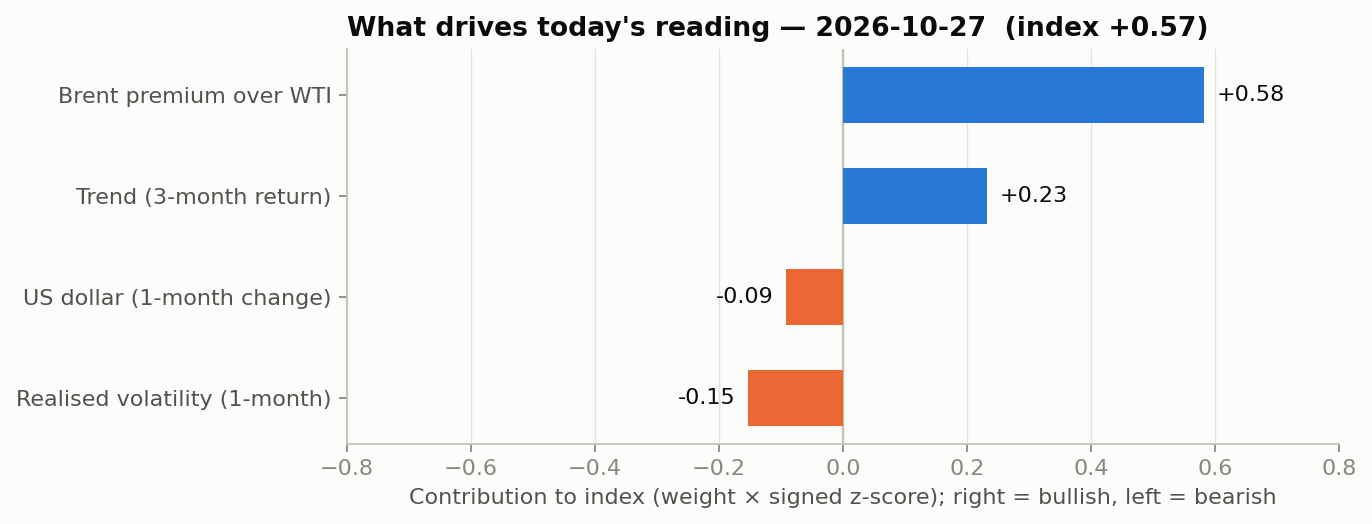

**Reading the drivers chart.** Each bar is one component's contribution to today's index (+0.57); green pushes toward higher prices, red toward lower. The largest pushes are Brent premium over WTI (+2.3 σ, bullish) and Trend (3-month return) (+0.9 σ, bullish). The index sits at the **86th percentile** of its trailing three years, so it sits in the top band (≥ 80), the **bullish** zone.

The one-week view this implies is **+0.67%** (WTI 103.37 → about 104.06, 80% range 97.56–110.67). Context signal, not a trading recommendation. The one-week view is not statistically distinguishable from a random walk (|DM t| < 2).

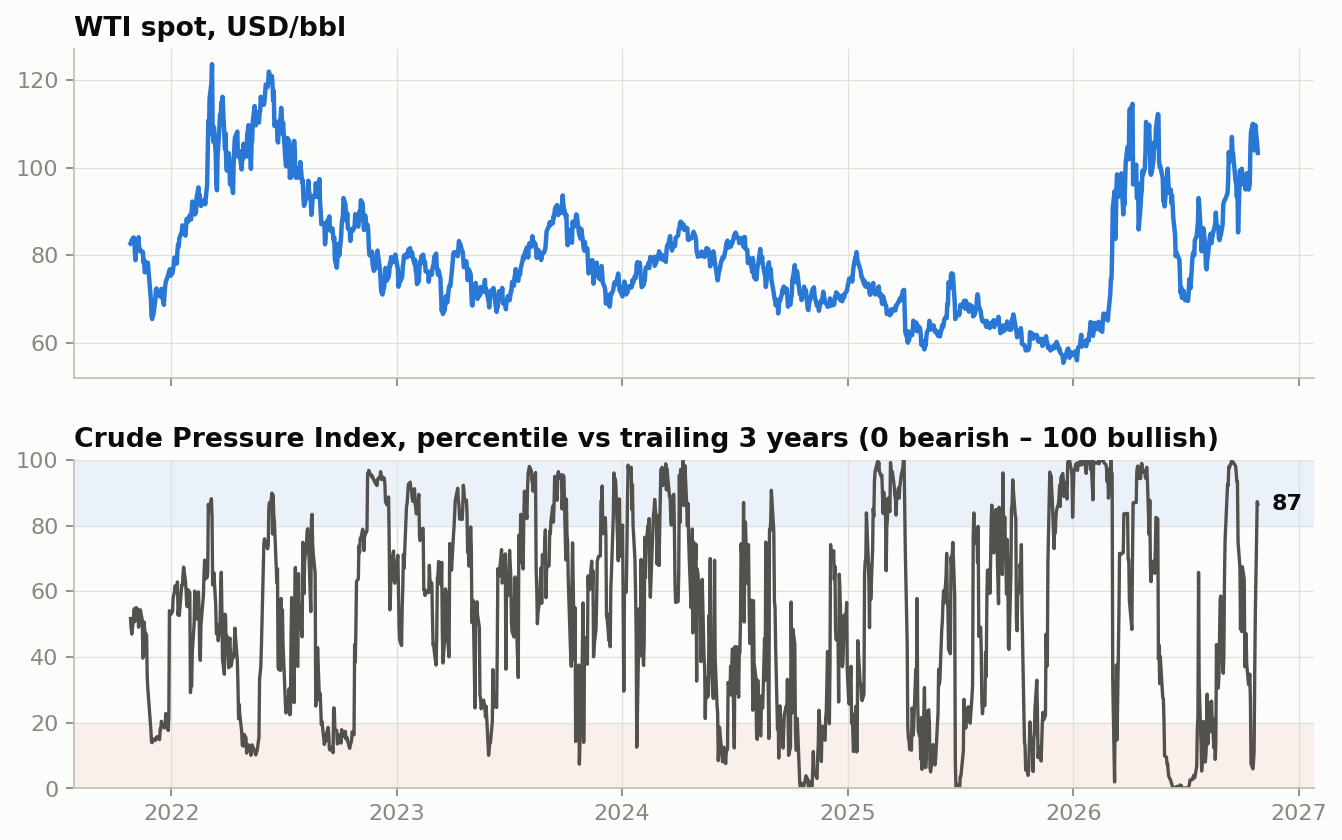

**Reading the history chart.** Over the last five years the index was in the bullish zone on 25% of days and in the bearish zone on 20%. Its highest reading was on 2026-03-03 and its lowest on 2026-07-06. Over the last 21 trading days it moved +0.49, so pressure is currently building. A level only means something relative to its own trailing history, which is why the zones use percentiles, not fixed thresholds. The index describes pressure on prices; it is not a price forecast on its own.

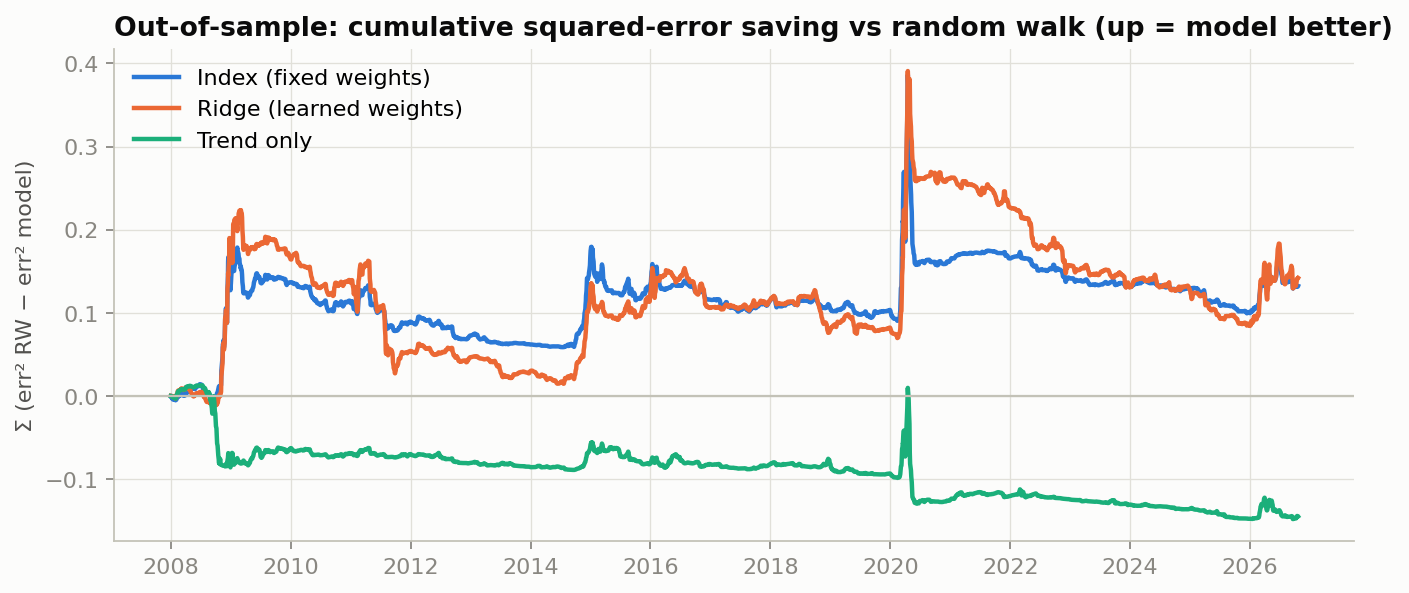

**Reading the skill chart.** The line adds up the squared-error saving of the index model over a random walk; a rising line means the model beat "no change", a falling line means it lost. Over the full out-of-sample period the one-week out-of-sample R² is **0.69%** with a hit rate of 52.2% and rank correlation 0.027; against the random walk it is not distinguishable from the baseline (t = 0.5, inside ±2). It beat the random walk in 6 of 19 calendar years (best 2014: +29.0%, worst 2012: -6.4%). A line that gains in a few bursts and is flat elsewhere means the result depends on a few episodes, not on steady skill.

In [32]:
OUT = Path(os.environ["NOWCAST_OUT_DIR"])
payload = write_all(OUT, panel, feats, y, preds, coefs, qc, metrics, by_year, pit)
from nowcastlab import commentary as C
reading = C.crude(payload, feats, metrics, by_year)
for f, key in [("chart_latest_drivers.png", "drivers"), ("chart_index_history.png", "history"), ("chart_oos_skill.png", "skill")]:
    display(Image(str(OUT / f)))
    C.show(reading[key])          # written analysis of the chart above, built from this run's numbers

In [33]:
import json
print(json.dumps(payload, indent=2))
print(sorted(p.name for p in OUT.iterdir()))

{
  "product": "nowcastlab.crude_pressure_index",
  "version": "0.1.0",
  "as_of_close": "2026-10-27",
  "data_vintage": {
    "wti": "2026-10-27",
    "brent": "2026-10-27",
    "fx": "2026-10-23"
  },
  "index": {
    "value": 0.569,
    "percentile_3y": 86.5,
    "reading": "bullish"
  },
  "drivers": [
    {
      "component": "brent_premium",
      "label": "Brent premium over WTI",
      "signed_z": 2.33,
      "weight": 0.25,
      "contribution": 0.583,
      "direction": "bullish"
    },
    {
      "component": "trend_63d",
      "label": "Trend (3-month return)",
      "signed_z": 0.93,
      "weight": 0.25,
      "contribution": 0.233,
      "direction": "bullish"
    },
    {
      "component": "vol_20d",
      "label": "Realised volatility (1-month)",
      "signed_z": -0.61,
      "weight": 0.25,
      "contribution": -0.153,
      "direction": "bearish"
    },
    {
      "component": "usd_20d",
      "label": "US dollar (1-month change)",
      "signed_z": -0.37,
     

To reproduce what the pipeline would have said on a past date: `!python run.py --as-of 2020-03-16`

## 7. Alternative data (experimental — needs Internet)

Free data beyond price, tested the same way as the index but **not** part of it. Every sign was fixed before testing; release rules are conservative.

| Group | Signal | Source | Rule used | Sign |
|---|---|---|---|---|
| logistics | Hormuz and Bab el-Mandeb tanker calls, 7d vs 90d | IMF PortWatch (ship tracking) | obs + 10 days | fewer = bullish |
| eia_weekly | US crude stocks / refinery utilisation / product supplied vs 5-yr seasonal | EIA weekly report via FRED | obs + 6 days (Thursday close) | stocks above norm bearish; utilisation, demand above norm bullish |
| positioning | Managed-money net length, % of open interest | CFTC Commitments of Traders | Tuesday data, usable the next Monday | crowded long = bearish (contrarian) |
| retail_margins | Gasoline and diesel pump price x 42 minus WTI, vs seasonal | EIA retail prices via FRED | obs + 1 day | fat margin = bullish |
| rigs | US oil rigs, 13-week change | Baker Hughes — **attach a CSV** `bakerhughes_oil_rigs.csv` (columns `date,oil_rigs`); no stable keyless download found | obs + 3 days | more rigs = bearish |
| balances | Global crude output and stocks, like-for-like y/y | JODI Oil World Database (monthly). Auto-download with Internet on; or attach the *Extended Primary CSV* annual files (`2010.csv` … `2025.csv`, `primaryyear2026.csv`) | month end + 45 days | rising = bearish |
| news (live only) | Oil news volume and tone | GDELT — its search API keeps only ~3 months, so this is shown on the dashboard but **never backtested** | n/a | n/a |

Output: per-signal rank IC and HAC t-stat next to the index over the same window, with a Bonferroni-adjusted p-value for the number of signals × horizons tested; plus an incremental walk-forward test per group and for all signals (index vs index + equal-weight block, identical dates).
**Read |t| < 2 as no evidence, and trust `p_bonferroni`, not the raw t-stat.** Any source that can't be reached is reported and skipped; the rest of the notebook is unaffected. The GDELT call waits ~12 s (its rate limit).

**Troubleshooting.** *FRED times out:* it retries 3 times; if it still fails, on fred.stlouisfed.org/series/WCESTUS1 (and `WPULEUS3`, `WRPUPUS2`, `GASREGW`, `GASDESW`) choose Download > CSV and attach the files (keep the names `WCESTUS1.csv` etc.) as a dataset; they are picked up automatically. *PortWatch error:* it tries three query shapes and lists what each returned. *Old results after re-importing the notebook:* use Run > Restart session and run all.

In [34]:
from run_altdata import run
alt_res = run()
alt = (alt_res['z'], alt_res['features'], alt_res.get('gdelt')) if alt_res else None

  alt source product_supplied: failed: TimeoutError: The read operation timed out | fallback: on fred.stlouisfed.org/series/WRPUPUS2 choose Download > CSV and attach the file (named WRPUPUS2.csv) as a dataset
  alt source jodi: attached
  alt source crude_stocks: failed: TimeoutError: The read operation timed out | fallback: on fred.stlouisfed.org/series/WCESTUS1 choose Download > CSV and attach the file (named WCESTUS1.csv) as a dataset
  alt source refinery_util: failed: TimeoutError: The read operation timed out | fallback: on fred.stlouisfed.org/series/WPULEUS3 choose Download > CSV and attach the file (named WPULEUS3.csv) as a dataset
  alt source diesel_retail: failed: TimeoutError: The read operation timed out | fallback: on fred.stlouisfed.org/series/GASDESW choose Download > CSV and attach the file (named GASDESW.csv) as a dataset
  alt source portwatch: failed: RuntimeError: PortWatch: RuntimeError: Cannot perform query. Invalid query parameters. | RuntimeError: Cannot perfor

In [35]:
from nowcastlab import commentary as C
C.show(C.altdata(alt_res))   # what the tables above mean, with the multiple-testing caveat

**What the alternative-data tables say.**
- **Coverage:** 3 sources loaded; see the quality table for any with flags (stale, gaps, few observations).
- **Signal tests:** 6 signal × horizon combinations were tested. 0 have |t| ≥ 2 on their own, but with this many tests about 1 would pass by chance. After Bonferroni adjustment **none** remain, so no single signal is proven to carry information.
- **Strongest unadjusted:** jodi_production_yoy at 20d (IC +0.04, t -1.6, adj. p 0.69); jodi_production_yoy at 5d (IC +0.02, t -1.5, adj. p 0.77); jodi_stocks_yoy at 20d (IC +0.04, t +1.2, adj. p 1.00).
- **Does adding them help the one-week view?** All signals together change out-of-sample R² by **-0.70 points** (from -0.41% to -1.11%). No block both improves R² and reaches t > 2, so none is adopted into the index.

Rule of thumb: a signal is only worth adopting if it survives the multiple-testing adjustment **and** improves the incremental test. Everything else stays on the watch-list.

## 8. Macro nowcasts and market indices (inflation, labour, conditions)

Same discipline as the crude index: every series has a **release rule** (nothing is used before it was published), windows are **trailing only**, **baselines come first**, tests are **walk-forward**, and the Covid months are reported separately instead of silently dropped.

| Product | Target / output | Free data | Baselines | Test |
|---|---|---|---|---|
| **Inflation nowcast** | US CPI-U m/m % (NSA) for the current month, made at month end (and mid-month) | CPI (GitHub `datasets/cpi-us`, no FRED needed), WTI, Brent, Fed dollar index; pump gasoline (FRED `GASREGW`) when available | seasonal mean (same month, prior 5 yrs) · last published · trailing 12m | walk-forward from 2008; RMSE vs anchor, Diebold–Mariano t |
| **Labour nowcast** | Payroll growth and unemployment-rate change for the month, before the jobs report | Weekly jobless claims (FRED `ICSA`, `CCSA`), payrolls, unemployment rate | trailing 12m mean · last published · seasonal | same |
| **Labour Pulse** | Weekly index (0–100 vs trailing 3 years): claims vs a year ago, unemployment trend | FRED `ICSA`, `CCSA`, `UNRATE` | – | correlation with the month's payroll growth / unemployment change |
| **Market conditions index** | Daily stress index (0–100; high = stress): VIX, Baa–10y spread, yield-curve slope, dollar | FRED `VIXCLS`, `BAA10Y`, `T10Y2Y`, `DTWEXBGS` | VIX alone, published NFCI | correlation with Chicago Fed NFCI; rank IC and drawdown odds vs S&P 500 (`SP500`) over the next 21 days |

**Release rules used:** CPI month-end + 17 days · jobs report month-end + 8 days · initial claims Saturday + 5 days (Thursday release) · continuing claims + 12 days · daily market series + 1 day · NFCI Friday + 5 days · pump prices + 1 day. Payrolls and unemployment are the **latest vintage** (revised), so their tests are slightly flattering; ALFRED vintages (needs the FRED API key) would remove that.

**How to read it:** a nowcast beats its baseline only if its **Diebold–Mariano t > 2** in the "excluding 2020-03..2021-06" table. If a FRED series times out, the status line says which and how to attach the CSV; the families that don't need it still run.

In [36]:
from run_macro import run as run_macro
macro_res = run_macro()

data status: {'unrate': 'ok', 'baa10y': 'ok', 'payems': 'ok', 'gasoline': 'ok', 'dollar': 'ok', 'cpi': 'ok', 'icsa': 'ok', 'vix': 'ok', 'ccsa': 'ok', 't10y2y': 'ok', 'sp500': 'ok', 'nfci': 'ok'}

== inflation: walk-forward vs baselines (DM t > 2 = significantly better than the anchor)
            model   n   rmse    mae  rmse_vs_anchor_%  dm_t_vs_anchor  corr_surprise
seasonal (anchor) 206 0.3398 0.2416               0.0             NaN            NaN
   last_published 206 0.3684 0.2730               8.4           -0.86          0.496
     trailing_12m 206 0.3842 0.2793              13.1           -2.10          0.275
         ols_main 206 0.2413 0.1932             -29.0            3.01          0.709
        ridge_all 206 0.2413 0.1909             -29.0            3.03          0.708
   live: 2026-10 nowcast +0.30 (made 2026-10-27); baselines {'seasonal': 0.327, 'last_published': 0.318, 'trailing_12m': 0.332}

== inflation_mid: walk-forward vs baselines (DM t > 2 = significantly bette

In [37]:
from nowcastlab.macro_report import figures
from nowcastlab import commentary as C
reading = C.macro(macro_res)
for name, fig in figures(macro_res):
    fig.show(config={'displaylogo': False})
    C.show(reading.get(name, ''))      # analysis of the chart just shown

**Reading the CPI chart.** Black is what was published, the dotted line is the baseline (seasonal), blue is the nowcast made using only data available at the time. Excluding Covid, the nowcast's error is **-29%** versus the baseline over 206 months (negative = smaller error), and statistically it is significantly better (t = 3.0). Made at mid-month, with less information, the figure is -29% (t = 3.1). The largest misses in the plotted window were Mar 2016 (actual +0.43%, nowcast +1.08%) and Jun 2022 (actual +1.36%, nowcast +0.74%). During the 2021–23 inflation surge the nowcast was on average 0.24 points too low per month: the model only captures how energy prices pass through to CPI, so inflation driven by rents and core goods is outside what it can see. 

**Today:** the nowcast for 2026-10 is **+0.30%** against a baseline of +0.33%, a gap of -0.03. That gap is small relative to the typical miss, so treat it as a tilt, not a call.

**Reading the drivers chart.** Bars show how much each input moves this month's CPI nowcast away from its starting point; green bars push it up, red bars pull it down. The biggest single input is **Pump gasoline, month-to-date change** (-0.05), then Brent crude, month-to-date change (+0.03). Together the inputs add up to -0.04.

**Reading the payroll growth chart.** Black is what was published, the dotted line is the baseline (trailing 12m), blue is the nowcast made using only data available at the time. Excluding Covid, the nowcast's error is **+66%** versus the baseline over 209 months (negative = smaller error), and statistically it is significantly worse (t = -2.1). The largest misses in the plotted window were Apr 2020 [Covid window] (actual -14.58%, nowcast -3.68%) and May 2020 [Covid window] (actual +1.98%, nowcast -2.80%). Payroll values are the latest revised figures, which flatters the test slightly. 

**Today:** the nowcast for 2026-10 is **+0.04%** against a baseline of +0.03%, a gap of +0.02. That gap is small relative to the typical miss, so treat it as a tilt, not a call.

**Reading the unemployment-rate change chart.** Black is what was published, the dotted line is the baseline (trailing 12m), blue is the nowcast made using only data available at the time. Excluding Covid, the nowcast's error is **+28%** versus the baseline over 207 months (negative = smaller error), and statistically it is significantly worse (t = -2.4). The largest misses in the plotted window were Apr 2020 [Covid window] (actual +10.40 pp, nowcast +2.64 pp) and May 2020 [Covid window] (actual -1.60 pp, nowcast +2.01 pp). Unemployment values are the latest revised figures. 

**Today:** the nowcast for 2026-10 is **-0.03 pp** against a baseline of -0.02 pp, a gap of -0.02. That gap is small relative to the typical miss, so treat it as a tilt, not a call.

**Reading the Labour Pulse chart.** The line is today's labour-market strength measured against the previous three years (0 = weakest, 100 = strongest). On 2026-10-26 it stands at **94**, so it sits in the top band (≥ 80), the **strong** zone. Checked against the month's actual outcome, it lines up with payroll growth (correlation +0.17, weak) and the change in unemployment (correlation -0.16, weak). This is a coincident gauge built from jobless claims, not a forecast; a rapid rise in claims lowers it within weeks.

**Reading the drivers chart.** Bars show how much each input moves the Labour Pulse away from its starting point; green (stronger labour market) bars push it up, red (weaker) bars pull it down. The biggest single input is **Continuing claims vs a year ago** (+0.80), then Initial claims vs a year ago (+0.70). Together the inputs add up to +1.59.

**Reading the market conditions chart.** Top panel: the transparent stress index (higher = more stress) next to the Chicago Fed's NFCI. On 2026-10-30 the index is at the **72th percentile** of three years, so it sits in the middle of its range, which we label **neutral**. Against the published NFCI over 1349 weeks the correlation is **0.41** in levels and 0.30 in 4-week changes: only a loose agreement, so the two are measuring somewhat different things. Bottom panel and test: in the most stressed fifth of days the S&P 500 returned +1.61% over the next month versus +0.86% in the calmest fifth, and the chance of a drop over 5% was 23% versus 11% (HAC t = +0.6, p = 0.52). VIX alone gives t = -0.9, so the combined index is not clearly better than VIX by itself. Drawdown odds rise with stress as expected, and the link to returns is not significant, so use the index as risk context, not as a directional signal.

**Reading the drivers chart.** Bars show how much each input moves the stress index away from its starting point; red (more stress) bars push it up, green (calmer) bars pull it down. The biggest single input is **Credit spread (Baa - 10y)** (-0.36), then Broad dollar, 1-month change (+0.12). Together the inputs add up to -0.32.

## 9. Combined view: crude + alternative data + macro backdrop

One multi-panel timeline with everything on the same date axis, so a price move can be read against the physical, positioning, macro and market signals at the same time.

| Figure | What it answers |
|---|---|
| **Timeline** (7 panels) | Price and events → Crude Pressure Index → heatmap of every alternative-data signal (blue bullish, orange bearish) → their composite against the index → market stress → Labour Pulse → CPI nowcast |
| **Scoreboard** | Where each family stands today as a percentile of its own last three years, and whether the crude-facing families agree |
| **Correlation map** | Which pieces move together week to week, and which carry independent information |

Alternative data is shown **next to** the index, never mixed into it. Families without data in this run are left out automatically. Saved as `combined_dashboard.html`.

In [38]:
from nowcastlab.combined import build_combined, save_combined
from nowcastlab.dashboard import load_events
from nowcastlab import commentary as C

alt_z = alt[0] if alt else None
macro = globals().get("macro_res")
figs, summ = build_combined(panel, feats, preds, alt_z=alt_z, macro_res=macro, events=load_events())
reading = C.combined(summ)
for fig, key in zip(figs, ["timeline", "scoreboard", "correlations"]):
    fig.show(config={"displaylogo": False})
    C.show(reading.get(key, ""))
print("saved", save_combined(OUT / "combined_dashboard.html", figs, reading, summ))

**Reading the combined timeline.** All panels share one date axis, so you can look straight down from a price move to see what else was happening. Top to bottom: price (with context events), the Crude Pressure Index, the alternative-data signals (each row one signal, blue = bullish for crude, orange = bearish), their combined average against the index, then the macro backdrop (market stress, labour, inflation). Today the crude index is at the **87th percentile** (bullish). The alternative-data composite, built from 2 signals, is at the **99th percentile** (bullish). Only one group has data: balances (+2.8 σ). The alt-data composite sits 2.2 σ above the price-based index: physical and positioning data lean more bullish than price, which is a divergence worth watching, not a trade signal.

Backdrop: market stress is **neutral** (72); the labour market reads **strong** (94); the CPI nowcast (+0.30% for 2026-10) is **neutral** versus the last ten years (57th percentile). These sit beside the crude view as context; they are not inputs to it.

**Reading the scoreboard.** Each bar is the family's current reading as a percentile of its own last three years (the shaded edges are the top and bottom 20% bands). The two crude-facing families **agree**: both are bullish. Agreement between independent sources raises confidence somewhat, but both are context signals and the one-week view has no proven edge over a random walk. Unusual readings in the backdrop: Labour Pulse (94, strong). 

**Reading the correlation map.** Each cell is the correlation between weekly *changes* of two measures over the period shown (1 = move together, −1 = move opposite, near 0 = unrelated). The strongest link is **Crude index and Market stress** at -0.21. 7 of 10 pairs are close to zero, which is a reminder that these families mostly carry different information; that is the reason to look at them together. This is descriptive and contemporaneous: it shows what moved together, not what leads. Correlations also shift between calm and stressed markets.

saved /kaggle/working/outputs/combined_dashboard.html


## 10. Live dashboard

Interactive: hover for values, drag to zoom, double-click to reset, range buttons top-right. Also saved as a self-contained `outputs/dashboard.html` (download from the Output tab and open in any browser, no internet needed).

**Keeping it live on Kaggle** (Kaggle can't host an always-on web app, so "live" = re-run on a schedule):
1. Settings → **Internet → On** (each run then downloads the latest public data; an attached dataset is used only as an offline fallback).
2. **Save Version → Save & Run All (Commit)**.
3. In the notebook editor, open **Schedule** (notebook scheduling) → *Daily*. Kaggle limits how many runs a schedule makes (users report about 10), after which you simply re-enable it.
4. Each scheduled run re-executes everything — data pull, QC, index, walk-forward model, look-ahead check — and the saved version's output (this dashboard and `dashboard.html`) is replaced. Make the notebook public to share the link.

Freshness: the source mirrors (EIA spot via `datasets/oil-prices`, Fed H.10 via `datasets/exchange-rates`) update with a lag of a few days; the header shows the exact vintage used for each source.

In [39]:
from nowcastlab.dashboard import show_dashboard, save_dashboard, load_events
events = load_events()   # context markers only
show_dashboard(panel, feats, preds, y, payload, metrics, pit, qc, events=events, alt=alt)
print('saved', save_dashboard(OUT / 'dashboard.html', panel, feats, preds, y, payload, metrics, pit, qc, events=events, alt=alt))
from nowcastlab.macro_report import save_macro_dashboard
print('saved', save_macro_dashboard(macro_res, OUT / 'macro_dashboard.html'))

saved /kaggle/working/outputs/dashboard.html
saved /kaggle/working/outputs/macro_dashboard.html


In [40]:
from nowcastlab import commentary as C
C.show(C.DASHBOARD_GUIDE)

**How to read the dashboards.**

- **Hover** any line for the exact value on that date; **drag** to zoom, **double-click** to reset, use the range buttons for 1m / 6m / 1y / all.
- **Index percentile (0–100)** compares today with the trailing three years only. Above 80 is the top band, below 20 the bottom band; it is a ranking, not a forecast.
- **Diamonds** mark live nowcasts for a month that has not been published yet. Nothing after the last actual is scored.
- **Baselines come first.** A nowcast earns attention only if its Diebold–Mariano t is above 2 against the baseline; below that, treat it as context.
- **Data lag.** Every series appears only from its publication date, so the latest points on weekly and monthly charts are older than the daily ones.
- Everything is context for analysts, not a recommendation to trade.